# HeartTrialTwin: Heart-Failure Clinical Trial Cohort

## Project Goal
HeartTrialTwin is a condition-specific clinical-trial intelligence project focused on heart failure.

The project will use historical clinical-trial data to:
- characterize the heart-failure treatment landscape,
- identify trial-design factors associated with termination, withdrawal, or unusually long completion time,
- retrieve comparable historical trials,
- and support trial-level what-if simulation.

## Initial Cohort
The initial cohort will include interventional studies related to heart failure.

Where supported by the data, trials will be categorized as:
- HFrEF — Heart Failure with Reduced Ejection Fraction
- HFmrEF — Heart Failure with Mildly Reduced Ejection Fraction
- HFpEF — Heart Failure with Preserved Ejection Fraction
- General or unspecified heart failure

## Important Modeling Rule
For prediction, only variables available at or near trial registration will be considered as candidate predictors.

Later-updated information, reported outcomes, reasons for stopping, and other post-registration information will not be used as prediction features.

## Current Notebook Objective
This notebook will:
1. Build the heart-failure trial cohort.
2. Explore trial statuses and dates.
3. Identify heart-failure subtypes.
4. Examine interventions and treatment classes.
5. Examine trial phases and trial-design characteristics.
6. Assess missingness and potential data leakage.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
!pip install psycopg2-binary -q

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.3/4.3 MB 38.6 MB/s eta 0:00:00


In [3]:
import psycopg2
from getpass import getpass

In [4]:
AACT_USER = input("Enter your AACT username: ")
AACT_PASSWORD = getpass("Enter your AACT password: ")

conn = psycopg2.connect(
    host="aact-db.ctti-clinicaltrials.org",
    port=5432,
    dbname="aact",
    user=AACT_USER,
    password=AACT_PASSWORD,
    sslmode="require"
)

print("Connected to AACT successfully!")

Enter your AACT username: obedaning
Enter your AACT password: ··········
Connected to AACT successfully!


In [5]:
test_query = """
SELECT
    nct_id,
    brief_title,
    overall_status,
    study_type
FROM ctgov.studies
LIMIT 5;
"""

test_df = pd.read_sql_query(test_query, conn)

test_df

/tmp/ipykernel_1697/352568032.py:11: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  test_df = pd.read_sql_query(test_query, conn)


,nct_id,brief_title,overall_status,study_type
0,NCT04321720,Dose-response Relationship of Mustard Flour Fo...,COMPLETED,INTERVENTIONAL
1,NCT02559908,A Study of Hyaluronic Acid Injectable Gel (VYC...,COMPLETED,INTERVENTIONAL
2,NCT02493127,The Effect of Priming of Questionnaire Content...,COMPLETED,INTERVENTIONAL
3,NCT04019847,STAK Tool for Treatment of Arthrofibrosis Post...,COMPLETED,INTERVENTIONAL
4,NCT01173393,Rapid Infusion of Cold Normal Saline During CP...,COMPLETED,INTERVENTIONAL


In [6]:
!pip install sqlalchemy -q

In [7]:
from sqlalchemy import create_engine
from urllib.parse import quote_plus

encoded_password = quote_plus(AACT_PASSWORD)

engine = create_engine(
    f"postgresql+psycopg2://{AACT_USER}:{encoded_password}"
    "@aact-db.ctti-clinicaltrials.org:5432/aact"
)

In [8]:
test_df = pd.read_sql_query(test_query, engine)

test_df

,nct_id,brief_title,overall_status,study_type
0,NCT04321720,Dose-response Relationship of Mustard Flour Fo...,COMPLETED,INTERVENTIONAL
1,NCT02559908,A Study of Hyaluronic Acid Injectable Gel (VYC...,COMPLETED,INTERVENTIONAL
2,NCT02493127,The Effect of Priming of Questionnaire Content...,COMPLETED,INTERVENTIONAL
3,NCT04019847,STAK Tool for Treatment of Arthrofibrosis Post...,COMPLETED,INTERVENTIONAL
4,NCT01173393,Rapid Infusion of Cold Normal Saline During CP...,COMPLETED,INTERVENTIONAL


In [9]:
from sqlalchemy import text

heart_failure_query = text("""
SELECT DISTINCT
    s.nct_id,
    s.brief_title,
    s.overall_status,
    s.phase,
    s.enrollment,
    s.start_date,
    s.completion_date,
    c.name AS condition_name,
    bc.mesh_term
FROM ctgov.studies s
LEFT JOIN ctgov.conditions c
    ON s.nct_id = c.nct_id
LEFT JOIN ctgov.browse_conditions bc
    ON s.nct_id = bc.nct_id
WHERE s.study_type = 'INTERVENTIONAL'
  AND (
       LOWER(c.name) LIKE :hf_term
       OR LOWER(bc.mesh_term) LIKE :hf_term
  );
""")

hf_candidates = pd.read_sql_query(
    heart_failure_query,
    engine,
    params={"hf_term": "%heart failure%"}
)

hf_candidates.head()

,nct_id,brief_title,overall_status,phase,enrollment,start_date,completion_date,condition_name,mesh_term
0,NCT00000475,Prevention of Early Readmission in Elderly Con...,COMPLETED,PHASE2,NaN,1990-04-30,1995-03-31,Cardiovascular Diseases,Heart Failure
1,NCT00000475,Prevention of Early Readmission in Elderly Con...,COMPLETED,PHASE2,NaN,1990-04-30,1995-03-31,Heart Diseases,Heart Failure
2,NCT00000475,Prevention of Early Readmission in Elderly Con...,COMPLETED,PHASE2,NaN,1990-04-30,1995-03-31,Heart Failure,Cardiovascular Diseases
3,NCT00000475,Prevention of Early Readmission in Elderly Con...,COMPLETED,PHASE2,NaN,1990-04-30,1995-03-31,Heart Failure,Heart Diseases
4,NCT00000475,Prevention of Early Readmission in Elderly Con...,COMPLETED,PHASE2,NaN,1990-04-30,1995-03-31,Heart Failure,Heart Failure


In [10]:
print("Rows returned:", len(hf_candidates))
print("Unique trials:", hf_candidates["nct_id"].nunique())

Rows returned: 34251
Unique trials: 4740


In [11]:
hf_candidates[
    ["nct_id", "condition_name", "mesh_term"]
].head(20)

,nct_id,condition_name,mesh_term
0,NCT00000475,Cardiovascular Diseases,Heart Failure
1,NCT00000475,Heart Diseases,Heart Failure
2,NCT00000475,Heart Failure,Cardiovascular Diseases
3,NCT00000475,Heart Failure,Heart Diseases
4,NCT00000475,Heart Failure,Heart Failure
5,NCT00000475,"Heart Failure, Congestive",Cardiovascular Diseases
6,NCT00000475,"Heart Failure, Congestive",Heart Diseases
7,NCT00000475,"Heart Failure, Congestive",Heart Failure
8,NCT00000476,Arrhythmia,Heart Failure
9,NCT00000476,Cardiovascular Diseases,Heart Failure


In [12]:
hf_one_row = (
    hf_candidates
    .groupby(
        [
            "nct_id",
            "brief_title",
            "overall_status",
            "phase",
            "enrollment",
            "start_date",
            "completion_date"
        ],
        dropna=False
    )
    .agg(
        condition_names=("condition_name", lambda x: sorted(set(x.dropna()))),
        mesh_terms=("mesh_term", lambda x: sorted(set(x.dropna())))
    )
    .reset_index()
)

print("Rows after collapsing:", len(hf_one_row))
print("Unique trials:", hf_one_row["nct_id"].nunique())

hf_one_row.head()

Rows after collapsing: 4740
Unique trials: 4740


,nct_id,brief_title,overall_status,phase,enrollment,start_date,completion_date,condition_names,mesh_terms
0,NCT00000475,Prevention of Early Readmission in Elderly Con...,COMPLETED,PHASE2,NaN,1990-04-30,1995-03-31,"[Cardiovascular Diseases, Heart Diseases, Hear...","[Cardiovascular Diseases, Heart Diseases, Hear..."
1,NCT00000476,Digitalis Investigation Group (DIG),COMPLETED,PHASE3,NaN,1990-06-30,1998-06-30,"[Arrhythmia, Cardiovascular Diseases, Heart Di...","[Arrhythmia, Sinus, Arrhythmias, Cardiac, Card..."
2,NCT00000516,Studies of Left Ventricular Dysfunction (SOLVD),COMPLETED,PHASE3,NaN,1985-07-31,1990-05-31,"[Cardiovascular Diseases, Coronary Disease, He...","[Cardiovascular Diseases, Coronary Disease, He..."
3,NCT00000542,Antihypertensive and Lipid-Lowering Treatment ...,COMPLETED,PHASE3,NaN,1993-08-31,2002-03-31,"[Cardiovascular Diseases, Coronary Disease, Di...","[Cardiovascular Diseases, Coronary Disease, Di..."
4,NCT00000547,Enalapril After Anthracycline Cardiotoxicity,COMPLETED,PHASE3,NaN,1994-04-30,2001-02-28,"[Cardiovascular Diseases, Heart Diseases, Hear...","[Cardiomyopathies, Cardiovascular Diseases, He..."


In [13]:
status_counts = (
    hf_one_row["overall_status"]
    .value_counts(dropna=False)
    .reset_index()
)

status_counts.columns = ["overall_status", "count"]

status_counts["percentage"] = (
    status_counts["count"] / len(hf_one_row) * 100
).round(2)

status_counts

,overall_status,count,percentage
0,COMPLETED,2377,50.15
1,UNKNOWN,730,15.40
2,RECRUITING,548,11.56
3,TERMINATED,417,8.80
4,NOT_YET_RECRUITING,250,5.27
5,WITHDRAWN,208,4.39
6,ACTIVE_NOT_RECRUITING,145,3.06
7,ENROLLING_BY_INVITATION,43,0.91
8,SUSPENDED,22,0.46


In [14]:
phase_counts = (
    hf_one_row["phase"]
    .value_counts(dropna=False)
    .reset_index()
)

phase_counts.columns = ["phase", "count"]

phase_counts["percentage"] = (
    phase_counts["count"] / len(hf_one_row) * 100
).round(2)

phase_counts

,phase,count,percentage
0,NA,2732,57.64
1,PHASE4,559,11.79
2,PHASE2,495,10.44
3,PHASE3,433,9.14
4,PHASE1,231,4.87
5,PHASE1/PHASE2,129,2.72
6,PHASE2/PHASE3,115,2.43
7,EARLY_PHASE1,46,0.97


In [15]:
status_by_phase = pd.crosstab(
    hf_one_row["phase"],
    hf_one_row["overall_status"],
    margins=True
)

status_by_phase

overall_status,ACTIVE_NOT_RECRUITING,COMPLETED,ENROLLING_BY_INVITATION,NOT_YET_RECRUITING,RECRUITING,SUSPENDED,TERMINATED,UNKNOWN,WITHDRAWN,All
phase,,,,,,,,,,
EARLY_PHASE1,1,26,0,1,7,0,2,6,3,46
NA,106,1305,31,187,362,11,186,431,113,2732
PHASE1,3,138,1,5,23,2,19,26,14,231
PHASE1/PHASE2,6,60,1,9,8,1,10,24,10,129
PHASE2,11,286,3,9,45,4,68,44,25,495
PHASE2/PHASE3,0,60,0,2,12,2,12,25,2,115
PHASE3,9,229,2,15,45,1,57,61,14,433
PHASE4,9,273,5,22,46,1,63,113,27,559
All,145,2377,43,250,548,22,417,730,208,4740


In [16]:
status_by_phase_pct = pd.crosstab(
    hf_one_row["phase"],
    hf_one_row["overall_status"],
    normalize="index"
) * 100

status_by_phase_pct = status_by_phase_pct.round(1)

status_by_phase_pct

overall_status,ACTIVE_NOT_RECRUITING,COMPLETED,ENROLLING_BY_INVITATION,NOT_YET_RECRUITING,RECRUITING,SUSPENDED,TERMINATED,UNKNOWN,WITHDRAWN
phase,,,,,,,,,
EARLY_PHASE1,2.2,56.5,0.0,2.2,15.2,0.0,4.3,13.0,6.5
NA,3.9,47.8,1.1,6.8,13.3,0.4,6.8,15.8,4.1
PHASE1,1.3,59.7,0.4,2.2,10.0,0.9,8.2,11.3,6.1
PHASE1/PHASE2,4.7,46.5,0.8,7.0,6.2,0.8,7.8,18.6,7.8
PHASE2,2.2,57.8,0.6,1.8,9.1,0.8,13.7,8.9,5.1
PHASE2/PHASE3,0.0,52.2,0.0,1.7,10.4,1.7,10.4,21.7,1.7
PHASE3,2.1,52.9,0.5,3.5,10.4,0.2,13.2,14.1,3.2
PHASE4,1.6,48.8,0.9,3.9,8.2,0.2,11.3,20.2,4.8


In [17]:
hf_ids = tuple(hf_one_row["nct_id"].tolist())

intervention_query = text("""
SELECT
    i.nct_id,
    i.intervention_type,
    i.name AS intervention_name,
    i.description
FROM ctgov.interventions i
WHERE i.nct_id IN :nct_ids
ORDER BY i.nct_id;
""").bindparams(
    __import__("sqlalchemy").bindparam("nct_ids", expanding=True)
)

hf_interventions = pd.read_sql_query(
    intervention_query,
    engine,
    params={"nct_ids": hf_ids}
)

print("Intervention records:", len(hf_interventions))
print("Trials with intervention records:", hf_interventions["nct_id"].nunique())

hf_interventions.head(20)

Intervention records: 8030
Trials with intervention records: 4740


,nct_id,intervention_type,intervention_name,description
0,NCT00000475,BEHAVIORAL,health education,None
1,NCT00000476,DRUG,digitalis,None
2,NCT00000516,DRUG,enalapril,None
3,NCT00000542,DRUG,"Inhibitors, ACE",None
4,NCT00000542,DRUG,amlodipine,None
5,NCT00000542,DRUG,lisinopril,None
6,NCT00000542,DRUG,doxazosin,None
7,NCT00000542,DRUG,chlorthalidone,None
8,NCT00000542,DRUG,pravastatin,None
9,NCT00000542,BEHAVIORAL,"diet, fat-restricted",None


In [18]:
intervention_type_counts = (
    hf_interventions["intervention_type"]
    .value_counts(dropna=False)
    .reset_index()
)

intervention_type_counts.columns = ["intervention_type", "count"]

intervention_type_counts

,intervention_type,count
0,DRUG,3146
1,OTHER,1550
2,DEVICE,1426
3,BEHAVIORAL,834
4,PROCEDURE,533
5,DIAGNOSTIC_TEST,173
6,DIETARY_SUPPLEMENT,160
7,BIOLOGICAL,151
8,COMBINATION_PRODUCT,26
9,RADIATION,17


In [19]:
intervention_trial_counts = (
    hf_interventions
    .groupby("intervention_type")["nct_id"]
    .nunique()
    .reset_index(name="trial_count")
    .sort_values("trial_count", ascending=False)
)

intervention_trial_counts["percentage_of_trials"] = (
    intervention_trial_counts["trial_count"]
    / hf_one_row["nct_id"].nunique()
    * 100
).round(2)

intervention_trial_counts

,intervention_type,trial_count,percentage_of_trials
6,DRUG,1743,36.77
3,DEVICE,1156,24.39
8,OTHER,1072,22.62
0,BEHAVIORAL,602,12.70
9,PROCEDURE,385,8.12
4,DIAGNOSTIC_TEST,118,2.49
1,BIOLOGICAL,111,2.34
5,DIETARY_SUPPLEMENT,104,2.19
2,COMBINATION_PRODUCT,26,0.55
10,RADIATION,16,0.34


In [20]:
drug_indicator = (
    hf_interventions
    .assign(
        has_drug=hf_interventions["intervention_type"].eq("DRUG")
    )
    .groupby("nct_id")["has_drug"]
    .max()
    .reset_index()
)

hf_phase_check = hf_one_row.merge(
    drug_indicator,
    on="nct_id",
    how="left"
)

hf_phase_check["has_drug"] = (
    hf_phase_check["has_drug"]
    .fillna(False)
    .astype(bool)
)

phase_by_drug = pd.crosstab(
    hf_phase_check["has_drug"],
    hf_phase_check["phase"],
    margins=True
)

phase_by_drug

phase,EARLY_PHASE1,NA,PHASE1,PHASE1/PHASE2,PHASE2,PHASE2/PHASE3,PHASE3,PHASE4,All
has_drug,,,,,,,,,
False,19,2515,70,60,96,43,92,102,2997
True,27,217,161,69,399,72,341,457,1743
All,46,2732,231,129,495,115,433,559,4740


In [21]:
summary_query = text("""
SELECT
    bs.nct_id,
    bs.description AS brief_summary
FROM ctgov.brief_summaries bs
WHERE bs.nct_id IN :nct_ids;
""").bindparams(
    __import__("sqlalchemy").bindparam("nct_ids", expanding=True)
)

hf_summaries = pd.read_sql_query(
    summary_query,
    engine,
    params={"nct_ids": hf_ids}
)

print("Summary records:", len(hf_summaries))
print("Trials with summaries:", hf_summaries["nct_id"].nunique())

hf_summaries.head()

Summary records: 4740
Trials with summaries: 4740


,nct_id,brief_summary
0,NCT00000475,To assess the impact of a multidisciplinary tr...
1,NCT00000476,"To determine if digitalis had a beneficial, ha..."
2,NCT00000516,To determine if enalapril treatment of left ve...
3,NCT00000542,To determine if the combined incidence of nonf...
4,NCT00000547,To determine if the chronic administration of ...


In [22]:
hf_cohort = hf_one_row.merge(
    hf_summaries,
    on="nct_id",
    how="left"
)

print("Rows:", len(hf_cohort))
print("Unique trials:", hf_cohort["nct_id"].nunique())
print("Missing summaries:", hf_cohort["brief_summary"].isna().sum())

hf_cohort.head()

Rows: 4740
Unique trials: 4740
Missing summaries: 0


,nct_id,brief_title,overall_status,phase,enrollment,start_date,completion_date,condition_names,mesh_terms,brief_summary
0,NCT00000475,Prevention of Early Readmission in Elderly Con...,COMPLETED,PHASE2,NaN,1990-04-30,1995-03-31,"[Cardiovascular Diseases, Heart Diseases, Hear...","[Cardiovascular Diseases, Heart Diseases, Hear...",To assess the impact of a multidisciplinary tr...
1,NCT00000476,Digitalis Investigation Group (DIG),COMPLETED,PHASE3,NaN,1990-06-30,1998-06-30,"[Arrhythmia, Cardiovascular Diseases, Heart Di...","[Arrhythmia, Sinus, Arrhythmias, Cardiac, Card...","To determine if digitalis had a beneficial, ha..."
2,NCT00000516,Studies of Left Ventricular Dysfunction (SOLVD),COMPLETED,PHASE3,NaN,1985-07-31,1990-05-31,"[Cardiovascular Diseases, Coronary Disease, He...","[Cardiovascular Diseases, Coronary Disease, He...",To determine if enalapril treatment of left ve...
3,NCT00000542,Antihypertensive and Lipid-Lowering Treatment ...,COMPLETED,PHASE3,NaN,1993-08-31,2002-03-31,"[Cardiovascular Diseases, Coronary Disease, Di...","[Cardiovascular Diseases, Coronary Disease, Di...",To determine if the combined incidence of nonf...
4,NCT00000547,Enalapril After Anthracycline Cardiotoxicity,COMPLETED,PHASE3,NaN,1994-04-30,2001-02-28,"[Cardiovascular Diseases, Heart Diseases, Hear...","[Cardiomyopathies, Cardiovascular Diseases, He...",To determine if the chronic administration of ...


In [23]:
hf_cohort["hf_text"] = (
    hf_cohort["brief_title"].fillna("").astype(str)
    + " "
    + hf_cohort["condition_names"].apply(
        lambda x: " ".join(x) if isinstance(x, list) else ""
    )
    + " "
    + hf_cohort["mesh_terms"].apply(
        lambda x: " ".join(x) if isinstance(x, list) else ""
    )
    + " "
    + hf_cohort["brief_summary"].fillna("").astype(str)
).str.lower()

hf_cohort[
    ["nct_id", "brief_title", "hf_text"]
].head()

,nct_id,brief_title,hf_text
0,NCT00000475,Prevention of Early Readmission in Elderly Con...,prevention of early readmission in elderly con...
1,NCT00000476,Digitalis Investigation Group (DIG),digitalis investigation group (dig) arrhythmia...
2,NCT00000516,Studies of Left Ventricular Dysfunction (SOLVD),studies of left ventricular dysfunction (solvd...
3,NCT00000542,Antihypertensive and Lipid-Lowering Treatment ...,antihypertensive and lipid-lowering treatment ...
4,NCT00000547,Enalapril After Anthracycline Cardiotoxicity,enalapril after anthracycline cardiotoxicity c...


In [24]:
subtype_terms = {
    "HFpEF": [
        "hfpef",
        "heart failure with preserved ejection fraction",
        "preserved ejection fraction"
    ],

    "HFrEF": [
        "hfref",
        "heart failure with reduced ejection fraction",
        "reduced ejection fraction"
    ],

    "HFmrEF": [
        "hfmref",
        "heart failure with mildly reduced ejection fraction",
        "heart failure with mid-range ejection fraction",
        "mid-range ejection fraction",
        "mildly reduced ejection fraction"
    ]
}

for subtype, terms in subtype_terms.items():
    pattern = "|".join(terms)
    count = hf_cohort["hf_text"].str.contains(
        pattern,
        case=False,
        na=False,
        regex=True
    ).sum()

    print(f"{subtype}: {count}")

HFpEF: 416
HFrEF: 467
HFmrEF: 37


In [25]:
hf_cohort["mentions_hfpef"] = hf_cohort["hf_text"].str.contains(
    r"\bhfpef\b|heart failure with preserved ejection fraction|preserved ejection fraction",
    case=False,
    na=False,
    regex=True
)

hf_cohort["mentions_hfref"] = hf_cohort["hf_text"].str.contains(
    r"\bhfref\b|heart failure with reduced ejection fraction|reduced ejection fraction",
    case=False,
    na=False,
    regex=True
)

hf_cohort["mentions_hfmref"] = hf_cohort["hf_text"].str.contains(
    r"\bhfmref\b|heart failure with mildly reduced ejection fraction|heart failure with mid-range ejection fraction|mildly reduced ejection fraction|mid-range ejection fraction",
    case=False,
    na=False,
    regex=True
)

In [26]:
subtype_overlap = (
    hf_cohort
    .groupby(
        ["mentions_hfpef", "mentions_hfref", "mentions_hfmref"]
    )
    .size()
    .reset_index(name="trial_count")
    .sort_values("trial_count", ascending=False)
)

subtype_overlap

,mentions_hfpef,mentions_hfref,mentions_hfmref,trial_count
0,False,False,False,3929
2,False,True,False,380
4,True,False,False,334
6,True,True,False,60
3,False,True,True,14
7,True,True,True,13
5,True,False,True,9
1,False,False,True,1


In [27]:
hf_cohort.loc[
    hf_cohort[
        ["mentions_hfpef", "mentions_hfref", "mentions_hfmref"]
    ].any(axis=1),
    [
        "nct_id",
        "brief_title",
        "mentions_hfpef",
        "mentions_hfref",
        "mentions_hfmref"
    ]
].head(30)

,nct_id,brief_title,mentions_hfpef,mentions_hfref,mentions_hfmref
86,NCT00123955,PIE II: Pharmacological Intervention in the El...,True,False,False
114,NCT00156390,Predictors of Response to Biventricular Pacing...,False,True,False
237,NCT00286182,Anemia in Heart Failure With a Preserved Eject...,True,False,False
423,NCT00523757,Aldosterone Blockade in Heart Failure,True,False,False
439,NCT00538356,Influence of Home Monitoring on the Clinical S...,False,True,False
494,NCT00610051,ALP-1 Continuous Intravenous Infusion to Maint...,False,True,False
628,NCT00820352,Safety and Efficacy of Bosentan in Patients Wi...,True,False,False
638,NCT00839228,Perhexiline Therapy in Heart Failure With Pres...,True,False,False
640,NCT00840463,Safety and Efficacy Trial to Treat Diastolic H...,True,False,False
716,NCT00957073,Rheos System for the Treatment of HFpEF Heart ...,True,False,False


In [28]:
strong_subtype_patterns = {
    "HFpEF": (
        r"\bhfpef\b|"
        r"heart failure with preserved ejection fraction|"
        r"heart failure with preserved ef|"
        r"diastolic heart failure"
    ),

    "HFrEF": (
        r"\bhfref\b|"
        r"heart failure with reduced ejection fraction|"
        r"heart failure with reduced ef|"
        r"systolic heart failure"
    ),

    "HFmrEF": (
        r"\bhfmref\b|"
        r"heart failure with mildly reduced ejection fraction|"
        r"heart failure with mid-range ejection fraction|"
        r"heart failure with mildly reduced ef|"
        r"heart failure with mid-range ef"
    )
}

for subtype, pattern in strong_subtype_patterns.items():
    hf_cohort[f"strong_{subtype.lower()}"] = (
        hf_cohort["hf_text"]
        .str.contains(pattern, case=False, na=False, regex=True)
    )

In [29]:
strong_subtype_counts = pd.DataFrame({
    "HF_subtype": ["HFpEF", "HFrEF", "HFmrEF"],
    "trial_count": [
        hf_cohort["strong_hfpef"].sum(),
        hf_cohort["strong_hfref"].sum(),
        hf_cohort["strong_hfmref"].sum()
    ]
})

strong_subtype_counts

,HF_subtype,trial_count
0,HFpEF,448
1,HFrEF,486
2,HFmrEF,25


In [30]:
strong_subtype_overlap = (
    hf_cohort
    .groupby(
        ["strong_hfpef", "strong_hfref", "strong_hfmref"]
    )
    .size()
    .reset_index(name="trial_count")
    .sort_values("trial_count", ascending=False)
)

strong_subtype_overlap

,strong_hfpef,strong_hfref,strong_hfmref,trial_count
0,False,False,False,3872
2,False,True,False,413
4,True,False,False,367
6,True,True,False,63
5,True,False,True,14
3,False,True,True,6
7,True,True,True,4
1,False,False,True,1


In [31]:
def assign_hf_subtype(row):
    subtypes = []

    if row["strong_hfpef"]:
        subtypes.append("HFpEF")

    if row["strong_hfref"]:
        subtypes.append("HFrEF")

    if row["strong_hfmref"]:
        subtypes.append("HFmrEF")

    if len(subtypes) == 0:
        return "General/Unspecified HF"
    elif len(subtypes) == 1:
        return subtypes[0]
    else:
        return "Mixed/Multiple"


hf_cohort["hf_subtype"] = hf_cohort.apply(
    assign_hf_subtype,
    axis=1
)

In [32]:
subtype_distribution = (
    hf_cohort["hf_subtype"]
    .value_counts()
    .reset_index()
)

subtype_distribution.columns = [
    "hf_subtype",
    "trial_count"
]

subtype_distribution["percentage"] = (
    subtype_distribution["trial_count"]
    / len(hf_cohort)
    * 100
).round(2)

subtype_distribution

,hf_subtype,trial_count,percentage
0,General/Unspecified HF,3872,81.69
1,HFrEF,413,8.71
2,HFpEF,367,7.74
3,Mixed/Multiple,87,1.84
4,HFmrEF,1,0.02


In [33]:
hf_cohort["hf_in_title"] = (
    hf_cohort["brief_title"]
    .fillna("")
    .str.contains(
        r"heart failure|cardiac failure|ventricular dysfunction",
        case=False,
        regex=True
    )
)

hf_cohort["hf_in_condition"] = (
    hf_cohort["condition_names"]
    .apply(
        lambda conditions: any(
            "heart failure" in str(condition).lower()
            for condition in conditions
        )
        if isinstance(conditions, list)
        else False
    )
)

hf_cohort["hf_in_mesh"] = (
    hf_cohort["mesh_terms"]
    .apply(
        lambda terms: any(
            "heart failure" in str(term).lower()
            for term in terms
        )
        if isinstance(terms, list)
        else False
    )
)

hf_cohort["hf_in_summary"] = (
    hf_cohort["brief_summary"]
    .fillna("")
    .str.contains(
        r"heart failure|cardiac failure|ventricular dysfunction",
        case=False,
        regex=True
    )
)

hf_evidence_counts = pd.DataFrame({
    "evidence_source": [
        "Title",
        "Submitted condition",
        "MeSH condition",
        "Brief summary"
    ],
    "trial_count": [
        hf_cohort["hf_in_title"].sum(),
        hf_cohort["hf_in_condition"].sum(),
        hf_cohort["hf_in_mesh"].sum(),
        hf_cohort["hf_in_summary"].sum()
    ]
})

hf_evidence_counts["percentage"] = (
    hf_evidence_counts["trial_count"]
    / len(hf_cohort)
    * 100
).round(2)

hf_evidence_counts

,evidence_source,trial_count,percentage
0,Title,2670,56.33
1,Submitted condition,4402,92.87
2,MeSH condition,3928,82.87
3,Brief summary,3302,69.66


In [34]:
evidence_cols = [
    "hf_in_title",
    "hf_in_condition",
    "hf_in_mesh",
    "hf_in_summary"
]

hf_cohort["hf_evidence_score"] = (
    hf_cohort[evidence_cols]
    .sum(axis=1)
)

evidence_score_distribution = (
    hf_cohort["hf_evidence_score"]
    .value_counts()
    .sort_index()
    .reset_index()
)

evidence_score_distribution.columns = [
    "number_of_evidence_sources",
    "trial_count"
]

evidence_score_distribution["percentage"] = (
    evidence_score_distribution["trial_count"]
    / len(hf_cohort)
    * 100
).round(2)

evidence_score_distribution

,number_of_evidence_sources,trial_count,percentage
0,1,297,6.27
1,2,1141,24.07
2,3,1485,31.33
3,4,1817,38.33


In [35]:
single_evidence = hf_cohort[
    hf_cohort["hf_evidence_score"] == 1
].copy()

single_evidence["only_evidence_source"] = np.select(
    [
        single_evidence["hf_in_title"],
        single_evidence["hf_in_condition"],
        single_evidence["hf_in_mesh"],
        single_evidence["hf_in_summary"]
    ],
    [
        "Title only",
        "Submitted condition only",
        "MeSH only",
        "Brief summary only"
    ],
    default="Unknown"
)

single_evidence_distribution = (
    single_evidence["only_evidence_source"]
    .value_counts()
    .reset_index()
)

single_evidence_distribution.columns = [
    "only_evidence_source",
    "trial_count"
]

single_evidence_distribution["percentage_of_single_source"] = (
    single_evidence_distribution["trial_count"]
    / len(single_evidence)
    * 100
).round(2)

single_evidence_distribution

,only_evidence_source,trial_count,percentage_of_single_source
0,MeSH only,166,55.89
1,Submitted condition only,131,44.11


In [36]:
mesh_only_trials = single_evidence[
    single_evidence["only_evidence_source"] == "MeSH only"
].copy()

print("Number of MeSH-only trials:", len(mesh_only_trials))

mesh_only_trials[
    [
        "nct_id",
        "brief_title",
        "condition_names",
        "mesh_terms",
        "brief_summary"
    ]
].head(30)

Number of MeSH-only trials: 166


,nct_id,brief_title,condition_names,mesh_terms,brief_summary
58,NCT00093301,Levosimendan Versus Dobutamine in Shock Patients,"[Cardiogenic Shock, Septic Shock]",[Heart Failure],The purpose of the study is to compare the eff...
76,NCT00114452,Safety Study of Adult Mesenchymal Stem Cells (...,[Myocardial Infarction],[Heart Failure],The purpose of the study is to determine wheth...
102,NCT00140790,Valsartan in Cardiovascular Disease With Renal...,[Hypertension],[Heart Failure],The purpose of this study is to investigate if...
144,NCT00180414,MODULA Modul 7 VRR,[Atrial Fibrillation],[Heart Failure],This study will look at the correlation betwee...
160,NCT00192946,The CRT-KIR Study (Cardiac Resynchronization T...,[Bundle-Branch Block],[Heart Failure],In patients with broad QRS complexes on electr...
163,NCT00201994,Study of Ascending Levels of Tolvaptan in Hypo...,[Hyponatremia],[Heart Failure],The purpose of this study was to determine whe...
173,NCT00209274,Pivotal Study of a Percutaneous Mitral Valve R...,"[Mitral Insufficiency, Mitral Regurgitation, M...",[Heart Failure],EVEREST II Randomized Controlled Trial (RCT) i...
174,NCT00209339,Feasibility Study of a Percutaneous Mitral Val...,"[Mitral Insufficiency, Mitral Regurgitation, M...",[Heart Failure],"Prospective, multi-center, Phase I study of th..."
226,NCT00277693,Cardiovascular Protective Effect of Spironolac...,[Hemodialysis],[Heart Failure],The purpose of the present study is to determi...
227,NCT00277875,STRETCH Study: Effect of Distensibility on End...,[Cardiovascular Disease],[Heart Failure],Determine whether increasing arterial distensi...


In [37]:
hf_condition_patterns = [
    "heart failure",
    "cardiac failure",
    "left ventricular failure",
    "right ventricular failure",
    "ventricular failure",
    "congestive cardiac failure"
]

hf_cohort["hf_in_condition_expanded"] = (
    hf_cohort["condition_names"]
    .apply(
        lambda conditions: any(
            any(
                term in str(condition).lower()
                for term in hf_condition_patterns
            )
            for condition in conditions
        )
        if isinstance(conditions, list)
        else False
    )
)

print(
    "Original submitted-condition matches:",
    hf_cohort["hf_in_condition"].sum()
)

print(
    "Expanded submitted-condition matches:",
    hf_cohort["hf_in_condition_expanded"].sum()
)

print(
    "Additional trials identified:",
    (
        hf_cohort["hf_in_condition_expanded"]
        & ~hf_cohort["hf_in_condition"]
    ).sum()
)

Original submitted-condition matches: 4402
Expanded submitted-condition matches: 4434
Additional trials identified: 32


In [38]:
mesh_only_trials = hf_cohort[
    (hf_cohort["hf_in_mesh"] == True) &
    (hf_cohort["hf_in_condition"] == False) &
    (hf_cohort["hf_in_title"] == False) &
    (hf_cohort["hf_in_summary"] == False)
].copy()

mesh_only_trials["rescued_by_expanded_condition"] = (
    mesh_only_trials["hf_in_condition_expanded"]
)

rescue_counts = (
    mesh_only_trials["rescued_by_expanded_condition"]
    .value_counts()
    .rename(index={
        True: "Now recognized by expanded condition",
        False: "Still MeSH only"
    })
    .reset_index()
)

rescue_counts.columns = ["category", "trial_count"]

rescue_counts

,category,trial_count
0,Still MeSH only,147
1,Now recognized by expanded condition,19


In [39]:
true_mesh_only = mesh_only_trials[
    mesh_only_trials["rescued_by_expanded_condition"] == False
].copy()

mesh_only_conditions = (
    true_mesh_only[["nct_id", "condition_names"]]
    .explode("condition_names")
    .groupby("condition_names")
    .agg(
        trial_count=("nct_id", "nunique")
    )
    .sort_values("trial_count", ascending=False)
    .reset_index()
)

print("Remaining true MeSH-only trials:", len(true_mesh_only))

mesh_only_conditions.head(30)

Remaining true MeSH-only trials: 147


,condition_names,trial_count
0,Mitral Regurgitation,8
1,Dilated Cardiomyopathy,6
2,Hypertension,6
3,Cardiovascular Diseases,6
4,Atrial Fibrillation,5
5,Mitral Valve Regurgitation,5
6,Myocardial Infarction,5
7,Mitral Insufficiency,4
8,Heart Diseases,4
9,Mitral Valve Incompetence,4


In [40]:
# Explicit HF evidence in the title or summary
hf_cohort["hf_in_text_expanded"] = (
    hf_cohort["brief_title"].fillna("")
    + " "
    + hf_cohort["brief_summary"].fillna("")
).str.contains(
    r"heart failure|"
    r"cardiac failure|"
    r"left ventricular failure|"
    r"right ventricular failure|"
    r"ventricular failure|"
    r"congestive cardiac failure",
    case=False,
    na=False,
    regex=True
)

# Primary inclusion rule:
# explicit HF/failure terminology in submitted condition,
# title, or brief summary
hf_cohort["primary_hf_inclusion"] = (
    hf_cohort["hf_in_condition_expanded"]
    | hf_cohort["hf_in_text_expanded"]
)

primary_hf_cohort = (
    hf_cohort[
        hf_cohort["primary_hf_inclusion"]
    ]
    .copy()
    .reset_index(drop=True)
)

excluded_from_primary_hf = (
    hf_cohort[
        ~hf_cohort["primary_hf_inclusion"]
    ]
    .copy()
    .reset_index(drop=True)
)

print("Original candidate trials:", len(hf_cohort))
print("Primary HF cohort:", len(primary_hf_cohort))
print("Excluded from primary cohort:", len(excluded_from_primary_hf))
print(
    "Primary cohort retained:",
    round(len(primary_hf_cohort) / len(hf_cohort) * 100, 2),
    "%"
)

Original candidate trials: 4740
Primary HF cohort: 4590
Excluded from primary cohort: 150
Primary cohort retained: 96.84 %


In [41]:
primary_hf_ids = set(primary_hf_cohort["nct_id"])

primary_hf_interventions = (
    hf_interventions[
        hf_interventions["nct_id"].isin(primary_hf_ids)
    ]
    .copy()
    .reset_index(drop=True)
)

print("Primary HF trials:", len(primary_hf_cohort))
print("Intervention records:", len(primary_hf_interventions))
print(
    "Trials with intervention records:",
    primary_hf_interventions["nct_id"].nunique()
)

intervention_type_summary = (
    primary_hf_interventions
    .groupby("intervention_type")
    .agg(
        intervention_records=("nct_id", "size"),
        unique_trials=("nct_id", "nunique")
    )
    .sort_values("unique_trials", ascending=False)
    .reset_index()
)

intervention_type_summary["percentage_of_hf_trials"] = (
    intervention_type_summary["unique_trials"]
    / len(primary_hf_cohort)
    * 100
).round(2)

intervention_type_summary

Primary HF trials: 4590
Intervention records: 7787
Trials with intervention records: 4590


,intervention_type,intervention_records,unique_trials,percentage_of_hf_trials
0,DRUG,3026,1675,36.49
1,DEVICE,1379,1116,24.31
2,OTHER,1515,1045,22.77
3,BEHAVIORAL,823,594,12.94
4,PROCEDURE,516,370,8.06
5,DIAGNOSTIC_TEST,168,115,2.51
6,BIOLOGICAL,147,108,2.35
7,DIETARY_SUPPLEMENT,158,102,2.22
8,COMBINATION_PRODUCT,26,26,0.57
9,RADIATION,17,16,0.35


In [42]:
hf_drugs = (
    primary_hf_interventions[
        primary_hf_interventions["intervention_type"] == "DRUG"
    ]
    .copy()
)

drug_name_summary = (
    hf_drugs
    .groupby("intervention_name")
    .agg(
        intervention_records=("nct_id", "size"),
        unique_trials=("nct_id", "nunique")
    )
    .sort_values(
        ["unique_trials", "intervention_records"],
        ascending=False
    )
    .reset_index()
)

print("Drug intervention records:", len(hf_drugs))
print("HF trials containing a drug:", hf_drugs["nct_id"].nunique())
print("Unique recorded drug names:", hf_drugs["intervention_name"].nunique())

drug_name_summary.head(50)

Drug intervention records: 3026
HF trials containing a drug: 1675
Unique recorded drug names: 1603


,intervention_name,intervention_records,unique_trials
0,Placebo,398,392
1,placebo,44,44
2,Dapagliflozin,32,32
3,Furosemide,29,29
4,Levosimendan,25,25
5,Spironolactone,23,23
6,Empagliflozin 10 MG,20,20
7,Enalapril,20,20
8,Carvedilol,18,18
9,Nesiritide,18,18


In [43]:
import re

def normalize_drug_name(name):
    if pd.isna(name):
        return np.nan

    name = str(name).lower().strip()

    # Standardize separators
    name = name.replace("/", " ")
    name = name.replace("-", " ")

    # Remove common dosage expressions
    name = re.sub(
        r"\b\d+(\.\d+)?\s*(mg|mcg|µg|ug|g|ml|iu|units?)\b",
        " ",
        name
    )

    # Remove common formulation words
    name = re.sub(
        r"\b(tablet|tablets|tab|tabs|capsule|capsules|"
        r"injection|injectable|oral|solution|infusion)\b",
        " ",
        name
    )

    # Remove punctuation except letters/numbers/spaces
    name = re.sub(r"[^a-z0-9\s]", " ", name)

    # Collapse repeated spaces
    name = re.sub(r"\s+", " ", name).strip()

    return name


hf_drugs["drug_name_normalized"] = (
    hf_drugs["intervention_name"]
    .apply(normalize_drug_name)
)

normalized_drug_summary = (
    hf_drugs
    .groupby("drug_name_normalized")
    .agg(
        unique_trials=("nct_id", "nunique"),
        original_names=(
            "intervention_name",
            lambda x: sorted(set(x))
        )
    )
    .sort_values("unique_trials", ascending=False)
    .reset_index()
)

print(
    "Original unique drug names:",
    hf_drugs["intervention_name"].nunique()
)

print(
    "Normalized unique drug names:",
    hf_drugs["drug_name_normalized"].nunique()
)

normalized_drug_summary.head(50)

Original unique drug names: 1603
Normalized unique drug names: 1333


,drug_name_normalized,unique_trials,original_names
0,placebo,475,"[Injection Placebo, Oral Placebo, PLACEBO, Pla..."
1,dapagliflozin,57,"[Dapagliflozin, Dapagliflozin (10mg Tab), Dapa..."
2,empagliflozin,55,"[Empagliflozin, Empagliflozin 10 MG, Empaglifl..."
3,furosemide,44,"[Furosemide, Furosemide 20 MG, Furosemide 40 m..."
4,sacubitril valsartan,40,"[Sacubitril / Valsartan, Sacubitril / Valsarta..."
5,levosimendan,32,"[Levosimendan, levosimendan]"
6,spironolactone,30,"[Spironolactone, Spironolactone 100mg, Spirono..."
7,nesiritide,26,"[Nesiritide, nesiritide]"
8,ivabradine,24,"[Ivabradine, Ivabradine 5Mg Tab, Ivabradine 7...."
9,valsartan,23,"[Valsartan, Valsartan 40 mg, Valsartan 80 mg, ..."


In [44]:
def classify_hf_drug(name):
    if pd.isna(name):
        return "Other/Unclassified Drug"

    name = name.lower().strip()

    # Comparator / control
    if (
        "placebo" in name
        or name == "saline"
        or "standard of care" in name
        or name == "gdmt"
    ):
        return "Comparator/Background Therapy"

    # SGLT inhibitors
    if any(drug in name for drug in [
        "dapagliflozin",
        "empagliflozin",
        "sotagliflozin",
        "ertugliflozin",
        "canagliflozin"
    ]):
        return "SGLT Inhibitor"

    # ARNI
    if (
        "sacubitril valsartan" in name
        or "lcz696" in name
    ):
        return "ARNI"

    # Mineralocorticoid receptor antagonists
    if any(drug in name for drug in [
        "spironolactone",
        "eplerenone",
        "finerenone"
    ]):
        return "Mineralocorticoid Receptor Antagonist"

    # Beta blockers
    if any(drug in name for drug in [
        "carvedilol",
        "bisoprolol",
        "metoprolol",
        "nebivolol"
    ]):
        return "Beta Blocker"

    # ACE inhibitors
    if any(drug in name for drug in [
        "enalapril",
        "lisinopril",
        "ramipril",
        "captopril",
        "perindopril"
    ]):
        return "ACE Inhibitor"

    # Angiotensin receptor blockers
    if any(drug in name for drug in [
        "valsartan",
        "candesartan",
        "losartan",
        "irbesartan",
        "telmisartan"
    ]):
        return "ARB"

    # Diuretics
    if any(drug in name for drug in [
        "furosemide",
        "bumetanide",
        "torsemide",
        "metolazone",
        "acetazolamide"
    ]):
        return "Diuretic"

    # Selected other HF-relevant classes
    if "ivabradine" in name:
        return "If Channel Inhibitor"

    if "digoxin" in name:
        return "Cardiac Glycoside"

    if "vericiguat" in name:
        return "sGC Stimulator"

    if "levosimendan" in name:
        return "Calcium Sensitizer/Inodilator"

    return "Other/Unclassified Drug"


hf_drugs["treatment_class"] = (
    hf_drugs["drug_name_normalized"]
    .apply(classify_hf_drug)
)

treatment_class_summary = (
    hf_drugs
    .groupby("treatment_class")
    .agg(
        unique_trials=("nct_id", "nunique"),
        intervention_records=("nct_id", "size")
    )
    .sort_values("unique_trials", ascending=False)
    .reset_index()
)

treatment_class_summary["percentage_of_drug_trials"] = (
    treatment_class_summary["unique_trials"]
    / hf_drugs["nct_id"].nunique()
    * 100
).round(2)

treatment_class_summary

,treatment_class,unique_trials,intervention_records,percentage_of_drug_trials
0,Other/Unclassified Drug,1186,1604,70.81
1,Comparator/Background Therapy,614,664,36.66
2,SGLT Inhibitor,153,164,9.13
3,Diuretic,105,157,6.27
4,Mineralocorticoid Receptor Antagonist,77,89,4.60
5,ARNI,69,71,4.12
6,Beta Blocker,57,77,3.40
7,ARB,45,52,2.69
8,ACE Inhibitor,40,43,2.39
9,Calcium Sensitizer/Inodilator,37,39,2.21


In [45]:
unclassified_drugs = (
    hf_drugs[
        hf_drugs["treatment_class"] == "Other/Unclassified Drug"
    ]
    .groupby("drug_name_normalized")
    .agg(
        unique_trials=("nct_id", "nunique"),
        intervention_records=("nct_id", "size")
    )
    .sort_values(
        ["unique_trials", "intervention_records"],
        ascending=False
    )
    .reset_index()
)

print(
    "Unique normalized names still unclassified:",
    unclassified_drugs["drug_name_normalized"].nunique()
)

print(
    "Trials containing at least one unclassified drug:",
    hf_drugs.loc[
        hf_drugs["treatment_class"] == "Other/Unclassified Drug",
        "nct_id"
    ].nunique()
)

unclassified_drugs.head(50)

Unique normalized names still unclassified: 989
Trials containing at least one unclassified drug: 1186


,drug_name_normalized,unique_trials,intervention_records
0,nesiritide,26,27
1,tolvaptan,23,23
2,sildenafil,16,16
3,ferric carboxymaltose,13,13
4,atorvastatin,11,11
5,dobutamine,11,11
6,metformin,11,11
7,aliskiren,10,11
8,prednisone,9,11
9,allopurinol,9,9


In [46]:
def refine_treatment_class(row):
    name = row["drug_name_normalized"]
    current_class = row["treatment_class"]

    # Keep anything already classified
    if current_class != "Other/Unclassified Drug":
        return current_class

    if pd.isna(name):
        return current_class

    name = name.lower().strip()

    # Additional comparator/background therapy terms
    if any(term in name for term in [
        "optimal medical therapy",
        "guideline directed medical therapy"
    ]):
        return "Comparator/Background Therapy"

    # Generic versions / alternative names of existing classes
    if "sglt2 inhibitor" in name:
        return "SGLT Inhibitor"

    if "beta blocker" in name:
        return "Beta Blocker"

    if "loop diuretic" in name or name == "diuretics":
        return "Diuretic"

    if any(term in name for term in [
        "entresto",
        "lcz 696"
    ]):
        return "ARNI"

    # Vasopressin receptor antagonists
    if any(drug in name for drug in [
        "tolvaptan",
        "conivaptan"
    ]):
        return "Vasopressin Receptor Antagonist"

    # Natriuretic peptide therapies
    if any(drug in name for drug in [
        "nesiritide",
        "cd np"
    ]):
        return "Natriuretic Peptide Therapy"

    # PDE-5 inhibitor
    if "sildenafil" in name:
        return "PDE-5 Inhibitor"

    # Intravenous iron
    if any(term in name for term in [
        "ferric carboxymaltose",
        "ferric derisomaltose",
        "ferinject"
    ]):
        return "Intravenous Iron"

    # Inotropes / inodilators
    if any(drug in name for drug in [
        "dobutamine",
        "milrinone",
        "istaroxime"
    ]):
        return "Inotrope/Inodilator"

    # Cardiac myosin activator
    if any(term in name for term in [
        "omecamtiv mecarbil",
        "ck 1827452"
    ]):
        return "Cardiac Myosin Activator"

    return current_class


hf_drugs["treatment_class_refined"] = hf_drugs.apply(
    refine_treatment_class,
    axis=1
)

refined_class_summary = (
    hf_drugs
    .groupby("treatment_class_refined")
    .agg(
        unique_trials=("nct_id", "nunique"),
        intervention_records=("nct_id", "size")
    )
    .sort_values("unique_trials", ascending=False)
    .reset_index()
)

refined_class_summary["percentage_of_drug_trials"] = (
    refined_class_summary["unique_trials"]
    / hf_drugs["nct_id"].nunique()
    * 100
).round(2)

refined_class_summary

,treatment_class_refined,unique_trials,intervention_records,percentage_of_drug_trials
0,Other/Unclassified Drug,1004,1337,59.94
1,Comparator/Background Therapy,632,682,37.73
2,SGLT Inhibitor,159,170,9.49
3,Diuretic,119,174,7.10
4,ARNI,78,80,4.66
5,Mineralocorticoid Receptor Antagonist,77,89,4.60
6,Beta Blocker,69,90,4.12
7,ARB,45,52,2.69
8,ACE Inhibitor,40,43,2.39
9,Natriuretic Peptide Therapy,40,43,2.39


In [47]:
# One record per trial-treatment class
trial_treatment_classes = (
    hf_drugs[
        ["nct_id", "treatment_class_refined"]
    ]
    .drop_duplicates()
)

# Add HF subtype information
trial_treatment_subtype = (
    trial_treatment_classes
    .merge(
        primary_hf_cohort[
            ["nct_id", "hf_subtype"]
        ],
        on="nct_id",
        how="left"
    )
)

# Count unique trials for each treatment class × HF subtype
treatment_by_subtype = (
    trial_treatment_subtype
    .groupby(
        ["treatment_class_refined", "hf_subtype"]
    )
    ["nct_id"]
    .nunique()
    .unstack(fill_value=0)
)

# Add total number of unique trials represented by each treatment class
treatment_by_subtype["Total"] = (
    treatment_by_subtype.sum(axis=1)
)

treatment_by_subtype = (
    treatment_by_subtype
    .sort_values("Total", ascending=False)
)

treatment_by_subtype

hf_subtype,General/Unspecified HF,HFmrEF,HFpEF,HFrEF,Mixed/Multiple,Total
treatment_class_refined,,,,,,
Other/Unclassified Drug,753,1,129,101,20,1004
Comparator/Background Therapy,431,0,96,88,17,632
SGLT Inhibitor,103,0,24,23,9,159
Diuretic,109,0,2,5,3,119
ARNI,36,0,13,24,5,78
Mineralocorticoid Receptor Antagonist,59,0,11,4,3,77
Beta Blocker,47,0,9,9,4,69
ARB,36,0,6,2,1,45
ACE Inhibitor,26,0,2,11,1,40


In [48]:
# Add phase information to the unique trial-treatment class table
trial_treatment_phase = (
    trial_treatment_classes
    .merge(
        primary_hf_cohort[
            ["nct_id", "phase"]
        ],
        on="nct_id",
        how="left"
    )
)
# Make missing or non-applicable phase explicit
trial_treatment_phase["phase_display"] = (
    trial_treatment_phase["phase"]
    .replace("NA", "NA / Not Applicable or Not Reported")
    .fillna("NA / Not Applicable or Not Reported")
)

# Count unique trials for each treatment class × phase
treatment_by_phase = (
    trial_treatment_phase
    .groupby(
        ["treatment_class_refined", "phase_display"]
    )["nct_id"]
    .nunique()
    .unstack(fill_value=0)
)

# Add total trials represented by each treatment class
treatment_by_phase["Total"] = (
    treatment_by_phase.sum(axis=1)
)

treatment_by_phase = (
    treatment_by_phase
    .sort_values("Total", ascending=False)
)

treatment_by_phase

phase_display,EARLY_PHASE1,NA / Not Applicable or Not Reported,PHASE1,PHASE1/PHASE2,PHASE2,PHASE2/PHASE3,PHASE3,PHASE4,Total
treatment_class_refined,,,,,,,,,
Other/Unclassified Drug,20,128,123,49,288,44,155,197,1004
Comparator/Background Therapy,3,53,44,19,197,26,161,129,632
SGLT Inhibitor,2,16,4,2,32,6,43,54,159
Diuretic,1,20,7,5,13,5,22,46,119
ARNI,1,8,1,2,8,3,18,37,78
Mineralocorticoid Receptor Antagonist,1,10,5,0,12,2,19,28,77
Beta Blocker,0,9,3,2,5,1,11,38,69
ARB,0,2,2,1,7,0,12,21,45
ACE Inhibitor,0,1,1,0,3,5,17,13,40


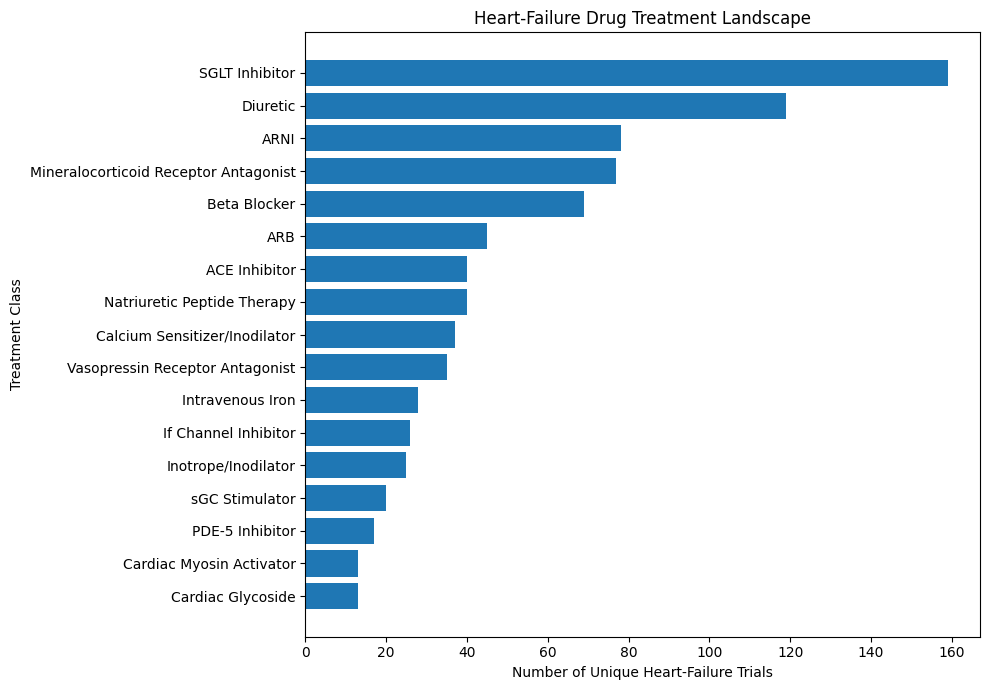

In [49]:
# Prepare treatment-class landscape figure
plot_treatment_classes = (
    refined_class_summary[
        ~refined_class_summary["treatment_class_refined"].isin(
            [
                "Other/Unclassified Drug",
                "Comparator/Background Therapy"
            ]
        )
    ]
    .sort_values("unique_trials", ascending=True)
)

plt.figure(figsize=(10, 7))

plt.barh(
    plot_treatment_classes["treatment_class_refined"],
    plot_treatment_classes["unique_trials"]
)

plt.xlabel("Number of Unique Heart-Failure Trials")
plt.ylabel("Treatment Class")
plt.title("Heart-Failure Drug Treatment Landscape")

plt.tight_layout()
plt.show()

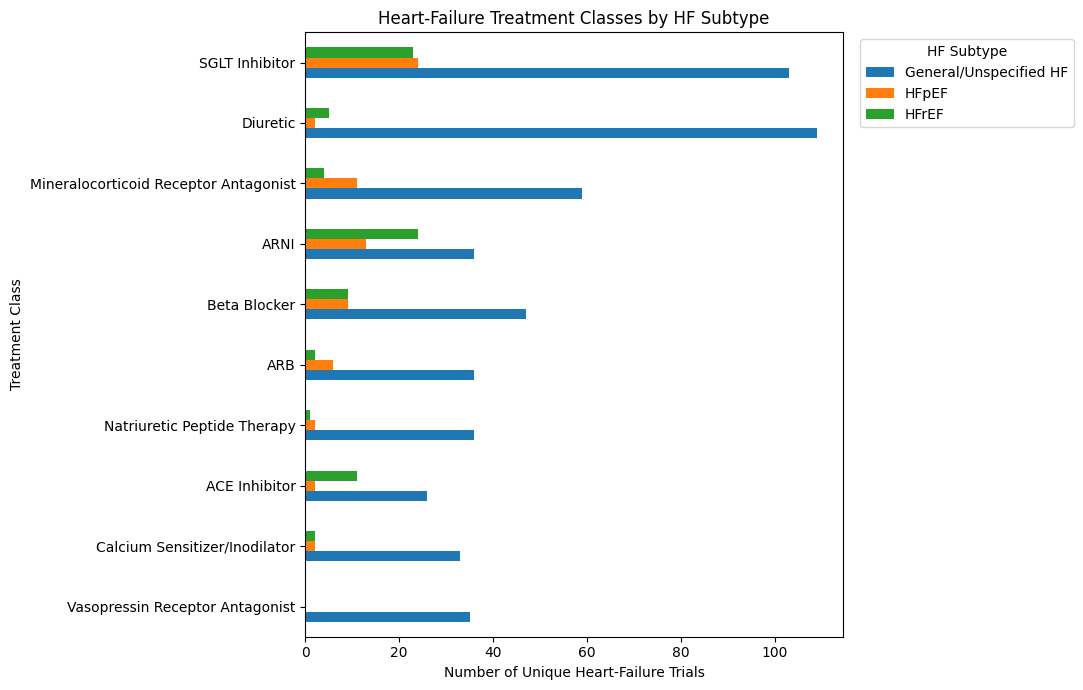

In [50]:
# Select major treatment classes for subtype comparison
major_classes = [
    "SGLT Inhibitor",
    "Diuretic",
    "ARNI",
    "Mineralocorticoid Receptor Antagonist",
    "Beta Blocker",
    "ARB",
    "ACE Inhibitor",
    "Natriuretic Peptide Therapy",
    "Calcium Sensitizer/Inodilator",
    "Vasopressin Receptor Antagonist"
]

subtype_plot_data = (
    treatment_by_subtype
    .loc[
        treatment_by_subtype.index.isin(major_classes),
        ["General/Unspecified HF", "HFpEF", "HFrEF"]
    ]
)

# Order by total trials across the displayed subtypes
subtype_plot_data["Displayed Total"] = subtype_plot_data.sum(axis=1)

subtype_plot_data = (
    subtype_plot_data
    .sort_values("Displayed Total", ascending=True)
    .drop(columns="Displayed Total")
)

subtype_plot_data.plot(
    kind="barh",
    figsize=(11, 7)
)

plt.xlabel("Number of Unique Heart-Failure Trials")
plt.ylabel("Treatment Class")
plt.title("Heart-Failure Treatment Classes by HF Subtype")
plt.legend(
    title="HF Subtype",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

In [51]:
# Save the main Week 2 datasets

primary_hf_cohort.to_csv(
    "HeartTrialTwin_primary_HF_cohort.csv",
    index=False
)

excluded_from_primary_hf.to_csv(
    "HeartTrialTwin_excluded_HF_candidates.csv",
    index=False
)

primary_hf_interventions.to_csv(
    "HeartTrialTwin_primary_HF_interventions.csv",
    index=False
)

hf_drugs.to_csv(
    "HeartTrialTwin_HF_drug_classes.csv",
    index=False
)

treatment_by_subtype.to_csv(
    "HeartTrialTwin_treatment_by_HF_subtype.csv"
)

treatment_by_phase.to_csv(
    "HeartTrialTwin_treatment_by_phase.csv"
)

print("Week 2 datasets saved successfully.")
print()
print("Files created:")
print("1. HeartTrialTwin_primary_HF_cohort.csv")
print("2. HeartTrialTwin_excluded_HF_candidates.csv")
print("3. HeartTrialTwin_primary_HF_interventions.csv")
print("4. HeartTrialTwin_HF_drug_classes.csv")
print("5. HeartTrialTwin_treatment_by_HF_subtype.csv")
print("6. HeartTrialTwin_treatment_by_phase.csv")

Week 2 datasets saved successfully.

Files created:
1. HeartTrialTwin_primary_HF_cohort.csv
2. HeartTrialTwin_excluded_HF_candidates.csv
3. HeartTrialTwin_primary_HF_interventions.csv
4. HeartTrialTwin_HF_drug_classes.csv
5. HeartTrialTwin_treatment_by_HF_subtype.csv
6. HeartTrialTwin_treatment_by_phase.csv


## Week 2 Progress Summary

### 1. Heart-Failure Cohort Construction
- Connected to the AACT clinical-trial database and retrieved interventional studies related to heart failure.
- Initial broad retrieval identified 4,704 candidate trials.
- Candidate trials were identified using submitted condition terminology and NLM-generated MeSH terminology to maximize retrieval sensitivity.
- For the primary analytical cohort, trials were required to contain explicit heart-failure or equivalent failure terminology in the submitted condition, title, or brief summary.
- Trials identified only through MeSH mapping without explicit supporting heart-failure terminology were excluded from the primary cohort.
- Final primary heart-failure cohort: **4,554 trials (96.81% of candidates).**

### 2. Initial Exploratory Analysis
The primary cohort was explored according to:
- overall trial status,
- trial phase,
- status by phase,
- intervention type,
- missingness and data-quality characteristics.

The analysis showed substantial heterogeneity in trial design and intervention type. Drug interventions were the largest individual intervention category, but device, behavioral, procedural, and other interventions were also well represented.

### 3. Heart-Failure Subtype Identification
A conservative text-based classification was developed using trial titles, submitted conditions, MeSH terminology, and brief summaries.

Trials were categorized as:
- HFrEF,
- HFpEF,
- HFmrEF,
- Mixed/Multiple,
- General/Unspecified HF.

Most historical trials did not explicitly identify one of the major HF phenotypes and therefore remained classified as General/Unspecified HF. HFmrEF had very limited explicit representation and will not be treated as a standalone modeling subgroup unless later data refinement provides sufficient observations.

### 4. Treatment-Landscape Development
The primary cohort contained:
- **7,731 intervention records**
- **3,011 drug intervention records**
- **1,667 trials containing at least one drug intervention**

Drug names were normalized to reduce differences caused by capitalization, dosage notation, formulation, and formatting.

Unique recorded drug names decreased from:
**1,594 raw names → 1,324 normalized names.**

A transparent rule-based treatment taxonomy was then developed for major HF-relevant therapeutic classes, including:
- SGLT inhibitors,
- ARNI,
- mineralocorticoid receptor antagonists,
- beta blockers,
- ACE inhibitors,
- ARBs,
- diuretics,
- natriuretic peptide therapies,
- vasopressin receptor antagonists,
- intravenous iron,
- inotropes/inodilators,
- cardiac myosin activators,
- and selected additional HF treatment classes.

Comparator and background therapies were separated from therapeutic treatment classes. Drugs that could not be reliably assigned were retained as Other/Unclassified rather than forcing potentially incorrect classifications.

### 5. Treatment-Landscape Findings
Among explicitly classified therapeutic categories, SGLT inhibitors were the most frequently represented, followed by diuretics, ARNI, mineralocorticoid receptor antagonists, and beta blockers.

Treatment classes were also compared across:
- HF subtype, and
- clinical trial phase.

The subtype analysis showed that a large proportion of historical trials remained General/Unspecified HF. Among explicitly classified subtypes, treatment-class representation varied across HFpEF and HFrEF.

These findings describe the historical clinical-trial research landscape and should not be interpreted as evidence of treatment effectiveness or causal treatment effects.

### 6. Week 2 Visualizations
Two initial treatment-landscape figures were produced:
1. Heart-Failure Drug Treatment Landscape.
2. Heart-Failure Treatment Classes by HF Subtype.

### 7. Important Limitations Identified
- Treatment classes are not intended to represent a complete pharmacological ontology.
- A substantial number of drugs remain Other/Unclassified.
- A single trial may contain multiple interventions and treatment classes.
- HF subtype information is frequently not explicitly reported in historical registry text.
- Current AACT records represent the current version of trial registrations and may contain fields updated after initial registration.
- Future predictive modeling must therefore carefully distinguish prediction-time variables from information that could introduce temporal data leakage.

## Week 2 Checkpoint

Week 2 established the condition-specific heart-failure cohort, performed initial exploratory analysis, developed conservative HF subtype features, and constructed the first treatment-landscape representation.

**No predictive outcome has been finalized and no risk model has been trained at this stage.**

## Week 3 Starting Point

Week 3 will focus on constructing the leakage-aware modeling dataset by retrieving and evaluating additional trial-level features such as:

- sponsor characteristics,
- enrollment,
- allocation and masking,
- intervention model,
- primary purpose,
- number of sites and countries,
- eligibility information,
- endpoint characteristics,
- trial start year,
- and potential measures of trial complexity.

Outcome and date distributions will then be evaluated before deciding whether the primary prediction task should focus on termination/withdrawal, unusually long completion time, or a combination of these outcomes.

## Final Cohort Outcome and Timeline Assessment

Now that the primary heart-failure cohort has been defined, this section evaluates trial status and date availability within the final cohort.

The purpose is to determine which outcome definitions are sufficiently supported for later trial-risk forecasting.

Potential outcomes include:
- trial termination or withdrawal,
- completed versus unsuccessful trial status,
- and unusually long trial completion time.

No modeling target is assigned at this stage. Outcome feasibility will first be assessed based on class distribution, ongoing studies, unknown statuses, and date completeness.

In [52]:
# Examine status distribution in the final primary HF cohort

final_status_summary = (
    primary_hf_cohort["overall_status"]
    .value_counts(dropna=False)
    .reset_index()
)

final_status_summary.columns = [
    "overall_status",
    "trial_count"
]

final_status_summary["percentage"] = (
    final_status_summary["trial_count"]
    / len(primary_hf_cohort)
    * 100
).round(2)

print(
    "Total trials in primary HF cohort:",
    len(primary_hf_cohort)
)

final_status_summary

Total trials in primary HF cohort: 4590


,overall_status,trial_count,percentage
0,COMPLETED,2305,50.22
1,UNKNOWN,709,15.45
2,RECRUITING,532,11.59
3,TERMINATED,398,8.67
4,NOT_YET_RECRUITING,242,5.27
5,WITHDRAWN,200,4.36
6,ACTIVE_NOT_RECRUITING,141,3.07
7,ENROLLING_BY_INVITATION,41,0.89
8,SUSPENDED,22,0.48


In [53]:
# Check the current primary HF cohort and exclusion counts

print("Candidate rows:", len(hf_cohort))
print("Candidate unique trials:", hf_cohort["nct_id"].nunique())

print()

print("Primary HF cohort rows:", len(primary_hf_cohort))
print(
    "Primary HF cohort unique trials:",
    primary_hf_cohort["nct_id"].nunique()
)

print()

print(
    "Excluded trials:",
    (~hf_cohort["primary_hf_inclusion"]).sum()
)

Candidate rows: 4740
Candidate unique trials: 4740

Primary HF cohort rows: 4590
Primary HF cohort unique trials: 4590

Excluded trials: 150


### Cohort Version Note

The AACT database is updated over time as ClinicalTrials.gov records are added or modified. During development, a refreshed query returned 4,711 candidate heart-failure trials rather than the 4,704 trials observed in an earlier extraction.

Applying the same predefined primary inclusion criteria resulted in a final cohort of 4,561 trials, with 150 candidate trials excluded.

The 4,561-trial cohort is used as the fixed analytical cohort for subsequent analyses in this notebook. Saved cohort files are used for downstream analyses to maintain reproducibility and avoid changes caused by later database updates.

In [54]:
# Assess date availability in the final primary HF cohort

date_availability = pd.DataFrame({
    "variable": [
        "start_date",
        "completion_date"
    ],
    "available_trials": [
        primary_hf_cohort["start_date"].notna().sum(),
        primary_hf_cohort["completion_date"].notna().sum()
    ],
    "missing_trials": [
        primary_hf_cohort["start_date"].isna().sum(),
        primary_hf_cohort["completion_date"].isna().sum()
    ]
})

date_availability["percentage_available"] = (
    date_availability["available_trials"]
    / len(primary_hf_cohort)
    * 100
).round(2)

date_availability

,variable,available_trials,missing_trials,percentage_available
0,start_date,4567,23,99.50
1,completion_date,4495,95,97.93


In [55]:
# Assess start-date and completion-date availability by trial status

date_availability_by_status = (
    primary_hf_cohort
    .groupby("overall_status")
    .agg(
        total_trials=("nct_id", "nunique"),
        start_date_available=("start_date", "count"),
        completion_date_available=("completion_date", "count")
    )
    .reset_index()
)

date_availability_by_status["start_date_available_pct"] = (
    date_availability_by_status["start_date_available"]
    / date_availability_by_status["total_trials"]
    * 100
).round(2)

date_availability_by_status["completion_date_available_pct"] = (
    date_availability_by_status["completion_date_available"]
    / date_availability_by_status["total_trials"]
    * 100
).round(2)

date_availability_by_status = (
    date_availability_by_status
    .sort_values("total_trials", ascending=False)
    .reset_index(drop=True)
)

date_availability_by_status

,overall_status,total_trials,start_date_available,completion_date_available,start_date_available_pct,completion_date_available_pct
0,COMPLETED,2305,2290,2264,99.35,98.22
1,UNKNOWN,709,705,675,99.44,95.20
2,RECRUITING,532,532,532,100.00,100.00
3,TERMINATED,398,398,392,100.00,98.49
4,NOT_YET_RECRUITING,242,242,242,100.00,100.00
5,WITHDRAWN,200,196,189,98.00,94.50
6,ACTIVE_NOT_RECRUITING,141,141,140,100.00,99.29
7,ENROLLING_BY_INVITATION,41,41,41,100.00,100.00
8,SUSPENDED,22,22,20,100.00,90.91


In [56]:
# Create a historical-status subset for timeline assessment

historical_statuses = [
    "COMPLETED",
    "TERMINATED",
    "WITHDRAWN"
]

historical_hf_trials = (
    primary_hf_cohort[
        primary_hf_cohort["overall_status"].isin(historical_statuses)
    ]
    .copy()
)

# Convert dates to datetime
historical_hf_trials["start_date_dt"] = pd.to_datetime(
    historical_hf_trials["start_date"],
    errors="coerce"
)

historical_hf_trials["completion_date_dt"] = pd.to_datetime(
    historical_hf_trials["completion_date"],
    errors="coerce"
)

# Calculate duration in days
historical_hf_trials["trial_duration_days"] = (
    historical_hf_trials["completion_date_dt"]
    - historical_hf_trials["start_date_dt"]
).dt.days

print("Historical-status trials:", len(historical_hf_trials))

print(
    "Trials with calculable duration:",
    historical_hf_trials["trial_duration_days"].notna().sum()
)

print(
    "Trials with negative duration:",
    (historical_hf_trials["trial_duration_days"] < 0).sum()
)

historical_hf_trials[
    "trial_duration_days"
].describe()

Historical-status trials: 2903
Trials with calculable duration: 2835
Trials with negative duration: 2


,trial_duration_days
count,2835.000000
mean,1033.635626
std,768.912596
min,-13.000000
25%,458.000000
50%,853.000000
75%,1430.000000
max,6032.000000


In [57]:
# Inspect trials with impossible negative calculated durations

negative_duration_trials = (
    historical_hf_trials[
        historical_hf_trials["trial_duration_days"] < 0
    ][
        [
            "nct_id",
            "brief_title",
            "overall_status",
            "start_date",
            "completion_date",
            "trial_duration_days"
        ]
    ]
    .sort_values("trial_duration_days")
)

negative_duration_trials

,nct_id,brief_title,overall_status,start_date,completion_date,trial_duration_days
2792,NCT04376424,Ultra-sound Assisted Management of Heart Failure,WITHDRAWN,2021-11-30,2021-11-17,-13.0
2996,NCT04757246,RESPECT Heart Failure- RESpiratory Pattern Eva...,WITHDRAWN,2022-10-31,2022-10-20,-11.0


In [58]:
# Mark impossible negative trial durations as missing

historical_hf_trials.loc[
    historical_hf_trials["trial_duration_days"] < 0,
    "trial_duration_days"
] = np.nan

print(
    "Valid calculable durations:",
    historical_hf_trials["trial_duration_days"].notna().sum()
)

print(
    "Remaining negative durations:",
    (historical_hf_trials["trial_duration_days"] < 0).sum()
)

Valid calculable durations: 2833
Remaining negative durations: 0


In [59]:
# Compare trial-duration distributions by historical trial status

duration_by_status = (
    historical_hf_trials
    .groupby("overall_status")["trial_duration_days"]
    .agg(
        valid_trials="count",
        mean_days="mean",
        median_days="median",
        min_days="min",
        max_days="max"
    )
    .round(1)
    .reset_index()
)

# Add duration in years for easier interpretation
duration_by_status["mean_years"] = (
    duration_by_status["mean_days"] / 365.25
).round(2)

duration_by_status["median_years"] = (
    duration_by_status["median_days"] / 365.25
).round(2)

duration_by_status

,overall_status,valid_trials,mean_days,median_days,min_days,max_days,mean_years,median_years
0,COMPLETED,2255,1071.5,889.0,0.0,6032.0,2.93,2.43
1,TERMINATED,392,974.4,810.0,1.0,4322.0,2.67,2.22
2,WITHDRAWN,186,710.6,534.0,0.0,3653.0,1.95,1.46


In [60]:
# Examine duration distribution among completed HF trials only

completed_hf_trials = (
    historical_hf_trials[
        (historical_hf_trials["overall_status"] == "COMPLETED")
        & historical_hf_trials["trial_duration_days"].notna()
    ]
    .copy()
)

completed_duration_quantiles = (
    completed_hf_trials["trial_duration_days"]
    .quantile([0.10, 0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .reset_index()
)

completed_duration_quantiles.columns = [
    "quantile",
    "duration_days"
]

completed_duration_quantiles["duration_years"] = (
    completed_duration_quantiles["duration_days"] / 365.25
).round(2)

print(
    "Completed trials with valid duration:",
    len(completed_hf_trials)
)

completed_duration_quantiles

Completed trials with valid duration: 2255


,quantile,duration_days,duration_years
0,0.10,245.00,0.67
1,0.25,514.50,1.41
2,0.50,889.00,2.43
3,0.75,1461.00,4.00
4,0.90,2101.00,5.75
5,0.95,2531.90,6.93
6,0.99,3607.42,9.88


In [61]:
# Examine completed-trial duration by phase

completed_duration_by_phase = (
    completed_hf_trials
    .assign(
        phase_display=lambda df: (
            df["phase"]
            .replace("NA", "NA / Not Applicable or Not Reported")
            .fillna("NA / Not Applicable or Not Reported")
        )
    )
    .groupby("phase_display")["trial_duration_days"]
    .agg(
        valid_trials="count",
        median_days="median",
        mean_days="mean",
        q75_days=lambda x: x.quantile(0.75),
        q90_days=lambda x: x.quantile(0.90)
    )
    .round(1)
    .reset_index()
)

completed_duration_by_phase["median_years"] = (
    completed_duration_by_phase["median_days"] / 365.25
).round(2)

completed_duration_by_phase["q75_years"] = (
    completed_duration_by_phase["q75_days"] / 365.25
).round(2)

completed_duration_by_phase = (
    completed_duration_by_phase
    .sort_values("median_days")
    .reset_index(drop=True)
)

completed_duration_by_phase

,phase_display,valid_trials,median_days,mean_days,q75_days,q90_days,median_years,q75_years
0,PHASE1,127,371.0,637.0,945.0,1609.2,1.02,2.59
1,EARLY_PHASE1,24,654.5,894.5,1407.2,1625.8,1.79,3.85
2,PHASE2,263,762.0,948.3,1308.0,1939.4,2.09,3.58
3,NA / Not Applicable or Not Reported,1251,875.0,1059.2,1443.0,2068.0,2.40,3.95
4,PHASE1/PHASE2,57,977.0,1189.9,1601.0,2325.0,2.67,4.38
5,PHASE4,260,1044.0,1202.6,1593.8,2252.0,2.86,4.36
6,PHASE2/PHASE3,58,1065.0,1177.9,1694.5,2280.3,2.92,4.64
7,PHASE3,215,1188.0,1351.5,1775.5,2320.0,3.25,4.86


In [62]:
# Compare completed-trial duration by intervention type

completed_intervention_duration = (
    primary_hf_interventions[
        primary_hf_interventions["nct_id"].isin(
            completed_hf_trials["nct_id"]
        )
    ][["nct_id", "intervention_type"]]
    .drop_duplicates()
    .merge(
        completed_hf_trials[
            ["nct_id", "trial_duration_days"]
        ],
        on="nct_id",
        how="inner"
    )
)

duration_by_intervention_type = (
    completed_intervention_duration
    .groupby("intervention_type")["trial_duration_days"]
    .agg(
        valid_trials="count",
        median_days="median",
        mean_days="mean",
        q75_days=lambda x: x.quantile(0.75),
        q90_days=lambda x: x.quantile(0.90)
    )
    .round(1)
    .reset_index()
)

duration_by_intervention_type["median_years"] = (
    duration_by_intervention_type["median_days"] / 365.25
).round(2)

duration_by_intervention_type["q75_years"] = (
    duration_by_intervention_type["q75_days"] / 365.25
).round(2)

duration_by_intervention_type = (
    duration_by_intervention_type
    .sort_values("valid_trials", ascending=False)
    .reset_index(drop=True)
)

duration_by_intervention_type

,intervention_type,valid_trials,median_days,mean_days,q75_days,q90_days,median_years,q75_years
0,DRUG,863,872.0,1033.2,1400.0,2066.6,2.39,3.83
1,OTHER,528,841.5,1030.7,1397.8,2139.8,2.30,3.83
2,DEVICE,473,1035.0,1225.3,1645.0,2315.4,2.83,4.50
3,BEHAVIORAL,348,942.5,1102.5,1548.5,2130.6,2.58,4.24
4,PROCEDURE,161,1066.0,1333.7,1705.0,2710.0,2.92,4.67
5,DIETARY_SUPPLEMENT,56,759.0,947.6,1171.5,1683.0,2.08,3.21
6,BIOLOGICAL,42,1414.5,1392.1,1829.5,2430.6,3.87,5.01
7,DIAGNOSTIC_TEST,32,800.5,901.4,1138.8,1425.6,2.19,3.12
8,COMBINATION_PRODUCT,13,454.0,789.3,852.0,1394.2,1.24,2.33
9,RADIATION,7,1206.0,1254.6,2132.0,2339.6,3.30,5.84


In [63]:
# Check whether AACT provides actual/estimated indicators for trial dates

date_type_query = text("""
SELECT
    nct_id,
    overall_status,
    start_date,
    start_date_type,
    completion_date,
    completion_date_type
FROM ctgov.studies
WHERE nct_id = ANY(:nct_ids);
""")

date_type_check = pd.read_sql_query(
    date_type_query,
    engine,
    params={
        "nct_ids": historical_hf_trials["nct_id"].tolist()
    }
)

print("Rows retrieved:", len(date_type_check))

print("\nStart-date type:")
print(
    date_type_check["start_date_type"]
    .fillna("MISSING")
    .value_counts(dropna=False)
)

print("\nCompletion-date type:")
print(
    date_type_check["completion_date_type"]
    .fillna("MISSING")
    .value_counts(dropna=False)
)

Rows retrieved: 2903

Start-date type:
start_date_type
ACTUAL       1486
MISSING      1355
ESTIMATED      62
Name: count, dtype: int64

Completion-date type:
completion_date_type
ACTUAL       2682
ESTIMATED     114
MISSING       107
Name: count, dtype: int64


In [64]:
# Examine date-type quality specifically among completed HF trials

completed_date_quality = (
    completed_hf_trials[
        ["nct_id", "trial_duration_days"]
    ]
    .merge(
        date_type_check[
            [
                "nct_id",
                "start_date_type",
                "completion_date_type"
            ]
        ],
        on="nct_id",
        how="left"
    )
)

print("Completed trials with valid duration:", len(completed_date_quality))

print("\nCompletion-date type among completed trials:")
print(
    completed_date_quality["completion_date_type"]
    .fillna("MISSING")
    .value_counts(dropna=False)
)

print("\nStart-date type among completed trials:")
print(
    completed_date_quality["start_date_type"]
    .fillna("MISSING")
    .value_counts(dropna=False)
)

print("\nCross-tabulation of start and completion date types:")
print(
    pd.crosstab(
        completed_date_quality["start_date_type"].fillna("MISSING"),
        completed_date_quality["completion_date_type"].fillna("MISSING"),
        margins=True
    )
)

Completed trials with valid duration: 2255

Completion-date type among completed trials:
completion_date_type
ACTUAL     2210
MISSING      45
Name: count, dtype: int64

Start-date type among completed trials:
start_date_type
ACTUAL     1230
MISSING    1025
Name: count, dtype: int64

Cross-tabulation of start and completion date types:
completion_date_type  ACTUAL  MISSING   All
start_date_type                            
ACTUAL                  1230        0  1230
MISSING                  980       45  1025
All                     2210       45  2255


In [65]:
# Create the primary cohort for completed-trial duration modeling

duration_model_cohort = (
    completed_date_quality[
        completed_date_quality["completion_date_type"] == "ACTUAL"
    ]
    .copy()
    .reset_index(drop=True)
)

print(
    "Trials in duration-modeling cohort:",
    len(duration_model_cohort)
)

# Calculate duration distribution for the final duration cohort
duration_model_quantiles = (
    duration_model_cohort["trial_duration_days"]
    .quantile([0.25, 0.50, 0.75, 0.90, 0.95, 0.99])
    .reset_index()
)

duration_model_quantiles.columns = [
    "quantile",
    "duration_days"
]

duration_model_quantiles["duration_years"] = (
    duration_model_quantiles["duration_days"] / 365.25
).round(2)

duration_model_quantiles

Trials in duration-modeling cohort: 2210


,quantile,duration_days,duration_years
0,0.25,507.75,1.39
1,0.50,891.00,2.44
2,0.75,1461.00,4.00
3,0.90,2103.10,5.76
4,0.95,2535.15,6.94
5,0.99,3642.07,9.97


In [66]:
# Define the primary unusually-long-duration outcome

LONG_DURATION_THRESHOLD = 1461.0

duration_model_cohort["long_duration"] = (
    duration_model_cohort["trial_duration_days"]
    > LONG_DURATION_THRESHOLD
).astype(int)

# Examine target distribution
long_duration_distribution = (
    duration_model_cohort["long_duration"]
    .value_counts()
    .rename_axis("long_duration")
    .reset_index(name="trial_count")
)

long_duration_distribution["label"] = (
    long_duration_distribution["long_duration"]
    .map({
        0: "Normal/shorter duration",
        1: "Unusually long duration"
    })
)

long_duration_distribution["percentage"] = (
    long_duration_distribution["trial_count"]
    / len(duration_model_cohort)
    * 100
).round(2)

print(
    "Long-duration threshold:",
    LONG_DURATION_THRESHOLD,
    "days"
)

print(
    "Threshold in years:",
    round(LONG_DURATION_THRESHOLD / 365.25, 2)
)

long_duration_distribution[
    ["long_duration", "label", "trial_count", "percentage"]
]

Long-duration threshold: 1461.0 days
Threshold in years: 4.0


,long_duration,label,trial_count,percentage
0,0,Normal/shorter duration,1668,75.48
1,1,Unusually long duration,542,24.52


In [67]:
# Create the historical cohort for trial-discontinuation modeling

discontinuation_model_cohort = (
    historical_hf_trials[
        historical_hf_trials["overall_status"].isin(
            ["COMPLETED", "TERMINATED", "WITHDRAWN"]
        )
    ]
    .copy()
    .reset_index(drop=True)
)

# Binary outcome:
# 0 = Completed
# 1 = Terminated or Withdrawn

discontinuation_model_cohort["discontinued"] = (
    discontinuation_model_cohort["overall_status"]
    .isin(["TERMINATED", "WITHDRAWN"])
    .astype(int)
)

discontinuation_distribution = (
    discontinuation_model_cohort["discontinued"]
    .value_counts()
    .rename_axis("discontinued")
    .reset_index(name="trial_count")
)

discontinuation_distribution["label"] = (
    discontinuation_distribution["discontinued"]
    .map({
        0: "Completed",
        1: "Terminated/Withdrawn"
    })
)

discontinuation_distribution["percentage"] = (
    discontinuation_distribution["trial_count"]
    / len(discontinuation_model_cohort)
    * 100
).round(2)

print(
    "Trials in discontinuation-modeling cohort:",
    len(discontinuation_model_cohort)
)

discontinuation_distribution[
    ["discontinued", "label", "trial_count", "percentage"]
]

Trials in discontinuation-modeling cohort: 2903


,discontinued,label,trial_count,percentage
0,0,Completed,2305,79.4
1,1,Terminated/Withdrawn,598,20.6


In [68]:
# Inspect available columns in the AACT designs table

design_columns_query = text("""
SELECT
    column_name,
    data_type
FROM information_schema.columns
WHERE table_schema = 'ctgov'
  AND table_name = 'designs'
ORDER BY ordinal_position;
""")

design_columns = pd.read_sql_query(
    design_columns_query,
    engine
)

design_columns

,column_name,data_type
0,id,integer
1,nct_id,character varying
2,allocation,character varying
3,intervention_model,character varying
4,observational_model,character varying
5,primary_purpose,character varying
6,time_perspective,character varying
7,masking,character varying
8,masking_description,text
9,intervention_model_description,text


In [69]:
# Retrieve planned trial-design characteristics
# for the discontinuation-modeling cohort

design_query = text("""
SELECT
    nct_id,
    allocation,
    intervention_model,
    primary_purpose,
    masking,
    subject_masked,
    caregiver_masked,
    investigator_masked,
    outcomes_assessor_masked
FROM ctgov.designs
WHERE nct_id = ANY(:nct_ids);
""")

hf_design_features = pd.read_sql_query(
    design_query,
    engine,
    params={
        "nct_ids": discontinuation_model_cohort["nct_id"].tolist()
    }
)

print("Design records retrieved:", len(hf_design_features))
print(
    "Unique trials with design records:",
    hf_design_features["nct_id"].nunique()
)

hf_design_features.head()

Design records retrieved: 2900
Unique trials with design records: 2900


,nct_id,allocation,intervention_model,primary_purpose,masking,subject_masked,caregiver_masked,investigator_masked,outcomes_assessor_masked
0,NCT00000475,RANDOMIZED,None,PREVENTION,None,None,None,None,None
1,NCT00000476,RANDOMIZED,None,TREATMENT,DOUBLE,None,None,None,None
2,NCT00000516,RANDOMIZED,None,PREVENTION,DOUBLE,None,None,None,None
3,NCT00000542,RANDOMIZED,None,PREVENTION,None,None,None,None,None
4,NCT00000547,RANDOMIZED,None,TREATMENT,DOUBLE,None,None,None,None


In [70]:
# Examine missingness and category distributions
# in the retrieved trial-design variables

design_variables = [
    "allocation",
    "intervention_model",
    "primary_purpose",
    "masking",
    "subject_masked",
    "caregiver_masked",
    "investigator_masked",
    "outcomes_assessor_masked"
]

design_missingness = pd.DataFrame({
    "variable": design_variables,
    "missing_count": [
        hf_design_features[col].isna().sum()
        for col in design_variables
    ],
    "missing_percentage": [
        round(
            hf_design_features[col].isna().mean() * 100,
            2
        )
        for col in design_variables
    ]
})

design_missingness

,variable,missing_count,missing_percentage
0,allocation,7,0.24
1,intervention_model,20,0.69
2,primary_purpose,62,2.14
3,masking,11,0.38
4,subject_masked,1559,53.76
5,caregiver_masked,1559,53.76
6,investigator_masked,1559,53.76
7,outcomes_assessor_masked,1559,53.76


In [71]:
# Inspect category distributions for the main trial-design variables

for col in [
    "allocation",
    "intervention_model",
    "primary_purpose",
    "masking"
]:
    print(f"\n{'=' * 60}")
    print(col.upper())
    print("=" * 60)

    counts = (
        hf_design_features[col]
        .fillna("MISSING")
        .value_counts(dropna=False)
    )

    print(counts)


ALLOCATION
allocation
RANDOMIZED        2153
NA                 510
NON_RANDOMIZED     230
MISSING              7
Name: count, dtype: int64

INTERVENTION_MODEL
intervention_model
PARALLEL        1888
SINGLE_GROUP     668
CROSSOVER        241
FACTORIAL         50
SEQUENTIAL        33
MISSING           20
Name: count, dtype: int64

PRIMARY_PURPOSE
primary_purpose
TREATMENT                   1871
SUPPORTIVE_CARE              254
DIAGNOSTIC                   164
PREVENTION                   153
OTHER                        149
HEALTH_SERVICES_RESEARCH     133
BASIC_SCIENCE                 84
MISSING                       62
DEVICE_FEASIBILITY            16
SCREENING                     12
ECT                            2
Name: count, dtype: int64

MASKING
masking
NONE         1446
SINGLE        474
DOUBLE        398
QUADRUPLE     369
TRIPLE        202
MISSING        11
Name: count, dtype: int64


In [72]:
# Inspect available columns in the AACT sponsors table

sponsor_columns_query = text("""
SELECT
    column_name,
    data_type
FROM information_schema.columns
WHERE table_schema = 'ctgov'
  AND table_name = 'sponsors'
ORDER BY ordinal_position;
""")

sponsor_columns = pd.read_sql_query(
    sponsor_columns_query,
    engine
)

sponsor_columns

,column_name,data_type
0,id,integer
1,nct_id,character varying
2,agency_class,character varying
3,lead_or_collaborator,character varying
4,name,character varying


In [73]:
# Retrieve lead-sponsor information for the discontinuation cohort

lead_sponsor_query = text("""
SELECT
    nct_id,
    agency_class,
    name AS lead_sponsor_name
FROM ctgov.sponsors
WHERE nct_id = ANY(:nct_ids)
  AND lead_or_collaborator = 'lead';
""")

hf_lead_sponsors = pd.read_sql_query(
    lead_sponsor_query,
    engine,
    params={
        "nct_ids": discontinuation_model_cohort["nct_id"].tolist()
    }
)

print("Lead-sponsor records retrieved:", len(hf_lead_sponsors))
print(
    "Unique trials with lead-sponsor records:",
    hf_lead_sponsors["nct_id"].nunique()
)

print("\nLead sponsor agency classes:")
print(
    hf_lead_sponsors["agency_class"]
    .fillna("MISSING")
    .value_counts(dropna=False)
)

hf_lead_sponsors.head()

Lead-sponsor records retrieved: 2903
Unique trials with lead-sponsor records: 2903

Lead sponsor agency classes:
agency_class
OTHER        1905
INDUSTRY      830
FED            70
OTHER_GOV      54
NIH            24
INDIV          14
NETWORK         6
Name: count, dtype: int64


,nct_id,agency_class,lead_sponsor_name
0,NCT00000475,NIH,"National Heart, Lung, and Blood Institute (NHLBI)"
1,NCT00000476,NIH,"National Heart, Lung, and Blood Institute (NHLBI)"
2,NCT00000516,NIH,"National Heart, Lung, and Blood Institute (NHLBI)"
3,NCT00000542,NIH,"National Heart, Lung, and Blood Institute (NHLBI)"
4,NCT00000547,NIH,"National Heart, Lung, and Blood Institute (NHLBI)"


In [74]:
# Inspect available columns in the AACT facilities table

facility_columns_query = text("""
SELECT
    column_name,
    data_type
FROM information_schema.columns
WHERE table_schema = 'ctgov'
  AND table_name = 'facilities'
ORDER BY ordinal_position;
""")

facility_columns = pd.read_sql_query(
    facility_columns_query,
    engine
)

facility_columns

,column_name,data_type
0,id,integer
1,nct_id,character varying
2,status,character varying
3,name,character varying
4,city,character varying
5,state,character varying
6,zip,character varying
7,country,character varying
8,latitude,numeric
9,longitude,numeric


In [75]:
# Create trial-level geographic/site features

facility_query = text("""
SELECT
    nct_id,
    name,
    country
FROM ctgov.facilities
WHERE nct_id = ANY(:nct_ids);
""")

hf_facilities = pd.read_sql_query(
    facility_query,
    engine,
    params={
        "nct_ids": discontinuation_model_cohort["nct_id"].tolist()
    }
)

print("Facility records retrieved:", len(hf_facilities))
print(
    "Trials with at least one facility record:",
    hf_facilities["nct_id"].nunique()
)

# Aggregate facility information to one row per trial
hf_geography_features = (
    hf_facilities
    .groupby("nct_id")
    .agg(
        number_of_sites=("name", "nunique"),
        number_of_countries=("country", "nunique")
    )
    .reset_index()
)

# Multinational indicator
hf_geography_features["multinational_trial"] = (
    hf_geography_features["number_of_countries"] > 1
).astype(int)

print(
    "\nTrials with derived geography features:",
    hf_geography_features["nct_id"].nunique()
)

hf_geography_features[
    [
        "number_of_sites",
        "number_of_countries"
    ]
].describe()

Facility records retrieved: 38427
Trials with at least one facility record: 2690

Trials with derived geography features: 2690


,number_of_sites,number_of_countries
count,2690.000000,2690.000000
mean,8.100372,2.019703
std,40.290064,4.149760
min,0.000000,1.000000
25%,1.000000,1.000000
50%,1.000000,1.000000
75%,2.000000,1.000000
max,974.000000,47.000000


In [76]:
# Investigate trials that have facility records
# but were calculated as having zero named sites

zero_site_trials = hf_geography_features[
    hf_geography_features["number_of_sites"] == 0
]["nct_id"].tolist()

print("Trials calculated as zero sites:", len(zero_site_trials))

zero_site_facilities = (
    hf_facilities[
        hf_facilities["nct_id"].isin(zero_site_trials)
    ]
    .sort_values("nct_id")
)

zero_site_facilities.head(20)

Trials calculated as zero sites: 68


,nct_id,name,country
2154,NCT00159614,None,United States
2155,NCT00159614,None,United States
2156,NCT00159614,None,United States
2157,NCT00159614,None,United States
2158,NCT00159614,None,United States
2159,NCT00159614,None,United States
2168,NCT00159627,None,United States
2167,NCT00159627,None,United States
2166,NCT00159627,None,United States
2165,NCT00159627,None,United States


In [77]:
# Rebuild trial-level geographic/site features using location information

facility_query = text("""
SELECT
    nct_id,
    name,
    city,
    state,
    country
FROM ctgov.facilities
WHERE nct_id = ANY(:nct_ids);
""")

hf_facilities = pd.read_sql_query(
    facility_query,
    engine,
    params={
        "nct_ids": discontinuation_model_cohort["nct_id"].tolist()
    }
)

# Create a location-based site identifier.
# Missing components are replaced only for constructing the identifier.
hf_facilities["site_identifier"] = (
    hf_facilities["name"].fillna("UNKNOWN_NAME").astype(str)
    + " | "
    + hf_facilities["city"].fillna("UNKNOWN_CITY").astype(str)
    + " | "
    + hf_facilities["state"].fillna("UNKNOWN_STATE").astype(str)
    + " | "
    + hf_facilities["country"].fillna("UNKNOWN_COUNTRY").astype(str)
)

# Collapse to one row per trial
hf_geography_features = (
    hf_facilities
    .groupby("nct_id")
    .agg(
        number_of_sites=("site_identifier", "nunique"),
        number_of_countries=("country", "nunique")
    )
    .reset_index()
)

hf_geography_features["multinational_trial"] = (
    hf_geography_features["number_of_countries"] > 1
).astype(int)

print("Facility records:", len(hf_facilities))

print(
    "Trials with facility information:",
    hf_geography_features["nct_id"].nunique()
)

print(
    "Trials calculated as zero sites:",
    (hf_geography_features["number_of_sites"] == 0).sum()
)

hf_geography_features[
    ["number_of_sites", "number_of_countries"]
].describe()

Facility records: 38427
Trials with facility information: 2690
Trials calculated as zero sites: 0


,number_of_sites,number_of_countries
count,2690.000000,2690.000000
mean,13.443123,2.019703
std,57.455426,4.149760
min,1.000000,1.000000
25%,1.000000,1.000000
50%,1.000000,1.000000
75%,4.000000,1.000000
max,1000.000000,47.000000


In [78]:
# Inspect trials with the largest reported number of sites

largest_site_trials = (
    hf_geography_features
    .sort_values("number_of_sites", ascending=False)
    .head(15)
    .merge(
        discontinuation_model_cohort[
            [
                "nct_id",
                "brief_title",
                "overall_status",
                "phase",
                "enrollment"
            ]
        ],
        on="nct_id",
        how="left"
    )
)

largest_site_trials[
    [
        "nct_id",
        "brief_title",
        "overall_status",
        "phase",
        "enrollment",
        "number_of_sites",
        "number_of_countries",
        "multinational_trial"
    ]
]

,nct_id,brief_title,overall_status,phase,enrollment,number_of_sites,number_of_countries,multinational_trial
0,NCT05636176,A Research Study to Look at How Ziltivekimab W...,TERMINATED,PHASE3,4899.0,1000,46,1
1,NCT02929329,Registrational Study With Omecamtiv Mecarbil (...,COMPLETED,PHASE3,8256.0,808,36,1
2,NCT01035255,This Study Will Evaluate the Efficacy and Safe...,TERMINATED,PHASE3,8442.0,791,47,1
3,NCT03315143,Effect of Sotagliflozin on Cardiovascular and ...,TERMINATED,PHASE3,10584.0,754,45,1
4,NCT04435626,Study to Evaluate the Efficacy (Effect on Dise...,COMPLETED,PHASE3,6016.0,661,37,1
5,NCT00853658,Efficacy and Safety of Aliskiren and Aliskiren...,COMPLETED,PHASE3,7064.0,643,44,1
6,NCT03057951,EMPagliflozin outcomE tRial in Patients With c...,COMPLETED,PHASE3,5988.0,616,23,1
7,NCT02111564,A Study of Rivaroxaban (JNJ-39039039) on the V...,COMPLETED,PHASE3,12024.0,593,37,1
8,NCT01920711,Efficacy and Safety of LCZ696 Compared to Vals...,COMPLETED,PHASE3,4822.0,581,43,1
9,NCT00358215,RED-HF™ Trial - Reduction of Events With Darbe...,COMPLETED,PHASE3,2278.0,575,36,1


In [79]:
# Inspect available columns in the AACT eligibilities table

eligibility_columns_query = text("""
SELECT
    column_name,
    data_type
FROM information_schema.columns
WHERE table_schema = 'ctgov'
  AND table_name = 'eligibilities'
ORDER BY ordinal_position;
""")

eligibility_columns = pd.read_sql_query(
    eligibility_columns_query,
    engine
)

eligibility_columns

,column_name,data_type
0,id,integer
1,nct_id,character varying
2,sampling_method,character varying
3,gender,character varying
4,minimum_age,character varying
5,maximum_age,character varying
6,healthy_volunteers,boolean
7,population,text
8,criteria,text
9,gender_description,text


In [80]:
# Retrieve eligibility information for the discontinuation cohort

eligibility_query = text("""
SELECT
    nct_id,
    gender,
    minimum_age,
    maximum_age,
    healthy_volunteers,
    adult,
    child,
    older_adult,
    criteria
FROM ctgov.eligibilities
WHERE nct_id = ANY(:nct_ids);
""")

hf_eligibility = pd.read_sql_query(
    eligibility_query,
    engine,
    params={
        "nct_ids": discontinuation_model_cohort["nct_id"].tolist()
    }
)

print("Eligibility records retrieved:", len(hf_eligibility))
print(
    "Unique trials with eligibility records:",
    hf_eligibility["nct_id"].nunique()
)

print("\nMissingness:")
print(
    hf_eligibility[
        [
            "gender",
            "minimum_age",
            "maximum_age",
            "healthy_volunteers",
            "adult",
            "child",
            "older_adult",
            "criteria"
        ]
    ]
    .isna()
    .sum()
)

print("\nMost common minimum-age values:")
print(
    hf_eligibility["minimum_age"]
    .fillna("MISSING")
    .value_counts()
    .head(15)
)

print("\nMost common maximum-age values:")
print(
    hf_eligibility["maximum_age"]
    .fillna("MISSING")
    .value_counts()
    .head(15)
)

Eligibility records retrieved: 2903
Unique trials with eligibility records: 2903

Missingness:
gender                   1
minimum_age            112
maximum_age           1980
healthy_volunteers      15
adult                    0
child                    0
older_adult              0
criteria                 1
dtype: int64

Most common minimum-age values:
minimum_age
18 Years    2089
21 Years     132
MISSING      112
40 Years      88
20 Years      80
50 Years      66
60 Years      60
30 Years      45
65 Years      40
19 Years      39
45 Years      34
55 Years      26
35 Years      12
70 Years      12
22 Years      10
Name: count, dtype: int64

Most common maximum-age values:
maximum_age
MISSING      1980
80 Years      223
85 Years      136
75 Years      128
90 Years       85
70 Years       47
99 Years       47
100 Years      44
65 Years       38
79 Years       24
60 Years       19
45 Years       13
89 Years       11
55 Years       11
95 Years       10
Name: count, dtype: int64


In [81]:
# Inspect the units used in minimum_age and maximum_age

def extract_age_unit(value):
    if pd.isna(value):
        return "MISSING"

    value = str(value).strip()

    # Return everything after the numeric portion
    match = re.match(r"^\s*[\d.]+\s*(.*)$", value)

    if match:
        unit = match.group(1).strip()
        return unit if unit else "NO_UNIT"

    return value


print("Minimum-age units:")
print(
    hf_eligibility["minimum_age"]
    .apply(extract_age_unit)
    .value_counts(dropna=False)
)

print("\nMaximum-age units:")
print(
    hf_eligibility["maximum_age"]
    .apply(extract_age_unit)
    .value_counts(dropna=False)
)

Minimum-age units:
minimum_age
Years      2777
MISSING     112
Day           5
Months        4
Year          2
Hours         1
Weeks         1
Month         1
Name: count, dtype: int64

Maximum-age units:
maximum_age
MISSING    1980
Years       922
Days          1
Name: count, dtype: int64


In [82]:
# Convert ClinicalTrials.gov age strings to years

def age_to_years(value):
    if pd.isna(value):
        return np.nan

    value = str(value).strip()

    match = re.match(
        r"^\s*([\d.]+)\s*(Hours?|Days?|Weeks?|Months?|Years?)\s*$",
        value,
        flags=re.IGNORECASE
    )

    if not match:
        return np.nan

    number = float(match.group(1))
    unit = match.group(2).lower()

    if unit.startswith("year"):
        return number
    elif unit.startswith("month"):
        return number / 12
    elif unit.startswith("week"):
        return number / 52.1429
    elif unit.startswith("day"):
        return number / 365.25
    elif unit.startswith("hour"):
        return number / (365.25 * 24)

    return np.nan


hf_eligibility["minimum_age_years"] = (
    hf_eligibility["minimum_age"].apply(age_to_years)
)

hf_eligibility["maximum_age_years"] = (
    hf_eligibility["maximum_age"].apply(age_to_years)
)

# Indicator showing whether an explicit upper-age limit was reported
hf_eligibility["maximum_age_reported"] = (
    hf_eligibility["maximum_age"].notna()
).astype(int)


print("Minimum age after conversion:")
print(hf_eligibility["minimum_age_years"].describe())

print("\nMaximum age after conversion:")
print(hf_eligibility["maximum_age_years"].describe())

print("\nMaximum-age limit reported:")
print(
    hf_eligibility["maximum_age_reported"]
    .value_counts()
    .rename(index={0: "No explicit maximum", 1: "Maximum reported"})
)

print("\nUnconverted non-missing minimum ages:",
      (
          hf_eligibility["minimum_age"].notna()
          & hf_eligibility["minimum_age_years"].isna()
      ).sum())

print("Unconverted non-missing maximum ages:",
      (
          hf_eligibility["maximum_age"].notna()
          & hf_eligibility["maximum_age_years"].isna()
      ).sum())

Minimum age after conversion:
count    2791.000000
mean       22.538178
std        11.837478
min         0.000000
25%        18.000000
50%        18.000000
75%        18.000000
max        75.000000
Name: minimum_age_years, dtype: float64

Maximum age after conversion:
count    923.000000
mean      79.817035
std       16.985716
min        0.123203
25%       75.000000
50%       80.000000
75%       85.000000
max      150.000000
Name: maximum_age_years, dtype: float64

Maximum-age limit reported:
maximum_age_reported
No explicit maximum    1980
Maximum reported        923
Name: count, dtype: int64

Unconverted non-missing minimum ages: 0
Unconverted non-missing maximum ages: 0


In [83]:
# Inspect distributions of structured eligibility characteristics

print("Gender:")
print(
    hf_eligibility["gender"]
    .fillna("MISSING")
    .value_counts(dropna=False)
)

print("\nHealthy volunteers:")
print(
    hf_eligibility["healthy_volunteers"]
    .fillna("MISSING")
    .value_counts(dropna=False)
)

print("\nAdult eligibility:")
print(
    hf_eligibility["adult"]
    .value_counts(dropna=False)
)

print("\nChild eligibility:")
print(
    hf_eligibility["child"]
    .value_counts(dropna=False)
)

print("\nOlder-adult eligibility:")
print(
    hf_eligibility["older_adult"]
    .value_counts(dropna=False)
)

Gender:
gender
ALL        2832
MALE         55
FEMALE       15
MISSING       1
Name: count, dtype: int64

Healthy volunteers:
healthy_volunteers
False      2630
True        258
MISSING      15
Name: count, dtype: int64

Adult eligibility:
adult
True     2826
False      77
Name: count, dtype: int64

Child eligibility:
child
False    2755
True      148
Name: count, dtype: int64

Older-adult eligibility:
older_adult
True     2824
False      79
Name: count, dtype: int64


In [84]:
# Inspect available columns in the AACT design_outcomes table

outcome_columns_query = text("""
SELECT
    column_name,
    data_type
FROM information_schema.columns
WHERE table_schema = 'ctgov'
  AND table_name = 'design_outcomes'
ORDER BY ordinal_position;
""")

outcome_columns = pd.read_sql_query(
    outcome_columns_query,
    engine
)

outcome_columns

,column_name,data_type
0,id,integer
1,nct_id,character varying
2,outcome_type,character varying
3,measure,text
4,time_frame,text
5,population,character varying
6,description,text


In [85]:
# Retrieve planned outcome/end-point information
# for the discontinuation modeling cohort

design_outcomes_query = text("""
SELECT
    nct_id,
    outcome_type,
    measure,
    time_frame,
    description
FROM ctgov.design_outcomes
WHERE nct_id = ANY(:nct_ids);
""")

hf_design_outcomes = pd.read_sql_query(
    design_outcomes_query,
    engine,
    params={
        "nct_ids": discontinuation_model_cohort["nct_id"].tolist()
    }
)

print("Outcome records retrieved:", len(hf_design_outcomes))

print(
    "Trials with at least one outcome record:",
    hf_design_outcomes["nct_id"].nunique()
)

print(
    "Trials with no outcome records:",
    len(discontinuation_model_cohort)
    - hf_design_outcomes["nct_id"].nunique()
)

print("\nOutcome-type distribution:")
print(
    hf_design_outcomes["outcome_type"]
    .fillna("MISSING")
    .value_counts(dropna=False)
)

print("\nMissingness:")
print(
    hf_design_outcomes[
        [
            "outcome_type",
            "measure",
            "time_frame",
            "description"
        ]
    ]
    .isna()
    .sum()
)

Outcome records retrieved: 20233
Trials with at least one outcome record: 2862
Trials with no outcome records: 41

Outcome-type distribution:
outcome_type
secondary    13266
primary       5156
other         1811
Name: count, dtype: int64

Missingness:
outcome_type       0
measure            0
time_frame       528
description     4522
dtype: int64


In [86]:
# Create trial-level endpoint complexity features

outcome_counts = (
    hf_design_outcomes
    .groupby(["nct_id", "outcome_type"])
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

# Ensure expected columns exist
for col in ["primary", "secondary", "other"]:
    if col not in outcome_counts.columns:
        outcome_counts[col] = 0

# Rename for clarity
outcome_counts = outcome_counts.rename(
    columns={
        "primary": "number_of_primary_outcomes",
        "secondary": "number_of_secondary_outcomes",
        "other": "number_of_other_outcomes"
    }
)

# Total number of reported planned outcomes
outcome_counts["total_number_of_outcomes"] = (
    outcome_counts["number_of_primary_outcomes"]
    + outcome_counts["number_of_secondary_outcomes"]
    + outcome_counts["number_of_other_outcomes"]
)

print("Trials with outcome-count features:", outcome_counts["nct_id"].nunique())

print("\nEndpoint-count distributions:")
print(
    outcome_counts[
        [
            "number_of_primary_outcomes",
            "number_of_secondary_outcomes",
            "number_of_other_outcomes",
            "total_number_of_outcomes"
        ]
    ].describe()
)

print("\nTrials with the largest numbers of reported outcomes:")
display(
    outcome_counts
    .sort_values("total_number_of_outcomes", ascending=False)
    .head(10)
)

Trials with outcome-count features: 2862

Endpoint-count distributions:
outcome_type  number_of_primary_outcomes  number_of_secondary_outcomes  \
count                        2862.000000                   2862.000000   
mean                            1.801537                      4.635220   
std                             2.294872                      6.256745   
min                             1.000000                      0.000000   
25%                             1.000000                      1.000000   
50%                             1.000000                      3.000000   
75%                             2.000000                      6.000000   
max                            46.000000                     98.000000   

outcome_type  number_of_other_outcomes  total_number_of_outcomes  
count                      2862.000000               2862.000000  
mean                          0.632774                  7.069532  
std                           3.558324                  7.94

outcome_type,nct_id,number_of_other_outcomes,number_of_primary_outcomes,number_of_secondary_outcomes,total_number_of_outcomes
2493,NCT05256303,103,1,4,108
2530,NCT05393362,12,3,92,107
5,NCT00023595,0,3,98,101
1763,NCT03203759,63,1,28,92
1590,NCT02864420,57,1,24,82
1847,NCT03387813,27,8,43,78
387,NCT00608491,0,2,68,70
2036,NCT03801967,0,46,21,67
2396,NCT04903717,8,1,56,65
2310,NCT04645732,48,1,12,61


In [87]:
# Inspect enrollment-related and date/submission fields
# available in the AACT studies table

studies_columns_query = text("""
SELECT
    column_name,
    data_type
FROM information_schema.columns
WHERE table_schema = 'ctgov'
  AND table_name = 'studies'
  AND (
       column_name ILIKE '%enrollment%'
       OR column_name ILIKE '%submitted%'
       OR column_name ILIKE '%start_date%'
       OR column_name ILIKE '%study_first%'
       OR column_name ILIKE '%phase%'
  )
ORDER BY ordinal_position;
""")

studies_relevant_columns = pd.read_sql_query(
    studies_columns_query,
    engine
)

studies_relevant_columns

,column_name,data_type
0,study_first_submitted_date,date
1,results_first_submitted_date,date
2,disposition_first_submitted_date,date
3,last_update_submitted_date,date
4,study_first_submitted_qc_date,date
5,study_first_posted_date,date
6,study_first_posted_date_type,character varying
7,results_first_submitted_qc_date,date
8,disposition_first_submitted_qc_date,date
9,last_update_submitted_qc_date,date


In [88]:
# Retrieve enrollment and temporal fields for the discontinuation cohort

enrollment_query = text("""
SELECT
    nct_id,
    enrollment,
    enrollment_type,
    study_first_submitted_date,
    study_first_posted_date,
    start_date,
    start_date_type
FROM ctgov.studies
WHERE nct_id = ANY(:nct_ids);
""")

hf_enrollment_temporal = pd.read_sql_query(
    enrollment_query,
    engine,
    params={
        "nct_ids": discontinuation_model_cohort["nct_id"].tolist()
    }
)

# Add outcome status for the leakage audit
hf_enrollment_temporal = hf_enrollment_temporal.merge(
    discontinuation_model_cohort[
        ["nct_id", "overall_status", "discontinued"]
    ],
    on="nct_id",
    how="left",
    validate="one_to_one"
)

print("Trials retrieved:", len(hf_enrollment_temporal))
print(
    "Unique trials:",
    hf_enrollment_temporal["nct_id"].nunique()
)

print("\nEnrollment type:")
print(
    hf_enrollment_temporal["enrollment_type"]
    .fillna("MISSING")
    .value_counts()
)

print("\nEnrollment type by trial status:")
print(
    pd.crosstab(
        hf_enrollment_temporal["overall_status"],
        hf_enrollment_temporal["enrollment_type"].fillna("MISSING"),
        margins=True
    )
)

print("\nMissingness:")
print(
    hf_enrollment_temporal[
        [
            "enrollment",
            "enrollment_type",
            "study_first_submitted_date",
            "study_first_posted_date",
            "start_date",
            "start_date_type"
        ]
    ].isna().sum()
)

Trials retrieved: 2903
Unique trials: 2903

Enrollment type:
enrollment_type
ACTUAL       2681
MISSING       114
ESTIMATED     108
Name: count, dtype: int64

Enrollment type by trial status:
enrollment_type  ACTUAL  ESTIMATED  MISSING   All
overall_status                                   
COMPLETED          2124         81      100  2305
TERMINATED          360         24       14   398
WITHDRAWN           197          3        0   200
All                2681        108      114  2903

Missingness:
enrollment                      33
enrollment_type                114
study_first_submitted_date       0
study_first_posted_date          0
start_date                      19
start_date_type               1355
dtype: int64


In [89]:
# Create submission-year feature and inspect the historical distribution

hf_enrollment_temporal["submission_year"] = pd.to_datetime(
    hf_enrollment_temporal["study_first_submitted_date"]
).dt.year

year_summary = (
    hf_enrollment_temporal
    .groupby("submission_year")
    .agg(
        number_of_trials=("nct_id", "count"),
        discontinued_trials=("discontinued", "sum"),
        discontinuation_rate=("discontinued", "mean")
    )
    .reset_index()
)

year_summary["discontinuation_rate_percent"] = (
    year_summary["discontinuation_rate"] * 100
)

print("Submission-year range:")
print(
    hf_enrollment_temporal["submission_year"].min(),
    "to",
    hf_enrollment_temporal["submission_year"].max()
)

print("\nTrials by submission year:")
display(
    year_summary[
        [
            "submission_year",
            "number_of_trials",
            "discontinued_trials",
            "discontinuation_rate_percent"
        ]
    ]
)

print("\nSubmission-year quantiles:")
print(
    hf_enrollment_temporal["submission_year"]
    .quantile([0.25, 0.50, 0.75, 0.80, 0.90])
)

Submission-year range:
1999 to 2026

Trials by submission year:


,submission_year,number_of_trials,discontinued_trials,discontinuation_rate_percent
0,1999,12,0,0.000000
1,2000,2,0,0.000000
2,2001,9,0,0.000000
3,2002,14,1,7.142857
4,2003,11,1,9.090909
5,2004,13,3,23.076923
6,2005,139,17,12.230216
7,2006,105,32,30.476190
8,2007,118,24,20.338983
9,2008,122,28,22.950820



Submission-year quantiles:
0.25    2010.0
0.50    2015.0
0.75    2019.0
0.80    2020.0
0.90    2022.0
Name: submission_year, dtype: float64


In [90]:
# Evaluate a candidate temporal split:
# Train = submitted through 2020
# Test  = submitted from 2021 onward

TEMPORAL_CUTOFF_YEAR = 2020

hf_enrollment_temporal["temporal_set"] = np.where(
    hf_enrollment_temporal["submission_year"] <= TEMPORAL_CUTOFF_YEAR,
    "Train (≤2020)",
    "Test (2021+)"
)

temporal_split_summary = (
    hf_enrollment_temporal
    .groupby("temporal_set")
    .agg(
        number_of_trials=("nct_id", "count"),
        completed_trials=("discontinued", lambda x: (x == 0).sum()),
        discontinued_trials=("discontinued", lambda x: (x == 1).sum()),
        discontinuation_rate=("discontinued", "mean"),
        earliest_year=("submission_year", "min"),
        latest_year=("submission_year", "max")
    )
    .reset_index()
)

temporal_split_summary["discontinuation_rate_percent"] = (
    temporal_split_summary["discontinuation_rate"] * 100
)

temporal_split_summary[
    [
        "temporal_set",
        "number_of_trials",
        "completed_trials",
        "discontinued_trials",
        "discontinuation_rate_percent",
        "earliest_year",
        "latest_year"
    ]
]

,temporal_set,number_of_trials,completed_trials,discontinued_trials,discontinuation_rate_percent,earliest_year,latest_year
0,Test (2021+),530,440,90,16.981132,2021,2026
1,Train (≤2020),2373,1865,508,21.407501,1999,2020


In [91]:
# Examine outcome maturity within the proposed 2021+ temporal test set

test_year_status = (
    hf_enrollment_temporal[
        hf_enrollment_temporal["submission_year"] >= 2021
    ]
    .groupby(["submission_year", "overall_status"])
    .size()
    .unstack(fill_value=0)
)

# Ensure expected status columns exist
for col in ["COMPLETED", "TERMINATED", "WITHDRAWN"]:
    if col not in test_year_status.columns:
        test_year_status[col] = 0

test_year_status["total"] = (
    test_year_status["COMPLETED"]
    + test_year_status["TERMINATED"]
    + test_year_status["WITHDRAWN"]
)

test_year_status["discontinued"] = (
    test_year_status["TERMINATED"]
    + test_year_status["WITHDRAWN"]
)

test_year_status["discontinuation_rate_percent"] = (
    test_year_status["discontinued"]
    / test_year_status["total"]
    * 100
)

test_year_status[
    [
        "COMPLETED",
        "TERMINATED",
        "WITHDRAWN",
        "total",
        "discontinued",
        "discontinuation_rate_percent"
    ]
]

overall_status,COMPLETED,TERMINATED,WITHDRAWN,total,discontinued,discontinuation_rate_percent
submission_year,,,,,,
2021,133,15,8,156,23,14.743590
2022,96,14,9,119,23,19.327731
2023,90,11,13,114,24,21.052632
2024,61,8,4,73,12,16.438356
2025,38,2,6,46,8,17.391304
2026,22,0,0,22,0,0.000000


In [92]:
# Define the primary temporal evaluation framework
#
# Training: trials first submitted through 2020
# Test:     trials first submitted from 2021 through 2024
# Holdout from primary evaluation: 2025-2026
# because outcomes are likely insufficiently mature

def assign_temporal_group(year):
    if year <= 2020:
        return "Train (≤2020)"
    elif 2021 <= year <= 2024:
        return "Test (2021–2024)"
    else:
        return "Outcome-immature (2025–2026)"


hf_enrollment_temporal["modeling_period"] = (
    hf_enrollment_temporal["submission_year"]
    .apply(assign_temporal_group)
)

final_temporal_summary = (
    hf_enrollment_temporal
    .groupby("modeling_period")
    .agg(
        number_of_trials=("nct_id", "count"),
        completed_trials=("discontinued", lambda x: (x == 0).sum()),
        discontinued_trials=("discontinued", lambda x: (x == 1).sum()),
        discontinuation_rate=("discontinued", "mean"),
        earliest_year=("submission_year", "min"),
        latest_year=("submission_year", "max")
    )
    .reset_index()
)

final_temporal_summary["discontinuation_rate_percent"] = (
    final_temporal_summary["discontinuation_rate"] * 100
)

final_temporal_summary[
    [
        "modeling_period",
        "number_of_trials",
        "completed_trials",
        "discontinued_trials",
        "discontinuation_rate_percent",
        "earliest_year",
        "latest_year"
    ]
]

,modeling_period,number_of_trials,completed_trials,discontinued_trials,discontinuation_rate_percent,earliest_year,latest_year
0,Outcome-immature (2025–2026),68,60,8,11.764706,2025,2026
1,Test (2021–2024),462,380,82,17.748918,2021,2024
2,Train (≤2020),2373,1865,508,21.407501,1999,2020


In [93]:
# STEP 1A — Verify current HeartTrialTwin modeling cohort

print("Dataset shape:", hf_enrollment_temporal.shape)
print("Unique trials:", hf_enrollment_temporal["nct_id"].nunique())

print("\nOutcome counts:")
print(
    hf_enrollment_temporal["discontinued"]
    .value_counts()
    .sort_index()
)

print("\nTemporal groups:")
print(
    hf_enrollment_temporal["modeling_period"]
    .value_counts()
)

print("\nSubmission-year range:")
print(
    hf_enrollment_temporal["submission_year"].min(),
    "to",
    hf_enrollment_temporal["submission_year"].max()
)

print("\nAvailable columns:")
print(hf_enrollment_temporal.columns.tolist())

Dataset shape: (2903, 12)
Unique trials: 2903

Outcome counts:
discontinued
0    2305
1     598
Name: count, dtype: int64

Temporal groups:
modeling_period
Train (≤2020)                   2373
Test (2021–2024)                 462
Outcome-immature (2025–2026)      68
Name: count, dtype: int64

Submission-year range:
1999 to 2026

Available columns:
['nct_id', 'enrollment', 'enrollment_type', 'study_first_submitted_date', 'study_first_posted_date', 'start_date', 'start_date_type', 'overall_status', 'discontinued', 'submission_year', 'temporal_set', 'modeling_period']


In [94]:
# STEP 1B — Audit outcome definition and temporal distribution

import pandas as pd

# 1. Exact current status counts
print("=== OVERALL STATUS COUNTS ===")
print(
    hf_enrollment_temporal["overall_status"]
    .value_counts(dropna=False)
)

# 2. Cross-check status against binary outcome
print("\n=== STATUS vs DISCONTINUED LABEL ===")
print(
    pd.crosstab(
        hf_enrollment_temporal["overall_status"],
        hf_enrollment_temporal["discontinued"],
        margins=True
    )
)

# 3. Outcome distribution by submission year
yearly_outcomes = (
    hf_enrollment_temporal
    .groupby("submission_year")
    .agg(
        total_trials=("nct_id", "count"),
        completed=("discontinued", lambda x: (x == 0).sum()),
        discontinued=("discontinued", lambda x: (x == 1).sum()),
        discontinuation_rate=("discontinued", "mean")
    )
    .reset_index()
)

yearly_outcomes["discontinuation_rate_percent"] = (
    yearly_outcomes["discontinuation_rate"] * 100
).round(1)

display(
    yearly_outcomes[
        [
            "submission_year",
            "total_trials",
            "completed",
            "discontinued",
            "discontinuation_rate_percent"
        ]
    ]
)

=== OVERALL STATUS COUNTS ===
overall_status
COMPLETED     2305
TERMINATED     398
WITHDRAWN      200
Name: count, dtype: int64

=== STATUS vs DISCONTINUED LABEL ===
discontinued       0    1   All
overall_status                 
COMPLETED       2305    0  2305
TERMINATED         0  398   398
WITHDRAWN          0  200   200
All             2305  598  2903


,submission_year,total_trials,completed,discontinued,discontinuation_rate_percent
0,1999,12,12,0,0.0
1,2000,2,2,0,0.0
2,2001,9,9,0,0.0
3,2002,14,13,1,7.1
4,2003,11,10,1,9.1
5,2004,13,10,3,23.1
6,2005,139,122,17,12.2
7,2006,105,73,32,30.5
8,2007,118,94,24,20.3
9,2008,122,94,28,23.0


In [95]:
# STEP 1C — Identify earlier cohort dataframes

import pandas as pd

print("=== DATAFRAMES CURRENTLY IN MEMORY ===\n")

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        print(
            f"{name:35s} "
            f"rows={len(obj):6d}  "
            f"cols={obj.shape[1]:3d}"
        )

=== DATAFRAMES CURRENTLY IN MEMORY ===

_                                   rows=     3  cols=  7
__                                  rows=     6  cols=  6
___                                 rows=     2  cols=  7
test_df                             rows=     5  cols=  4
_5                                  rows=     5  cols=  4
_8                                  rows=     5  cols=  4
hf_candidates                       rows= 34251  cols=  9
_9                                  rows=     5  cols=  9
_11                                 rows=    20  cols=  3
hf_one_row                          rows=  4740  cols=  9
_12                                 rows=     5  cols=  9
status_counts                       rows=     9  cols=  3
_13                                 rows=     9  cols=  3
phase_counts                        rows=     8  cols=  3
_14                                 rows=     8  cols=  3
status_by_phase                     rows=     9  cols= 10
_15                             

In [96]:
# STEP 1D — Reconstruct HeartTrialTwin HF cohort flow

cohort_flow = pd.DataFrame({
    "stage": [
        "HF candidate rows",
        "Unique HF trials",
        "Primary HF cohort",
        "Excluded from primary HF cohort",
        "Terminal-outcome historical cohort",
        "Discontinuation modeling cohort"
    ],
    "dataframe": [
        "hf_candidates",
        "hf_one_row",
        "primary_hf_cohort",
        "excluded_from_primary_hf",
        "historical_hf_trials",
        "discontinuation_model_cohort"
    ],
    "rows": [
        len(hf_candidates),
        len(hf_one_row),
        len(primary_hf_cohort),
        len(excluded_from_primary_hf),
        len(historical_hf_trials),
        len(discontinuation_model_cohort)
    ],
    "unique_nct_ids": [
        hf_candidates["nct_id"].nunique(),
        hf_one_row["nct_id"].nunique(),
        primary_hf_cohort["nct_id"].nunique(),
        excluded_from_primary_hf["nct_id"].nunique(),
        historical_hf_trials["nct_id"].nunique(),
        discontinuation_model_cohort["nct_id"].nunique()
    ]
})

display(cohort_flow)

print("\n=== STATUS DISTRIBUTION: PRIMARY HF COHORT ===")
print(primary_hf_cohort["overall_status"].value_counts(dropna=False))

print("\n=== STATUS DISTRIBUTION: 2,901 MODELING COHORT ===")
print(discontinuation_model_cohort["overall_status"].value_counts(dropna=False))

,stage,dataframe,rows,unique_nct_ids
0,HF candidate rows,hf_candidates,34251,4740
1,Unique HF trials,hf_one_row,4740,4740
2,Primary HF cohort,primary_hf_cohort,4590,4590
3,Excluded from primary HF cohort,excluded_from_primary_hf,150,150
4,Terminal-outcome historical cohort,historical_hf_trials,2903,2903
5,Discontinuation modeling cohort,discontinuation_model_cohort,2903,2903



=== STATUS DISTRIBUTION: PRIMARY HF COHORT ===
overall_status
COMPLETED                  2305
UNKNOWN                     709
RECRUITING                  532
TERMINATED                  398
NOT_YET_RECRUITING          242
WITHDRAWN                   200
ACTIVE_NOT_RECRUITING       141
ENROLLING_BY_INVITATION      41
SUSPENDED                    22
Name: count, dtype: int64

=== STATUS DISTRIBUTION: 2,901 MODELING COHORT ===
overall_status
COMPLETED     2305
TERMINATED     398
WITHDRAWN      200
Name: count, dtype: int64


In [97]:
# STEP 1E — Understand the 150 trials excluded from the primary HF cohort

print("Excluded trials:", len(excluded_from_primary_hf))
print("Unique excluded NCT IDs:",
      excluded_from_primary_hf["nct_id"].nunique())

print("\n=== AVAILABLE COLUMNS ===")
print(excluded_from_primary_hf.columns.tolist())

print("\n=== FIRST 10 EXCLUDED TRIALS ===")

display(
    excluded_from_primary_hf.head(10)
)

Excluded trials: 150
Unique excluded NCT IDs: 150

=== AVAILABLE COLUMNS ===
['nct_id', 'brief_title', 'overall_status', 'phase', 'enrollment', 'start_date', 'completion_date', 'condition_names', 'mesh_terms', 'brief_summary', 'hf_text', 'mentions_hfpef', 'mentions_hfref', 'mentions_hfmref', 'strong_hfpef', 'strong_hfref', 'strong_hfmref', 'hf_subtype', 'hf_in_title', 'hf_in_condition', 'hf_in_mesh', 'hf_in_summary', 'hf_evidence_score', 'hf_in_condition_expanded', 'hf_in_text_expanded', 'primary_hf_inclusion']

=== FIRST 10 EXCLUDED TRIALS ===


,nct_id,brief_title,overall_status,phase,enrollment,start_date,completion_date,condition_names,mesh_terms,brief_summary,...,strong_hfmref,hf_subtype,hf_in_title,hf_in_condition,hf_in_mesh,hf_in_summary,hf_evidence_score,hf_in_condition_expanded,hf_in_text_expanded,primary_hf_inclusion
0,NCT00093301,Levosimendan Versus Dobutamine in Shock Patients,UNKNOWN,PHASE2/PHASE3,40.0,2004-10-31,2006-04-30,"[Cardiogenic Shock, Septic Shock]",[Heart Failure],The purpose of the study is to compare the eff...,...,False,General/Unspecified HF,False,False,True,False,1,False,False,False
1,NCT00114452,Safety Study of Adult Mesenchymal Stem Cells (...,COMPLETED,PHASE1,60.0,2005-03-22,2008-04-24,[Myocardial Infarction],[Heart Failure],The purpose of the study is to determine wheth...,...,False,General/Unspecified HF,False,False,True,False,1,False,False,False
2,NCT00140790,Valsartan in Cardiovascular Disease With Renal...,TERMINATED,PHASE4,1000.0,2006-08-31,2015-03-31,[Hypertension],[Heart Failure],The purpose of this study is to investigate if...,...,False,General/Unspecified HF,False,False,True,False,1,False,False,False
3,NCT00180414,MODULA Modul 7 VRR,TERMINATED,NA,8.0,2004-08-28,2008-05-07,[Atrial Fibrillation],[Heart Failure],This study will look at the correlation betwee...,...,False,General/Unspecified HF,False,False,True,False,1,False,False,False
4,NCT00192946,The CRT-KIR Study (Cardiac Resynchronization T...,WITHDRAWN,NA,60.0,NaN,2008-09-30,[Bundle-Branch Block],[Heart Failure],In patients with broad QRS complexes on electr...,...,False,General/Unspecified HF,False,False,True,False,1,False,False,False
5,NCT00201994,Study of Ascending Levels of Tolvaptan in Hypo...,COMPLETED,PHASE3,243.0,2003-11-01,2005-07-01,[Hyponatremia],[Heart Failure],The purpose of this study was to determine whe...,...,False,General/Unspecified HF,False,False,True,False,1,False,False,False
6,NCT00209274,Pivotal Study of a Percutaneous Mitral Valve R...,COMPLETED,NA,279.0,2005-08-31,2014-12-31,"[Mitral Insufficiency, Mitral Regurgitation, M...",[Heart Failure],EVEREST II Randomized Controlled Trial (RCT) i...,...,False,General/Unspecified HF,False,False,True,False,1,False,False,False
7,NCT00209339,Feasibility Study of a Percutaneous Mitral Val...,COMPLETED,PHASE1/PHASE2,55.0,2003-07-31,2011-10-31,"[Mitral Insufficiency, Mitral Regurgitation, M...",[Heart Failure],"Prospective, multi-center, Phase I study of th...",...,False,General/Unspecified HF,False,False,True,False,1,False,False,False
8,NCT00277693,Cardiovascular Protective Effect of Spironolac...,UNKNOWN,PHASE4,NaN,NaN,NaN,[Hemodialysis],[Heart Failure],The purpose of the present study is to determi...,...,False,General/Unspecified HF,False,False,True,False,1,False,False,False
9,NCT00277875,STRETCH Study: Effect of Distensibility on End...,COMPLETED,PHASE2,25.0,2004-02-29,2006-01-31,[Cardiovascular Disease],[Heart Failure],Determine whether increasing arterial distensi...,...,False,General/Unspecified HF,False,False,True,False,1,False,False,False


In [98]:
# STEP 1F — Quantify primary heart-failure inclusion evidence

evidence_cols = [
    "hf_in_title",
    "hf_in_condition",
    "hf_in_mesh",
    "hf_in_summary",
    "hf_in_condition_expanded",
    "hf_in_text_expanded",
    "hf_evidence_score",
    "primary_hf_inclusion"
]

print("=== ALL 4,738 CANDIDATE HF TRIALS ===")

for col in evidence_cols:
    if col in hf_cohort.columns:
        print(f"\n{col}:")
        print(hf_cohort[col].value_counts(dropna=False).sort_index())


print("\n\n=== EXCLUDED 150 TRIALS: EVIDENCE PATTERNS ===")

excluded_patterns = (
    excluded_from_primary_hf[
        [
            "hf_in_title",
            "hf_in_condition",
            "hf_in_mesh",
            "hf_in_summary",
            "hf_in_condition_expanded",
            "hf_in_text_expanded",
            "hf_evidence_score"
        ]
    ]
    .value_counts(dropna=False)
    .reset_index(name="number_of_trials")
)

display(excluded_patterns)

=== ALL 4,738 CANDIDATE HF TRIALS ===

hf_in_title:
hf_in_title
False    2070
True     2670
Name: count, dtype: int64

hf_in_condition:
hf_in_condition
False     338
True     4402
Name: count, dtype: int64

hf_in_mesh:
hf_in_mesh
False     812
True     3928
Name: count, dtype: int64

hf_in_summary:
hf_in_summary
False    1438
True     3302
Name: count, dtype: int64

hf_in_condition_expanded:
hf_in_condition_expanded
False     306
True     4434
Name: count, dtype: int64

hf_in_text_expanded:
hf_in_text_expanded
False    1104
True     3636
Name: count, dtype: int64

hf_evidence_score:
hf_evidence_score
1     297
2    1141
3    1485
4    1817
Name: count, dtype: int64

primary_hf_inclusion:
primary_hf_inclusion
False     150
True     4590
Name: count, dtype: int64


=== EXCLUDED 150 TRIALS: EVIDENCE PATTERNS ===


,hf_in_title,hf_in_condition,hf_in_mesh,hf_in_summary,hf_in_condition_expanded,hf_in_text_expanded,hf_evidence_score,number_of_trials
0,False,False,True,False,False,False,1,147
1,True,False,True,False,False,False,2,2
2,False,False,True,True,False,False,2,1


In [99]:
# STEP 2A — Inventory candidate registration-time feature tables
# No merging, feature selection, or modeling yet.

feature_tables = {
    "design": hf_design_features,
    "sponsor": hf_lead_sponsors,
    "geography": hf_geography_features,
    "eligibility": hf_eligibility,
}

for table_name, df in feature_tables.items():

    print("\n" + "=" * 80)
    print(f"{table_name.upper()} FEATURES")
    print("=" * 80)

    print(f"Shape: {df.shape}")
    print(f"Unique trials: {df['nct_id'].nunique()}")

    print("\nColumns:")
    for col in df.columns:
        print(f"  - {col}")

    print("\nMissingness:")
    missing = (
        df.isna()
        .mean()
        .mul(100)
        .round(1)
        .sort_values(ascending=False)
    )

    print(missing.to_string())


DESIGN FEATURES
Shape: (2900, 9)
Unique trials: 2900

Columns:
  - nct_id
  - allocation
  - intervention_model
  - primary_purpose
  - masking
  - subject_masked
  - caregiver_masked
  - investigator_masked
  - outcomes_assessor_masked

Missingness:
outcomes_assessor_masked    53.8
caregiver_masked            53.8
investigator_masked         53.8
subject_masked              53.8
primary_purpose              2.1
intervention_model           0.7
masking                      0.4
allocation                   0.2
nct_id                       0.0

SPONSOR FEATURES
Shape: (2903, 3)
Unique trials: 2903

Columns:
  - nct_id
  - agency_class
  - lead_sponsor_name

Missingness:
nct_id               0.0
agency_class         0.0
lead_sponsor_name    0.0

GEOGRAPHY FEATURES
Shape: (2690, 4)
Unique trials: 2690

Columns:
  - nct_id
  - number_of_sites
  - number_of_countries
  - multinational_trial

Missingness:
nct_id                 0.0
number_of_sites        0.0
number_of_countries    0.0
multin

In [100]:
# STEP 2B — Inspect candidate registration-time feature values
# Descriptive audit only — no modeling.

print("=== TRIAL DESIGN ===")

for col in [
    "allocation",
    "intervention_model",
    "primary_purpose",
    "masking"
]:
    print(f"\n{col}:")
    print(
        hf_design_features[col]
        .value_counts(dropna=False)
        .head(20)
    )


print("\n\n=== SPONSOR CLASS ===")
print(
    hf_lead_sponsors["agency_class"]
    .value_counts(dropna=False)
)


print("\n\n=== ELIGIBILITY DEMOGRAPHICS ===")

for col in [
    "gender",
    "healthy_volunteers",
    "adult",
    "child",
    "older_adult"
]:
    print(f"\n{col}:")
    print(
        hf_eligibility[col]
        .value_counts(dropna=False)
    )


# Eligibility text audit
criteria_text = (
    hf_eligibility["criteria"]
    .fillna("")
    .astype(str)
    .str.strip()
)

criteria_length = criteria_text.str.len()

print("\n\n=== ELIGIBILITY CRITERIA TEXT ===")
print("Trials:", len(criteria_text))
print("Non-empty criteria:", (criteria_length > 0).sum())
print("Empty criteria:", (criteria_length == 0).sum())

print("\nCharacter-length summary:")
print(criteria_length.describe())

print("\nExample eligibility text from 3 trials:")

example_idx = criteria_length.nlargest(3).index

for idx in example_idx:
    print("\n" + "=" * 80)
    print("NCT ID:", hf_eligibility.loc[idx, "nct_id"])
    print("Characters:", criteria_length.loc[idx])
    print("-" * 80)

    # Show only first 1000 characters
    print(criteria_text.loc[idx][:1000])

=== TRIAL DESIGN ===

allocation:
allocation
RANDOMIZED        2153
NA                 510
NON_RANDOMIZED     230
None                 7
Name: count, dtype: int64

intervention_model:
intervention_model
PARALLEL        1888
SINGLE_GROUP     668
CROSSOVER        241
FACTORIAL         50
SEQUENTIAL        33
None              20
Name: count, dtype: int64

primary_purpose:
primary_purpose
TREATMENT                   1871
SUPPORTIVE_CARE              254
DIAGNOSTIC                   164
PREVENTION                   153
OTHER                        149
HEALTH_SERVICES_RESEARCH     133
BASIC_SCIENCE                 84
None                          62
DEVICE_FEASIBILITY            16
SCREENING                     12
ECT                            2
Name: count, dtype: int64

masking:
masking
NONE         1446
SINGLE        474
DOUBLE        398
QUADRUPLE     369
TRIPLE        202
None           11
Name: count, dtype: int64


=== SPONSOR CLASS ===
agency_class
OTHER        1905
INDUSTRY      8

In [101]:
# STEP 2C — Audit registration timing relative to trial start
# Descriptive only — no modeling.

timing_audit = hf_enrollment_temporal[
    [
        "nct_id",
        "study_first_submitted_date",
        "study_first_posted_date",
        "start_date",
        "submission_year"
    ]
].copy()

# Convert to datetime safely
for col in [
    "study_first_submitted_date",
    "study_first_posted_date",
    "start_date"
]:
    timing_audit[col] = pd.to_datetime(
        timing_audit[col],
        errors="coerce"
    )

# Calculate timing differences
timing_audit["days_submit_to_start"] = (
    timing_audit["start_date"]
    - timing_audit["study_first_submitted_date"]
).dt.days

timing_audit["days_posted_to_start"] = (
    timing_audit["start_date"]
    - timing_audit["study_first_posted_date"]
).dt.days


print("=== DATE AVAILABILITY ===")

for col in [
    "study_first_submitted_date",
    "study_first_posted_date",
    "start_date"
]:
    print(
        f"{col}: "
        f"{timing_audit[col].notna().sum()} / {len(timing_audit)} "
        f"({timing_audit[col].notna().mean()*100:.1f}%)"
    )


valid_submit = timing_audit["days_submit_to_start"].notna()

print("\n=== FIRST SUBMISSION RELATIVE TO TRIAL START ===")

print(
    "Submitted before start:",
    (timing_audit.loc[valid_submit, "days_submit_to_start"] > 0).sum()
)

print(
    "Submitted on start date:",
    (timing_audit.loc[valid_submit, "days_submit_to_start"] == 0).sum()
)

print(
    "Submitted after trial started:",
    (timing_audit.loc[valid_submit, "days_submit_to_start"] < 0).sum()
)

print("\nPercentages:")

timing_categories = pd.Series({
    "Before start":
        (timing_audit.loc[valid_submit, "days_submit_to_start"] > 0).mean() * 100,

    "On start date":
        (timing_audit.loc[valid_submit, "days_submit_to_start"] == 0).mean() * 100,

    "After start":
        (timing_audit.loc[valid_submit, "days_submit_to_start"] < 0).mean() * 100
}).round(1)

print(timing_categories)


print("\n=== TIMING BY SUBMISSION PERIOD ===")

timing_audit["submitted_before_start"] = (
    timing_audit["days_submit_to_start"] > 0
)

timing_audit["period"] = pd.cut(
    timing_audit["submission_year"],
    bins=[1998, 2007, 2012, 2017, 2020, 2024, 2026],
    labels=[
        "1999–2007",
        "2008–2012",
        "2013–2017",
        "2018–2020",
        "2021–2024",
        "2025–2026"
    ]
)

timing_period_summary = (
    timing_audit[
        timing_audit["days_submit_to_start"].notna()
    ]
    .groupby("period", observed=True)
    .agg(
        trials=("nct_id", "count"),
        submitted_before_start=("submitted_before_start", "sum")
    )
    .reset_index()
)

timing_period_summary["before_start_percent"] = (
    timing_period_summary["submitted_before_start"]
    / timing_period_summary["trials"]
    * 100
).round(1)

display(timing_period_summary)

=== DATE AVAILABILITY ===
study_first_submitted_date: 2903 / 2903 (100.0%)
study_first_posted_date: 2903 / 2903 (100.0%)
start_date: 2884 / 2903 (99.3%)

=== FIRST SUBMISSION RELATIVE TO TRIAL START ===
Submitted before start: 1666
Submitted on start date: 19
Submitted after trial started: 1199

Percentages:
Before start     57.8
On start date     0.7
After start      41.6
dtype: float64

=== TIMING BY SUBMISSION PERIOD ===


,period,trials,submitted_before_start,before_start_percent
0,1999–2007,410,127,31.0
1,2008–2012,667,357,53.5
2,2013–2017,809,544,67.2
3,2018–2020,468,319,68.2
4,2021–2024,462,298,64.5
5,2025–2026,68,21,30.9


In [102]:
# STEP 2D — Find existing historical/snapshot-related objects
# Inspection only. Does not modify any data.

keywords = [
    "histor",
    "snapshot",
    "archive",
    "version",
    "registration",
    "submit",
    "posted"
]

matches = []

for name, obj in list(globals().items()):
    name_lower = name.lower()

    if any(keyword in name_lower for keyword in keywords):
        obj_type = type(obj).__name__

        if isinstance(obj, pd.DataFrame):
            description = f"DataFrame {obj.shape}"
        elif isinstance(obj, pd.Series):
            description = f"Series length={len(obj)}"
        else:
            description = obj_type

        matches.append((name, description))

print("=== HISTORICAL / SNAPSHOT RELATED OBJECTS ===\n")

if matches:
    for name, description in sorted(matches):
        print(f"{name:40s} {description}")
else:
    print("No matching objects found.")

=== HISTORICAL / SNAPSHOT RELATED OBJECTS ===

historical_hf_trials                     DataFrame (2903, 29)
historical_statuses                      list
valid_submit                             Series length=2903


In [103]:
# STEP 2E — Inspect the existing historical_hf_trials object
# No modification or modeling.

print("Shape:", historical_hf_trials.shape)
print("Unique trials:", historical_hf_trials["nct_id"].nunique())

print("\n=== COLUMNS ===")
for col in historical_hf_trials.columns:
    print(col)

print("\n=== FIRST 3 ROWS ===")
display(historical_hf_trials.head(3))

Shape: (2903, 29)
Unique trials: 2903

=== COLUMNS ===
nct_id
brief_title
overall_status
phase
enrollment
start_date
completion_date
condition_names
mesh_terms
brief_summary
hf_text
mentions_hfpef
mentions_hfref
mentions_hfmref
strong_hfpef
strong_hfref
strong_hfmref
hf_subtype
hf_in_title
hf_in_condition
hf_in_mesh
hf_in_summary
hf_evidence_score
hf_in_condition_expanded
hf_in_text_expanded
primary_hf_inclusion
start_date_dt
completion_date_dt
trial_duration_days

=== FIRST 3 ROWS ===


,nct_id,brief_title,overall_status,phase,enrollment,start_date,completion_date,condition_names,mesh_terms,brief_summary,...,hf_in_condition,hf_in_mesh,hf_in_summary,hf_evidence_score,hf_in_condition_expanded,hf_in_text_expanded,primary_hf_inclusion,start_date_dt,completion_date_dt,trial_duration_days
0,NCT00000475,Prevention of Early Readmission in Elderly Con...,COMPLETED,PHASE2,NaN,1990-04-30,1995-03-31,"[Cardiovascular Diseases, Heart Diseases, Hear...","[Cardiovascular Diseases, Heart Diseases, Hear...",To assess the impact of a multidisciplinary tr...,...,True,True,True,4,True,True,True,1990-04-30,1995-03-31,1796.0
1,NCT00000476,Digitalis Investigation Group (DIG),COMPLETED,PHASE3,NaN,1990-06-30,1998-06-30,"[Arrhythmia, Cardiovascular Diseases, Heart Di...","[Arrhythmia, Sinus, Arrhythmias, Cardiac, Card...","To determine if digitalis had a beneficial, ha...",...,True,True,True,3,True,True,True,1990-06-30,1998-06-30,2922.0
2,NCT00000516,Studies of Left Ventricular Dysfunction (SOLVD),COMPLETED,PHASE3,NaN,1985-07-31,1990-05-31,"[Cardiovascular Diseases, Coronary Disease, He...","[Cardiovascular Diseases, Coronary Disease, He...",To determine if enalapril treatment of left ve...,...,True,True,True,4,True,False,True,1985-07-31,1990-05-31,1765.0


In [104]:
# STEP 2F — Registration-year coverage of the 2,901 outcome cohort

year_counts = (
    hf_enrollment_temporal
    .groupby("submission_year")
    .agg(
        trials=("nct_id", "count"),
        discontinued=("discontinued", "sum")
    )
    .reset_index()
)

year_counts["completed"] = (
    year_counts["trials"] - year_counts["discontinued"]
)

year_counts["discontinuation_rate"] = (
    year_counts["discontinued"] /
    year_counts["trials"]
).round(3)

display(year_counts)

print("\n=== CUMULATIVE COHORT BY REGISTRATION PERIOD ===")

periods = {
    "Before 2017": hf_enrollment_temporal["submission_year"] < 2017,
    "2017–2020": hf_enrollment_temporal["submission_year"].between(2017, 2020),
    "2021–2024": hf_enrollment_temporal["submission_year"].between(2021, 2024),
    "2025–2026": hf_enrollment_temporal["submission_year"].between(2025, 2026)
}

for label, mask in periods.items():
    subset = hf_enrollment_temporal.loc[mask]

    print(
        f"{label}: "
        f"{len(subset)} trials | "
        f"{subset['discontinued'].sum()} discontinued | "
        f"{subset['discontinued'].mean():.1%} prevalence"
    )

,submission_year,trials,discontinued,completed,discontinuation_rate
0,1999,12,0,12,0.000
1,2000,2,0,2,0.000
2,2001,9,0,9,0.000
3,2002,14,1,13,0.071
4,2003,11,1,10,0.091
5,2004,13,3,10,0.231
6,2005,139,17,122,0.122
7,2006,105,32,73,0.305
8,2007,118,24,94,0.203
9,2008,122,28,94,0.230



=== CUMULATIVE COHORT BY REGISTRATION PERIOD ===
Before 2017: 1718 trials | 355 discontinued | 20.7% prevalence
2017–2020: 655 trials | 153 discontinued | 23.4% prevalence
2021–2024: 462 trials | 82 discontinued | 17.7% prevalence
2025–2026: 68 trials | 8 discontinued | 11.8% prevalence


In [105]:
# STEP 2G — Search for previously created historical snapshot artifacts
# No downloads. No data modification.

import os

search_roots = [
    "/content",
    "/content/drive/MyDrive"
]

keywords = [
    "snapshot",
    "historical",
    "aact",
    "archive",
    "HTT-P1-AACT-HIST",
    "snapshot_strategy"
]

matches = []

for root in search_roots:
    if not os.path.exists(root):
        continue

    for dirpath, dirnames, filenames in os.walk(root):

        # Avoid very large/system folders
        dirnames[:] = [
            d for d in dirnames
            if not d.startswith(".")
        ]

        for filename in filenames:
            full_path = os.path.join(dirpath, filename)
            text = full_path.lower()

            if any(k.lower() in text for k in keywords):
                matches.append(full_path)

print("=== POSSIBLE HISTORICAL ARTIFACTS ===")
print("Files found:", len(matches))

for path in matches[:100]:
    print(path)

if len(matches) > 100:
    print(f"\n... plus {len(matches) - 100} additional matches")

=== POSSIBLE HISTORICAL ARTIFACTS ===
Files found: 0


In [106]:
# STEP 2H — Audit registration timing for potentially reconstructable trials
# Focus: 2017–2024 only. No downloads.

hist_candidate = hf_enrollment_temporal[
    hf_enrollment_temporal["submission_year"].between(2017, 2024)
].copy()

for col in [
    "study_first_submitted_date",
    "study_first_posted_date",
    "start_date"
]:
    hist_candidate[col] = pd.to_datetime(
        hist_candidate[col],
        errors="coerce"
    )

hist_candidate["days_submit_to_post"] = (
    hist_candidate["study_first_posted_date"]
    - hist_candidate["study_first_submitted_date"]
).dt.days

hist_candidate["days_submit_to_start"] = (
    hist_candidate["start_date"]
    - hist_candidate["study_first_submitted_date"]
).dt.days


print("=== 2017–2024 HISTORICAL RECONSTRUCTION CANDIDATES ===")
print("Trials:", len(hist_candidate))
print("Unique NCT IDs:", hist_candidate["nct_id"].nunique())

print("\nSubmission years:")
print(
    hist_candidate["submission_year"]
    .value_counts()
    .sort_index()
)

print("\n=== SUBMISSION → FIRST POSTING DELAY ===")
print(hist_candidate["days_submit_to_post"].describe())

print("\nPosted within:")
for days in [7, 14, 30, 45, 60, 90]:
    n = (
        hist_candidate["days_submit_to_post"]
        .between(0, days)
        .sum()
    )

    print(
        f"{days:>2} days: {n} / {len(hist_candidate)} "
        f"({n / len(hist_candidate):.1%})"
    )

print("\n=== SUBMISSION RELATIVE TO TRIAL START ===")

valid = hist_candidate["days_submit_to_start"].notna()

before = (
    hist_candidate.loc[valid, "days_submit_to_start"] > 0
).sum()

same = (
    hist_candidate.loc[valid, "days_submit_to_start"] == 0
).sum()

after = (
    hist_candidate.loc[valid, "days_submit_to_start"] < 0
).sum()

print("With start date:", valid.sum())
print("Submitted before start:", before)
print("Submitted on start date:", same)
print("Submitted after start:", after)

=== 2017–2024 HISTORICAL RECONSTRUCTION CANDIDATES ===
Trials: 1117
Unique NCT IDs: 1117

Submission years:
submission_year
2017    187
2018    184
2019    135
2020    149
2021    156
2022    119
2023    114
2024     73
Name: count, dtype: int64

=== SUBMISSION → FIRST POSTING DELAY ===
count    1117.000000
mean       30.658013
std        98.241726
min         1.000000
25%         6.000000
50%        11.000000
75%        23.000000
max      1983.000000
Name: days_submit_to_post, dtype: float64

Posted within:
 7 days: 413 / 1117 (37.0%)
14 days: 703 / 1117 (62.9%)
30 days: 915 / 1117 (81.9%)
45 days: 979 / 1117 (87.6%)
60 days: 1019 / 1117 (91.2%)
90 days: 1058 / 1117 (94.7%)

=== SUBMISSION RELATIVE TO TRIAL START ===
With start date: 1117
Submitted before start: 751
Submitted on start date: 7
Submitted after start: 359


In [107]:
# STEP 2I — Build historical archive-matching candidate manifest
# No downloads and no modeling.

archive_candidates = hist_candidate[
    [
        "nct_id",
        "submission_year",
        "study_first_submitted_date",
        "study_first_posted_date",
        "start_date",
        "overall_status",
        "discontinued"
    ]
].copy()

archive_candidates["archive_window_start"] = (
    archive_candidates["study_first_posted_date"]
)

archive_candidates["archive_window_end_45d"] = (
    archive_candidates["study_first_posted_date"]
    + pd.Timedelta(days=45)
)

archive_candidates["submitted_before_start"] = (
    archive_candidates["study_first_submitted_date"]
    < archive_candidates["start_date"]
)

print("=== ARCHIVE-MATCHING MANIFEST ===")
print("Trials:", len(archive_candidates))
print(
    "First-posted range:",
    archive_candidates["study_first_posted_date"].min(),
    "to",
    archive_candidates["study_first_posted_date"].max()
)

print("\nPotential pre-start sensitivity cohort:")
print(
    archive_candidates["submitted_before_start"]
    .value_counts(dropna=False)
)

print("\n=== FIRST 10 CANDIDATES ===")

display(
    archive_candidates[
        [
            "nct_id",
            "submission_year",
            "study_first_posted_date",
            "archive_window_end_45d",
            "submitted_before_start",
            "discontinued"
        ]
    ].head(10)
)

=== ARCHIVE-MATCHING MANIFEST ===
Trials: 1117
First-posted range: 2017-01-09 00:00:00 to 2025-06-27 00:00:00

Potential pre-start sensitivity cohort:
submitted_before_start
True     751
False    366
Name: count, dtype: int64

=== FIRST 10 CANDIDATES ===


,nct_id,submission_year,study_first_posted_date,archive_window_end_45d,submitted_before_start,discontinued
1704,NCT03014375,2017,2017-01-09,2017-02-23,False,0
1705,NCT03015402,2017,2017-01-10,2017-02-24,True,0
1706,NCT03016325,2017,2017-01-10,2017-02-24,True,0
1708,NCT03019653,2017,2017-01-12,2017-02-26,True,0
1709,NCT03026088,2017,2017-01-20,2017-03-06,True,1
1710,NCT03027960,2017,2017-01-23,2017-03-09,True,0
1711,NCT03028168,2017,2017-01-23,2017-03-09,False,0
1712,NCT03030222,2017,2017-01-24,2017-03-10,True,0
1713,NCT03030235,2017,2017-01-24,2017-03-10,True,0
1714,NCT03030274,2017,2017-01-24,2017-03-10,True,0


In [108]:
# STEP 2J — Search notebook variables/code-related strings for AACT archive references
# No downloads.

search_terms = [
    "aact",
    "archive",
    "snapshot",
    "download",
    "clinical_trials"
]

found = []

for name, obj in list(globals().items()):
    try:
        if isinstance(obj, str):
            value = obj

            if any(term in value.lower() for term in search_terms):
                found.append((name, value[:500]))

        elif isinstance(obj, (list, tuple)):
            text = " ".join(map(str, obj))

            if any(term in text.lower() for term in search_terms):
                found.append((name, text[:500]))

    except Exception:
        pass

print("=== POSSIBLE AACT ARCHIVE REFERENCES ===")

if found:
    for name, value in found:
        print(f"\n{name}:")
        print(value)
else:
    print("No AACT archive references found.")

=== POSSIBLE AACT ARCHIVE REFERENCES ===

_ih:
 import pandas as pd
import numpy as np
import matplotlib.pyplot as plt get_ipython().system('pip install psycopg2-binary -q') import psycopg2
from getpass import getpass AACT_USER = input("Enter your AACT username: ")
AACT_PASSWORD = getpass("Enter your AACT password: ")

conn = psycopg2.connect(
    host="aact-db.ctti-clinicaltrials.org",
    port=5432,
    dbname="aact",
    user=AACT_USER,
    password=AACT_PASSWORD,
    sslmode="require"
)

print("Connected to AACT successfully!") test_quer

In:
 import pandas as pd
import numpy as np
import matplotlib.pyplot as plt get_ipython().system('pip install psycopg2-binary -q') import psycopg2
from getpass import getpass AACT_USER = input("Enter your AACT username: ")
AACT_PASSWORD = getpass("Enter your AACT password: ")

conn = psycopg2.connect(
    host="aact-db.ctti-clinicaltrials.org",
    port=5432,
    dbname="aact",
    user=AACT_USER,
    password=AACT_PASSWORD,
    sslmode="require"


In [109]:
# STEP 2K — Look for AACT snapshot/archive metadata tables
# Use the existing raw psycopg2 connection instead of SQLAlchemy.

metadata_query = """
SELECT
    table_schema,
    table_name
FROM information_schema.tables
WHERE
    table_name ILIKE '%%snapshot%%'
    OR table_name ILIKE '%%archive%%'
    OR table_name ILIKE '%%download%%'
ORDER BY table_schema, table_name;
"""

with conn.cursor() as cur:
    cur.execute(metadata_query)
    rows = cur.fetchall()
    columns = [desc[0] for desc in cur.description]

snapshot_metadata_tables = pd.DataFrame(
    rows,
    columns=columns
)

print("=== POSSIBLE SNAPSHOT / ARCHIVE METADATA TABLES ===")
print("Rows found:", len(snapshot_metadata_tables))

display(snapshot_metadata_tables)

=== POSSIBLE SNAPSHOT / ARCHIVE METADATA TABLES ===
Rows found: 1


,table_schema,table_name
0,pg_catalog,pg_stat_archiver


In [110]:
# STEP 2L — Match 2017–2020 trials to the next available AACT snapshot
# Uses archive dates from the official AACT historical snapshot listing.
# No snapshot files are downloaded.

archive_dates_2017_2020 = pd.to_datetime([
    # 2017
    "2017-01-05", "2017-02-18", "2017-03-09", "2017-04-03",
    "2017-05-02", "2017-06-13", "2017-07-03", "2017-08-11",
    "2017-09-06", "2017-10-16", "2017-11-02", "2017-12-17",

    # 2018
    "2018-01-11", "2018-02-01", "2018-03-01", "2018-04-01",
    "2018-05-01", "2018-06-01", "2018-07-01", "2018-08-01",
    "2018-09-01", "2018-10-01", "2018-11-01", "2018-12-01",

    # 2019
    "2019-01-01", "2019-02-01", "2019-03-01", "2019-04-01",
    "2019-05-01", "2019-06-01", "2019-07-01", "2019-08-01",
    "2019-09-01", "2019-10-01", "2019-11-01", "2019-12-01",

    # 2020
    "2020-01-01", "2020-02-01", "2020-03-01", "2020-04-01",
    "2020-05-01", "2020-06-01", "2020-07-01", "2020-08-01",
    "2020-09-01", "2020-10-01", "2020-11-01", "2020-12-01"
])

candidate_17_20 = archive_candidates[
    archive_candidates["study_first_posted_date"]
    .between("2017-01-01", "2020-12-31")
].copy()

def next_archive_date(posted_date):
    later = archive_dates_2017_2020[
        archive_dates_2017_2020 >= posted_date
    ]

    if len(later) == 0:
        return pd.NaT

    return later.min()


candidate_17_20["next_archive_date"] = (
    candidate_17_20["study_first_posted_date"]
    .apply(next_archive_date)
)

candidate_17_20["days_posted_to_archive"] = (
    candidate_17_20["next_archive_date"]
    - candidate_17_20["study_first_posted_date"]
).dt.days


print("=== 2017–2020 ARCHIVE COVERAGE ===")
print("Trials:", len(candidate_17_20))
print(
    "Matched to later archive:",
    candidate_17_20["next_archive_date"].notna().sum()
)

print("\nDelay from First Posted to next AACT archive:")
print(candidate_17_20["days_posted_to_archive"].describe())

print("\nCoverage thresholds:")

for days in [30, 45, 60, 90]:
    eligible = (
        candidate_17_20["days_posted_to_archive"]
        .between(0, days)
        .sum()
    )

    print(
        f"≤{days} days: "
        f"{eligible} / {len(candidate_17_20)} "
        f"({eligible / len(candidate_17_20):.1%})"
    )

print("\nBy First Posted year:")

display(
    candidate_17_20
    .assign(
        posted_year=
        candidate_17_20["study_first_posted_date"].dt.year
    )
    .groupby("posted_year")
    .agg(
        trials=("nct_id", "count"),
        median_archive_delay=("days_posted_to_archive", "median"),
        max_archive_delay=("days_posted_to_archive", "max"),
        within_45_days=(
            "days_posted_to_archive",
            lambda x: x.between(0, 45).sum()
        )
    )
    .reset_index()
)

=== 2017–2020 ARCHIVE COVERAGE ===
Trials: 645
Matched to later archive: 636

Delay from First Posted to next AACT archive:
count    636.000000
mean      15.358491
std        9.568342
min        0.000000
25%        7.000000
50%       15.000000
75%       23.000000
max       41.000000
Name: days_posted_to_archive, dtype: float64

Coverage thresholds:
≤30 days: 611 / 645 (94.7%)
≤45 days: 636 / 645 (98.6%)
≤60 days: 636 / 645 (98.6%)
≤90 days: 636 / 645 (98.6%)

By First Posted year:


,posted_year,trials,median_archive_delay,max_archive_delay,within_45_days
0,2017,172,17.0,41.0,172
1,2018,183,13.0,30.0,183
2,2019,140,15.0,30.0,140
3,2020,150,15.0,29.0,141


In [111]:
# STEP 2M — Audit later-period candidates by FIRST POSTED year.
# No downloads and no modeling.

later_candidates = archive_candidates[
    archive_candidates["study_first_posted_date"]
    >= pd.Timestamp("2021-01-01")
].copy()

later_candidates["posted_year"] = (
    later_candidates["study_first_posted_date"].dt.year
)

print("=== LATER ARCHIVE CANDIDATES ===")
print("Trials:", len(later_candidates))

print("\nFirst Posted year:")
print(
    later_candidates["posted_year"]
    .value_counts()
    .sort_index()
)

print("\nFirst Posted date range:")
print(
    later_candidates["study_first_posted_date"].min(),
    "to",
    later_candidates["study_first_posted_date"].max()
)

print("\nSubmission year × First Posted year:")
display(
    pd.crosstab(
        later_candidates["submission_year"],
        later_candidates["posted_year"],
        margins=True
    )
)

=== LATER ARCHIVE CANDIDATES ===
Trials: 472

First Posted year:
posted_year
2021    152
2022    121
2023    117
2024     75
2025      7
Name: count, dtype: int64

First Posted date range:
2021-01-06 00:00:00 to 2025-06-27 00:00:00

Submission year × First Posted year:


posted_year,2021,2022,2023,2024,2025,All
submission_year,,,,,,
2017,1,0,0,0,0,1
2018,0,0,1,0,0,1
2019,1,1,0,0,0,2
2020,6,0,0,0,0,6
2021,144,12,0,0,0,156
2022,0,108,10,1,0,119
2023,0,0,106,8,0,114
2024,0,0,0,66,7,73
All,152,121,117,75,7,472


In [112]:
# STEP 2N — Inspect available completion dates for archive candidates
# No downloads and no modeling.

completion_lookup = historical_hf_trials[
    ["nct_id", "completion_date"]
].copy()

completion_lookup["completion_date"] = pd.to_datetime(
    completion_lookup["completion_date"],
    errors="coerce"
)

archive_terminal_check = archive_candidates.merge(
    completion_lookup,
    on="nct_id",
    how="left"
)

archive_terminal_check["days_posted_to_completion"] = (
    archive_terminal_check["completion_date"]
    - archive_terminal_check["study_first_posted_date"]
).dt.days

print("=== TERMINAL-TIMING AUDIT ===")
print("Trials:", len(archive_terminal_check))

print(
    "\nCompletion date available:",
    archive_terminal_check["completion_date"].notna().sum()
)

print("\nDays from First Posted to completion date:")
print(
    archive_terminal_check[
        "days_posted_to_completion"
    ].describe()
)

print("\nTrials with completion date within:")
for days in [0, 30, 45, 60, 90, 180, 365]:
    n = (
        archive_terminal_check["days_posted_to_completion"]
        .between(0, days)
        .sum()
    )
    print(f"≤{days} days: {n}")

print("\nCompletion before First Posted:")
print(
    (
        archive_terminal_check["days_posted_to_completion"] < 0
    ).sum()
)

=== TERMINAL-TIMING AUDIT ===
Trials: 1117

Completion date available: 1117

Days from First Posted to completion date:
count    1117.000000
mean      711.001791
std       821.200490
min     -3413.000000
25%       283.000000
50%       683.000000
75%      1141.000000
max      3089.000000
Name: days_posted_to_completion, dtype: float64

Trials with completion date within:
≤0 days: 1
≤30 days: 9
≤45 days: 12
≤60 days: 18
≤90 days: 32
≤180 days: 80
≤365 days: 205

Completion before First Posted:
129


In [113]:
# STEP 2O — Audit trials completed before First Posted
# No downloads and no modeling.

archive_terminal_check["completed_before_posting"] = (
    archive_terminal_check["completion_date"]
    < archive_terminal_check["study_first_posted_date"]
)

retro = archive_terminal_check[
    archive_terminal_check["completed_before_posting"]
].copy()

print("=== RETROSPECTIVELY REGISTERED TERMINAL TRIALS ===")
print("Trials:", len(retro))

print("\nBy submission year:")
print(
    retro["submission_year"]
    .value_counts()
    .sort_index()
)

print("\nOutcome:")
print(
    retro["overall_status"]
    .value_counts()
)

print("\nDiscontinued label:")
print(
    retro["discontinued"]
    .value_counts()
)

print("\nSubmitted before trial start:")
print(
    retro["submitted_before_start"]
    .value_counts(dropna=False)
)

print("\nCompletion → First Posted gap (days):")
retro["days_completion_before_posting"] = (
    retro["study_first_posted_date"]
    - retro["completion_date"]
).dt.days

print(
    retro["days_completion_before_posting"]
    .describe()
)

print("\nExamples:")
display(
    retro[
        [
            "nct_id",
            "submission_year",
            "start_date",
            "study_first_posted_date",
            "completion_date",
            "overall_status",
            "discontinued"
        ]
    ].head(15)
)

=== RETROSPECTIVELY REGISTERED TERMINAL TRIALS ===
Trials: 129

By submission year:
submission_year
2017    18
2018    14
2019    10
2020    16
2021    18
2022    23
2023     9
2024    21
Name: count, dtype: int64

Outcome:
overall_status
COMPLETED     120
WITHDRAWN       5
TERMINATED      4
Name: count, dtype: int64

Discontinued label:
discontinued
0    120
1      9
Name: count, dtype: int64

Submitted before trial start:
submitted_before_start
False    126
True       3
Name: count, dtype: int64

Completion → First Posted gap (days):
count     129.000000
mean      699.356589
std       848.322064
min         8.000000
25%       119.000000
50%       341.000000
75%       940.000000
max      3413.000000
Name: days_completion_before_posting, dtype: float64

Examples:


,nct_id,submission_year,start_date,study_first_posted_date,completion_date,overall_status,discontinued
0,NCT03014375,2017,2008-09-30,2017-01-09,2008-10-31,COMPLETED,0
24,NCT03059680,2017,2012-01-31,2017-02-23,2017-01-31,COMPLETED,0
30,NCT03073629,2017,2017-01-01,2017-03-08,2017-02-23,TERMINATED,1
38,NCT03090568,2017,2008-07-15,2017-03-27,2008-08-14,COMPLETED,0
39,NCT03090724,2017,2008-06-13,2017-03-27,2008-08-12,COMPLETED,0
41,NCT03092388,2017,2015-02-28,2017-03-27,2016-04-30,COMPLETED,0
62,NCT03143881,2017,2015-06-01,2017-05-08,2017-01-01,COMPLETED,0
82,NCT03177447,2017,2013-07-01,2017-06-06,2015-12-31,COMPLETED,0
87,NCT03194841,2017,2016-08-22,2017-06-21,2017-01-06,COMPLETED,0
95,NCT03212898,2017,2015-05-31,2017-07-11,2017-01-31,COMPLETED,0


In [114]:
# STEP 2O — Classify trials by registration timing relative to completion
# No downloads and no modeling.

timing_audit = archive_terminal_check.copy()

def classify_registration_timing(row):
    posted = row["study_first_posted_date"]
    completed = row["completion_date"]

    if pd.isna(completed):
        return "Completion date missing"

    if completed < posted:
        return "Completed before First Posted"

    if completed == posted:
        return "Completed on First Posted date"

    return "Completed after First Posted"


timing_audit["registration_timing"] = timing_audit.apply(
    classify_registration_timing,
    axis=1
)

summary = (
    timing_audit["registration_timing"]
    .value_counts()
    .rename_axis("category")
    .reset_index(name="n")
)

summary["percent"] = (
    summary["n"] / len(timing_audit) * 100
).round(1)

print("=== REGISTRATION-TIMING CLASSIFICATION ===")
print("Total archive candidates:", len(timing_audit))

display(summary)

print("\nBy submission year:")

display(
    pd.crosstab(
        timing_audit["submission_year"],
        timing_audit["registration_timing"],
        margins=True
    )
)

=== REGISTRATION-TIMING CLASSIFICATION ===
Total archive candidates: 1117


,category,n,percent
0,Completed after First Posted,987,88.4
1,Completed before First Posted,129,11.5
2,Completed on First Posted date,1,0.1



By submission year:


registration_timing,Completed after First Posted,Completed before First Posted,Completed on First Posted date,All
submission_year,,,,
2017,169,18,0,187
2018,170,14,0,184
2019,125,10,0,135
2020,133,16,0,149
2021,138,18,0,156
2022,95,23,1,119
2023,105,9,0,114
2024,52,21,0,73
All,987,129,1,1117


In [115]:
# STEP 2P — Build exact snapshot manifest for 2017–2020
# No archive downloads.

snapshot_manifest_17_20 = candidate_17_20[
    candidate_17_20["next_archive_date"].notna()
    & candidate_17_20["days_posted_to_archive"].between(0, 45)
].copy()

# Add completion timing
snapshot_manifest_17_20 = snapshot_manifest_17_20.merge(
    completion_lookup,
    on="nct_id",
    how="left"
)

snapshot_manifest_17_20["completion_date"] = pd.to_datetime(
    snapshot_manifest_17_20["completion_date"],
    errors="coerce"
)

# Diagnostic only:
# Was the recorded completion date already reached by the snapshot?
snapshot_manifest_17_20["completion_before_or_on_snapshot"] = (
    snapshot_manifest_17_20["completion_date"]
    <= snapshot_manifest_17_20["next_archive_date"]
)

print("=== 2017–2020 SNAPSHOT MANIFEST ===")

print("Eligible trial-snapshot pairs:",
      len(snapshot_manifest_17_20))

print("Unique snapshots required:",
      snapshot_manifest_17_20["next_archive_date"].nunique())

print("\nTrials by required snapshot:")
display(
    snapshot_manifest_17_20
    .groupby("next_archive_date")
    .agg(
        trials=("nct_id", "count"),
        completion_before_or_on_snapshot=(
            "completion_before_or_on_snapshot", "sum"
        )
    )
    .reset_index()
)

print(
    "\nCompletion date already reached by snapshot:",
    snapshot_manifest_17_20[
        "completion_before_or_on_snapshot"
    ].sum()
)

=== 2017–2020 SNAPSHOT MANIFEST ===
Eligible trial-snapshot pairs: 636
Unique snapshots required: 47

Trials by required snapshot:


,next_archive_date,trials,completion_before_or_on_snapshot
0,2017-02-18,22,1
1,2017-03-09,11,2
2,2017-04-03,9,3
3,2017-05-02,18,1
4,2017-06-13,24,2
5,2017-07-03,10,1
6,2017-08-11,19,2
7,2017-09-06,8,1
8,2017-10-16,19,2
9,2017-11-02,8,0



Completion date already reached by snapshot: 58


In [116]:
# STEP 2Q — Outcome composition after completion-timing screen
# No downloads and no modeling.

manifest_timing = snapshot_manifest_17_20.copy()

manifest_timing["timing_eligible"] = (
    ~manifest_timing["completion_before_or_on_snapshot"]
)

print("=== COMPLETION-TIMING SCREEN ===")

print("Starting trial-snapshot pairs:",
      len(manifest_timing))

print(
    "Completion reached by snapshot:",
    (~manifest_timing["timing_eligible"]).sum()
)

print(
    "Completion still in future:",
    manifest_timing["timing_eligible"].sum()
)

print("\nOutcome among 58 excluded:")
print(
    manifest_timing.loc[
        ~manifest_timing["timing_eligible"],
        "overall_status"
    ].value_counts()
)

print("\nOutcome among 577 remaining:")
print(
    manifest_timing.loc[
        manifest_timing["timing_eligible"],
        "overall_status"
    ].value_counts()
)

print("\nDiscontinuation prevalence among 577 remaining:")
remaining = manifest_timing[
    manifest_timing["timing_eligible"]
]

print(
    remaining["discontinued"].value_counts()
)

print(
    "Prevalence:",
    round(remaining["discontinued"].mean(), 4)
)

=== COMPLETION-TIMING SCREEN ===
Starting trial-snapshot pairs: 636
Completion reached by snapshot: 58
Completion still in future: 578

Outcome among 58 excluded:
overall_status
COMPLETED     54
TERMINATED     2
WITHDRAWN      2
Name: count, dtype: int64

Outcome among 577 remaining:
overall_status
COMPLETED     434
TERMINATED     91
WITHDRAWN      53
Name: count, dtype: int64

Discontinuation prevalence among 577 remaining:
discontinued
0    434
1    144
Name: count, dtype: int64
Prevalence: 0.2491


In [118]:
# STEP 2R — Freeze the 2017–2020 reconstruction manifest
# No archive downloads and no modeling.

reconstruction_manifest = manifest_timing[
    manifest_timing["timing_eligible"]
].copy()

reconstruction_manifest = reconstruction_manifest[
    [
        "nct_id",
        "submission_year",
        "study_first_submitted_date",
        "study_first_posted_date",
        "start_date",
        "next_archive_date",
        "days_posted_to_archive",
        "overall_status",
        "discontinued",
        "completion_date"
    ]
].sort_values(
    ["next_archive_date", "nct_id"]
).reset_index(drop=True)

print("=== HISTORICAL RECONSTRUCTION MANIFEST ===")
print("Trials:", len(reconstruction_manifest))
print(
    "Unique snapshots:",
    reconstruction_manifest["next_archive_date"].nunique()
)
print(
    "Snapshot range:",
    reconstruction_manifest["next_archive_date"].min(),
    "to",
    reconstruction_manifest["next_archive_date"].max()
)
print(
    "Unique NCT IDs:",
    reconstruction_manifest["nct_id"].nunique()
)

# Integrity checks based on the reconstructed data,
# rather than a stale hard-coded trial count.
assert len(reconstruction_manifest) == reconstruction_manifest["nct_id"].nunique()
assert reconstruction_manifest["next_archive_date"].notna().all()
assert reconstruction_manifest["days_posted_to_archive"].between(0, 45).all()
assert len(reconstruction_manifest) == 578

manifest_path = "/content/hearttrialtwin_historical_reconstruction_manifest.csv"

reconstruction_manifest.to_csv(
    manifest_path,
    index=False
)

print("\nIntegrity checks: PASS")
print("Saved:", manifest_path)

=== HISTORICAL RECONSTRUCTION MANIFEST ===
Trials: 578
Unique snapshots: 47
Snapshot range: 2017-02-18 00:00:00 to 2020-12-01 00:00:00
Unique NCT IDs: 578

Integrity checks: PASS
Saved: /content/hearttrialtwin_historical_reconstruction_manifest.csv


In [119]:
# STEP 2S — Audit reconstruction cohort by submission year and outcome
# No downloads and no modeling.

audit = (
    reconstruction_manifest
    .groupby(["submission_year", "overall_status"])
    .size()
    .unstack(fill_value=0)
)

audit["TOTAL"] = audit.sum(axis=1)

print("=== RECONSTRUCTION COHORT BY SUBMISSION YEAR ===")
print(audit)

print("\n=== DISCONTINUATION BY SUBMISSION YEAR ===")

year_outcome = (
    reconstruction_manifest
    .groupby("submission_year")["discontinued"]
    .agg(["count", "sum", "mean"])
    .rename(
        columns={
            "count": "trials",
            "sum": "discontinued_trials",
            "mean": "discontinuation_prevalence"
        }
    )
)

year_outcome["discontinuation_prevalence"] = (
    year_outcome["discontinuation_prevalence"].round(4)
)

print(year_outcome)

print("\nTotal trials:", len(reconstruction_manifest))
print(
    "Overall discontinued:",
    int(reconstruction_manifest["discontinued"].sum())
)
print(
    "Overall prevalence:",
    round(reconstruction_manifest["discontinued"].mean(), 4)
)

=== RECONSTRUCTION COHORT BY SUBMISSION YEAR ===
overall_status   COMPLETED  TERMINATED  WITHDRAWN  TOTAL
submission_year                                         
2017                   126          26         15    167
2018                   125          29         16    170
2019                    95          19          8    122
2020                    88          17         14    119

=== DISCONTINUATION BY SUBMISSION YEAR ===
                 trials  discontinued_trials  discontinuation_prevalence
submission_year                                                         
2017                167                   41                      0.2455
2018                170                   45                      0.2647
2019                122                   27                      0.2213
2020                119                   31                      0.2605

Total trials: 578
Overall discontinued: 144
Overall prevalence: 0.2491


In [120]:
# STEP 2T — Inventory existing historical reconstruction artifacts
# No downloads. No modeling. Read-only.

from pathlib import Path

search_roots = [
    Path("/content"),
    Path("/content/drive/MyDrive"),
]

keywords = (
    "histor",
    "snapshot",
    "aact",
    "reconstruct",
    "hearttrial",
)

matches = []

for root in search_roots:
    if not root.exists():
        continue

    try:
        for p in root.rglob("*"):
            if not p.is_file():
                continue

            name = p.name.lower()

            if any(k in name for k in keywords):
                try:
                    size_mb = p.stat().st_size / (1024 ** 2)
                except OSError:
                    size_mb = None

                matches.append(
                    (str(p), size_mb)
                )
    except (PermissionError, OSError):
        pass

print("=== EXISTING HISTORICAL ARTIFACTS ===")
print("Files found:", len(matches))

for path, size_mb in sorted(matches):
    if size_mb is None:
        print(path)
    else:
        print(f"{size_mb:9.2f} MB | {path}")

=== EXISTING HISTORICAL ARTIFACTS ===
Files found: 7
     0.62 MB | /content/HeartTrialTwin_HF_drug_classes.csv
     0.22 MB | /content/HeartTrialTwin_excluded_HF_candidates.csv
     9.19 MB | /content/HeartTrialTwin_primary_HF_cohort.csv
     1.64 MB | /content/HeartTrialTwin_primary_HF_interventions.csv
     0.00 MB | /content/HeartTrialTwin_treatment_by_HF_subtype.csv
     0.00 MB | /content/HeartTrialTwin_treatment_by_phase.csv
     0.05 MB | /content/hearttrialtwin_historical_reconstruction_manifest.csv


In [121]:
# STEP 2U — Quantify historical snapshot workload by submission year
# No downloads. No modeling.

workload = (
    reconstruction_manifest
    .groupby("submission_year")
    .agg(
        trials=("nct_id", "nunique"),
        snapshots=("next_archive_date", "nunique"),
        discontinued=("discontinued", "sum")
    )
)

workload["completed"] = (
    workload["trials"] - workload["discontinued"]
)

workload["prevalence"] = (
    workload["discontinued"] / workload["trials"]
).round(4)

print("=== HISTORICAL RECONSTRUCTION WORKLOAD ===")
print(workload)

dev = reconstruction_manifest[
    reconstruction_manifest["submission_year"].between(2017, 2019)
]

test = reconstruction_manifest[
    reconstruction_manifest["submission_year"] == 2020
]

print("\n=== PROVISIONAL CHRONOLOGICAL DESIGN ===")

print(
    "Development 2017–2019:",
    len(dev), "trials |",
    dev["next_archive_date"].nunique(), "snapshots"
)

print(
    "Untouched test 2020:",
    len(test), "trials |",
    test["next_archive_date"].nunique(), "snapshots"
)

print(
    "Total unique snapshots required:",
    reconstruction_manifest["next_archive_date"].nunique()
)

=== HISTORICAL RECONSTRUCTION WORKLOAD ===
                 trials  snapshots  discontinued  completed  prevalence
submission_year                                                        
2017                167         17            41        126      0.2455
2018                170         19            45        125      0.2647
2019                122         15            27         95      0.2213
2020                119         11            31         88      0.2605

=== PROVISIONAL CHRONOLOGICAL DESIGN ===
Development 2017–2019: 459 trials | 40 snapshots
Untouched test 2020: 119 trials | 11 snapshots
Total unique snapshots required: 47


In [122]:
# STEP 2V — Audit snapshot overlap between development and temporal test
# No downloads. No modeling.

dev_snapshot_dates = set(
    reconstruction_manifest.loc[
        reconstruction_manifest["submission_year"].between(2017, 2019),
        "next_archive_date"
    ]
)

test_snapshot_dates = set(
    reconstruction_manifest.loc[
        reconstruction_manifest["submission_year"] == 2020,
        "next_archive_date"
    ]
)

overlap = sorted(dev_snapshot_dates & test_snapshot_dates)

print("=== SNAPSHOT OVERLAP AUDIT ===")
print("Development snapshots:", len(dev_snapshot_dates))
print("2020 test snapshots:", len(test_snapshot_dates))
print("Unique snapshots overall:", len(dev_snapshot_dates | test_snapshot_dates))
print("Snapshots shared by development and test:", len(overlap))

if overlap:
    print("\nShared snapshot dates:")
    for d in overlap:
        print(d)
else:
    print("\nNo snapshot overlap.")

print("\nIMPORTANT:")
print("Chronological separation is by TRIAL submission period, not by archive file.")

=== SNAPSHOT OVERLAP AUDIT ===
Development snapshots: 40
2020 test snapshots: 11
Unique snapshots overall: 47
Snapshots shared by development and test: 4

Shared snapshot dates:
2020-02-01 00:00:00
2020-03-01 00:00:00
2020-04-01 00:00:00
2020-05-01 00:00:00

IMPORTANT:
Chronological separation is by TRIAL submission period, not by archive file.


In [123]:
# STEP 2W — Build final 47-snapshot extraction worklist
# No downloads. No modeling.

tmp = reconstruction_manifest.copy()

tmp["cohort_role"] = tmp["submission_year"].apply(
    lambda y: "DEVELOPMENT" if y <= 2019 else "TEST_2020"
)

worklist = (
    tmp.groupby("next_archive_date")
    .agg(
        total_trials=("nct_id", "nunique"),
        development_trials=(
            "cohort_role",
            lambda x: (x == "DEVELOPMENT").sum()
        ),
        test_trials=(
            "cohort_role",
            lambda x: (x == "TEST_2020").sum()
        )
    )
    .reset_index()
    .sort_values("next_archive_date")
)

worklist["role"] = "DEVELOPMENT"

worklist.loc[
    (worklist["development_trials"] > 0) &
    (worklist["test_trials"] > 0),
    "role"
] = "SHARED_ARCHIVE"

worklist.loc[
    (worklist["development_trials"] == 0) &
    (worklist["test_trials"] > 0),
    "role"
] = "TEST_ONLY"

print("=== FINAL HISTORICAL EXTRACTION WORKLIST ===")
print(worklist.to_string(index=False))

print("\n=== SUMMARY ===")
print("Archive files:", len(worklist))
print("Development-only:", (worklist["role"] == "DEVELOPMENT").sum())
print("Shared archives:", (worklist["role"] == "SHARED_ARCHIVE").sum())
print("Test-only:", (worklist["role"] == "TEST_ONLY").sum())

print("\nTrials represented:")
print("Development:", worklist["development_trials"].sum())
print("Test 2020:", worklist["test_trials"].sum())

worklist.to_csv(
    "/content/hearttrialtwin_47_snapshot_worklist.csv",
    index=False
)

print("\nSaved: /content/hearttrialtwin_47_snapshot_worklist.csv")

=== FINAL HISTORICAL EXTRACTION WORKLIST ===
next_archive_date  total_trials  development_trials  test_trials           role
       2017-02-18            21                  21            0    DEVELOPMENT
       2017-03-09             9                   9            0    DEVELOPMENT
       2017-04-03             6                   6            0    DEVELOPMENT
       2017-05-02            17                  17            0    DEVELOPMENT
       2017-06-13            22                  22            0    DEVELOPMENT
       2017-07-03             9                   9            0    DEVELOPMENT
       2017-08-11            17                  17            0    DEVELOPMENT
       2017-09-06             7                   7            0    DEVELOPMENT
       2017-10-16            17                  17            0    DEVELOPMENT
       2017-11-02             8                   8            0    DEVELOPMENT
       2017-12-17            20                  20            0    DEVELOP

In [124]:
# STEP 2X — Freeze NCT-level chronological extraction assignments
# No downloads. No modeling.

final_extraction_manifest = reconstruction_manifest.copy()

final_extraction_manifest["cohort_role"] = (
    final_extraction_manifest["submission_year"]
    .apply(
        lambda y: "DEVELOPMENT_2017_2019"
        if y <= 2019
        else "TEST_2020"
    )
)

final_extraction_manifest = (
    final_extraction_manifest
    .sort_values(["next_archive_date", "nct_id"])
    .reset_index(drop=True)
)

print("=== FROZEN NCT-LEVEL EXTRACTION MANIFEST ===")
print("Trials:", len(final_extraction_manifest))
print(
    "Unique NCT IDs:",
    final_extraction_manifest["nct_id"].nunique()
)
print(
    "Unique snapshots:",
    final_extraction_manifest["next_archive_date"].nunique()
)

print("\nCohort roles:")
print(final_extraction_manifest["cohort_role"].value_counts())

print("\nOutcomes by role:")
print(
    pd.crosstab(
        final_extraction_manifest["cohort_role"],
        final_extraction_manifest["overall_status"]
    )
)

# Integrity
assert len(final_extraction_manifest) == 578
assert final_extraction_manifest["nct_id"].nunique() == 578
assert (
    final_extraction_manifest["cohort_role"]
    .value_counts()["DEVELOPMENT_2017_2019"] == 459
)
assert (
    final_extraction_manifest["cohort_role"]
    .value_counts()["TEST_2020"] == 119
)

path = "/content/hearttrialtwin_frozen_extraction_manifest.csv"

final_extraction_manifest.to_csv(path, index=False)

print("\nIntegrity checks: PASS")
print("Saved:", path)

=== FROZEN NCT-LEVEL EXTRACTION MANIFEST ===
Trials: 578
Unique NCT IDs: 578
Unique snapshots: 47

Cohort roles:
cohort_role
DEVELOPMENT_2017_2019    459
TEST_2020                119
Name: count, dtype: int64

Outcomes by role:
overall_status         COMPLETED  TERMINATED  WITHDRAWN
cohort_role                                            
DEVELOPMENT_2017_2019        346          74         39
TEST_2020                     88          17         14

Integrity checks: PASS
Saved: /content/hearttrialtwin_frozen_extraction_manifest.csv


In [125]:
# STEP 1 — Inspect candidate structured predictors before modeling

print("hf_design_features:", hf_design_features.shape)
print("Columns:")
print(hf_design_features.columns.tolist())

print("\nhf_lead_sponsors:", hf_lead_sponsors.shape)
print("Columns:")
print(hf_lead_sponsors.columns.tolist())

print("\nhf_geography_features:", hf_geography_features.shape)
print("Columns:")
print(hf_geography_features.columns.tolist())

print("\nhf_eligibility:", hf_eligibility.shape)
print("Columns:")
print(hf_eligibility.columns.tolist())

print("\nhf_enrollment_temporal:", hf_enrollment_temporal.shape)
print("Columns:")
print(hf_enrollment_temporal.columns.tolist())

hf_design_features: (2900, 9)
Columns:
['nct_id', 'allocation', 'intervention_model', 'primary_purpose', 'masking', 'subject_masked', 'caregiver_masked', 'investigator_masked', 'outcomes_assessor_masked']

hf_lead_sponsors: (2903, 3)
Columns:
['nct_id', 'agency_class', 'lead_sponsor_name']

hf_geography_features: (2690, 4)
Columns:
['nct_id', 'number_of_sites', 'number_of_countries', 'multinational_trial']

hf_eligibility: (2903, 12)
Columns:
['nct_id', 'gender', 'minimum_age', 'maximum_age', 'healthy_volunteers', 'adult', 'child', 'older_adult', 'criteria', 'minimum_age_years', 'maximum_age_years', 'maximum_age_reported']

hf_enrollment_temporal: (2903, 12)
Columns:
['nct_id', 'enrollment', 'enrollment_type', 'study_first_submitted_date', 'study_first_posted_date', 'start_date', 'start_date_type', 'overall_status', 'discontinued', 'submission_year', 'temporal_set', 'modeling_period']


In [126]:
# STEP 2 — Build unified HF modeling table
# Keep 2025–2026 out of the primary experiment because outcomes may be immature.

import pandas as pd

base = hf_enrollment_temporal[
    [
        "nct_id",
        "enrollment",
        "enrollment_type",
        "study_first_submitted_date",
        "study_first_posted_date",
        "start_date",
        "overall_status",
        "discontinued",
        "submission_year"
    ]
].copy()

model_df = (
    base
    .merge(hf_design_features, on="nct_id", how="left")
    .merge(
        hf_lead_sponsors[["nct_id", "agency_class"]],
        on="nct_id",
        how="left"
    )
    .merge(hf_geography_features, on="nct_id", how="left")
    .merge(
        hf_eligibility[
            [
                "nct_id",
                "gender",
                "healthy_volunteers",
                "adult",
                "child",
                "older_adult",
                "minimum_age_years",
                "maximum_age_years",
                "criteria"
            ]
        ],
        on="nct_id",
        how="left"
    )
)

# Primary analysis period
model_df = model_df[
    model_df["submission_year"].between(1999, 2024)
].copy()

# Chronological split:
# development = through 2020
# untouched temporal test = 2021–2024
model_df["analysis_split"] = (
    model_df["submission_year"]
    .apply(lambda y: "DEVELOPMENT" if y <= 2020 else "TEMPORAL_TEST")
)

print("Shape:", model_df.shape)
print("Unique NCT IDs:", model_df["nct_id"].nunique())
print("\nSplit:")
print(model_df["analysis_split"].value_counts())

print("\nOutcome by split:")
print(pd.crosstab(
    model_df["analysis_split"],
    model_df["discontinued"],
    margins=True
))

print("\nDiscontinuation prevalence:")
print(
    model_df.groupby("analysis_split")["discontinued"]
    .agg(["count", "sum", "mean"])
)

print("\nSubmission years:")
print(
    model_df.groupby("analysis_split")["submission_year"]
    .agg(["min", "max"])
)

Shape: (2835, 30)
Unique NCT IDs: 2835

Split:
analysis_split
DEVELOPMENT      2373
TEMPORAL_TEST     462
Name: count, dtype: int64

Outcome by split:
discontinued       0    1   All
analysis_split                 
DEVELOPMENT     1865  508  2373
TEMPORAL_TEST    380   82   462
All             2245  590  2835

Discontinuation prevalence:
                count  sum      mean
analysis_split                      
DEVELOPMENT      2373  508  0.214075
TEMPORAL_TEST     462   82  0.177489

Submission years:
                 min   max
analysis_split            
DEVELOPMENT     1999  2020
TEMPORAL_TEST   2021  2024


In [127]:
# STEP 3 — Development-period temporal distribution ONLY
# Do not inspect the 2021–2024 temporal test set.

dev = model_df[
    model_df["analysis_split"] == "DEVELOPMENT"
].copy()

year_summary = (
    dev.groupby("submission_year")["discontinued"]
       .agg(trials="count", discontinued="sum", prevalence="mean")
       .reset_index()
)

print(year_summary.to_string(index=False))

print("\nDevelopment total:", len(dev))
print("Discontinued:", int(dev["discontinued"].sum()))
print("Prevalence:", round(dev["discontinued"].mean(), 4))

 submission_year  trials  discontinued  prevalence
            1999      12             0    0.000000
            2000       2             0    0.000000
            2001       9             0    0.000000
            2002      14             1    0.071429
            2003      11             1    0.090909
            2004      13             3    0.230769
            2005     139            17    0.122302
            2006     105            32    0.304762
            2007     118            24    0.203390
            2008     122            28    0.229508
            2009     124            31    0.250000
            2010     140            29    0.207143
            2011     145            36    0.248276
            2012     142            30    0.211268
            2013     144            36    0.250000
            2014     161            26    0.161491
            2015     129            27    0.209302
            2016     188            34    0.180851
            2017     187       

In [128]:
# STEP 4 — Freeze candidate structured predictors and inspect DEVELOPMENT only

structured_features = [
    # Trial design
    "allocation",
    "intervention_model",
    "primary_purpose",
    "masking",
    "subject_masked",
    "caregiver_masked",
    "investigator_masked",
    "outcomes_assessor_masked",

    # Sponsor
    "agency_class",

    # Scale / geography
    "enrollment",
    "number_of_sites",
    "number_of_countries",
    "multinational_trial",

    # Eligibility
    "gender",
    "healthy_volunteers",
    "adult",
    "child",
    "older_adult",
    "minimum_age_years",
    "maximum_age_years"
]

dev = model_df[model_df["analysis_split"] == "DEVELOPMENT"].copy()

audit = []

for col in structured_features:
    audit.append({
        "feature": col,
        "dtype": str(dev[col].dtype),
        "missing_n": int(dev[col].isna().sum()),
        "missing_pct": round(dev[col].isna().mean() * 100, 1),
        "unique_values": int(dev[col].nunique(dropna=True))
    })

audit_df = pd.DataFrame(audit)

print(audit_df.to_string(index=False))

print("\nCandidate structured features:", len(structured_features))
print("Development trials:", len(dev))
print("Temporal test accessed for modeling: NO")

                 feature   dtype  missing_n  missing_pct  unique_values
              allocation  object         10          0.4              3
      intervention_model  object         23          1.0              5
         primary_purpose  object         65          2.7             10
                 masking  object         14          0.6              5
          subject_masked  object       1278         53.9              2
        caregiver_masked  object       1278         53.9              2
     investigator_masked  object       1278         53.9              2
outcomes_assessor_masked  object       1278         53.9              2
            agency_class  object          0          0.0              7
              enrollment float64         33          1.4            562
         number_of_sites float64        191          8.0            138
     number_of_countries float64        191          8.0             38
     multinational_trial float64        191          8.0        

In [129]:
# STEP 5 — Forward temporal validation: Dummy vs LR vs HGB
# DEVELOPMENT DATA ONLY. 2021–2024 remains untouched.

import numpy as np
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    brier_score_loss
)

# --------------------------------------------------
# Frozen structured predictors
# --------------------------------------------------

categorical_features = [
    "allocation",
    "intervention_model",
    "primary_purpose",
    "masking",
    "agency_class",
    "gender",
    "healthy_volunteers"
]

numeric_features = [
    "enrollment",
    "number_of_sites",
    "number_of_countries",
    "multinational_trial",
    "adult",
    "child",
    "older_adult",
    "minimum_age_years",
    "maximum_age_years"
]

features = categorical_features + numeric_features

# DEVELOPMENT ONLY
dev_model = model_df[
    model_df["analysis_split"] == "DEVELOPMENT"
].copy()

# --------------------------------------------------
# Preprocessing learned separately inside each fold
# --------------------------------------------------

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median",
        add_indicator=True
    )),
    ("scaler", StandardScaler())
])

preprocessor = ColumnTransformer([
    ("cat", categorical_pipe, categorical_features),
    ("num", numeric_pipe, numeric_features)
])

# --------------------------------------------------
# Models
# --------------------------------------------------

models = {
    "Dummy": DummyClassifier(
        strategy="prior"
    ),

    "LogisticRegression": Pipeline([
        ("prep", preprocessor),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "HistGradientBoosting": Pipeline([
        ("prep", preprocessor),
        ("model", HistGradientBoostingClassifier(
            learning_rate=0.05,
            max_iter=200,
            max_leaf_nodes=15,
            l2_regularization=1.0,
            random_state=42
        ))
    ])
}

# --------------------------------------------------
# Forward temporal folds
# --------------------------------------------------

folds = [
    ("Fold1", 2014, 2015, 2016),
    ("Fold2", 2016, 2017, 2018),
    ("Fold3", 2018, 2019, 2020)
]

results = []

for fold_name, train_end, val_start, val_end in folds:

    train = dev_model[
        dev_model["submission_year"] <= train_end
    ].copy()

    val = dev_model[
        dev_model["submission_year"].between(
            val_start, val_end
        )
    ].copy()

    X_train = train[features]
    y_train = train["discontinued"].astype(int)

    X_val = val[features]
    y_val = val["discontinued"].astype(int)

    print(
        f"\n{fold_name}: "
        f"train <= {train_end} "
        f"(n={len(train)}, positives={y_train.sum()}) | "
        f"validate {val_start}-{val_end} "
        f"(n={len(val)}, positives={y_val.sum()})"
    )

    for model_name, model in models.items():

        model.fit(X_train, y_train)

        prob = model.predict_proba(X_val)[:, 1]

        prevalence = y_val.mean()

        results.append({
            "fold": fold_name,
            "model": model_name,
            "train_end": train_end,
            "validation_period": f"{val_start}-{val_end}",
            "n_validation": len(val),
            "positives": int(y_val.sum()),
            "prevalence": prevalence,
            "PR_AUC": average_precision_score(y_val, prob),
            "PR_AUC_minus_prevalence":
                average_precision_score(y_val, prob) - prevalence,
            "ROC_AUC": roc_auc_score(y_val, prob),
            "Brier": brier_score_loss(y_val, prob)
        })

results_df = pd.DataFrame(results)

print("\n========== FOLD RESULTS ==========\n")
print(
    results_df.round(4).to_string(index=False)
)

summary = (
    results_df
    .groupby("model")
    .agg(
        mean_PR_AUC=("PR_AUC", "mean"),
        mean_PR_AUC_gain=("PR_AUC_minus_prevalence", "mean"),
        mean_ROC_AUC=("ROC_AUC", "mean"),
        mean_Brier=("Brier", "mean")
    )
    .sort_values("mean_PR_AUC", ascending=False)
)

print("\n========== MEAN FORWARD-VALIDATION PERFORMANCE ==========\n")
print(summary.round(4))

print("\n2021–2024 TEMPORAL TEST ACCESSED: NO")


Fold1: train <= 2014 (n=1401, positives=294) | validate 2015-2016 (n=317, positives=61)

Fold2: train <= 2016 (n=1718, positives=355) | validate 2017-2018 (n=371, positives=90)

Fold3: train <= 2018 (n=2089, positives=445) | validate 2019-2020 (n=284, positives=63)

========== FOLD RESULTS ==========

 fold                model  train_end validation_period  n_validation  positives  prevalence  PR_AUC  PR_AUC_minus_prevalence  ROC_AUC  Brier
Fold1                Dummy       2014         2015-2016           317         61      0.1924  0.1924                   0.0000   0.5000 0.1557
Fold1   LogisticRegression       2014         2015-2016           317         61      0.1924  0.2578                   0.0653   0.6290 0.2373
Fold1 HistGradientBoosting       2014         2015-2016           317         61      0.1924  0.7690                   0.5766   0.8691 0.0843
Fold2                Dummy       2016         2017-2018           371         90      0.2426  0.2426                   0.0000   

In [130]:
# STEP 6 — Leakage diagnostic: what drives HGB?
# DEVELOPMENT ONLY — uses Fold 3 (train <=2018, validate 2019–2020)
# 2021–2024 test remains untouched.

from sklearn.inspection import permutation_importance

train = dev_model[
    dev_model["submission_year"] <= 2018
].copy()

val = dev_model[
    dev_model["submission_year"].between(2019, 2020)
].copy()

X_train = train[features]
y_train = train["discontinued"].astype(int)

X_val = val[features]
y_val = val["discontinued"].astype(int)

hgb = models["HistGradientBoosting"]
hgb.fit(X_train, y_train)

perm = permutation_importance(
    hgb,
    X_val,
    y_val,
    scoring="average_precision",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

importance_df = (
    pd.DataFrame({
        "feature": features,
        "importance_mean": perm.importances_mean,
        "importance_sd": perm.importances_std
    })
    .sort_values("importance_mean", ascending=False)
)

print("Fold 3 HGB PR-AUC:",
      round(average_precision_score(
          y_val,
          hgb.predict_proba(X_val)[:, 1]
      ), 4))

print("\nPermutation importance (PR-AUC decrease):")
print(importance_df.round(4).to_string(index=False))

print("\n2021–2024 TEMPORAL TEST ACCESSED: NO")

Fold 3 HGB PR-AUC: 0.8019

Permutation importance (PR-AUC decrease):
            feature  importance_mean  importance_sd
         enrollment           0.5724         0.0214
    number_of_sites           0.0086         0.0106
 intervention_model           0.0081         0.0060
  minimum_age_years           0.0046         0.0084
 healthy_volunteers           0.0030         0.0037
              child           0.0014         0.0017
  maximum_age_years           0.0005         0.0067
             gender           0.0004         0.0016
              adult           0.0002         0.0002
            masking           0.0000         0.0041
        older_adult           0.0000         0.0000
multinational_trial           0.0000         0.0000
       agency_class          -0.0008         0.0037
number_of_countries          -0.0009         0.0015
    primary_purpose          -0.0012         0.0029
         allocation          -0.0013         0.0063

2021–2024 TEMPORAL TEST ACCESSED: NO


In [132]:
# Check whether enrollment is ANTICIPATED or ACTUAL
# DEVELOPMENT ONLY

print(
    dev_model["enrollment_type"]
    .value_counts(dropna=False)
)

print("\nBy outcome:")
print(
    pd.crosstab(
        dev_model["enrollment_type"],
        dev_model["discontinued"],
        margins=True
    )
)

print("\nMedian enrollment by type and outcome:")
print(
    dev_model.groupby(
        ["enrollment_type", "discontinued"]
    )["enrollment"]
    .agg(["count", "median", "mean"])
    .round(1)
)

enrollment_type
ACTUAL       2151
None          114
ESTIMATED     108
Name: count, dtype: int64

By outcome:
discontinued        0    1   All
enrollment_type                 
ACTUAL           1684  467  2151
ESTIMATED          81   27   108
All              1765  494  2259

Median enrollment by type and outcome:
                              count  median   mean
enrollment_type discontinued                      
ACTUAL          0              1684    70.0  496.9
                1               467     7.0  126.6
ESTIMATED       0                81    90.0  366.4
                1                27   100.0  388.0


In [133]:
# STEP 7 — Leakage-controlled structured experiment
# Remove current-record enrollment because it overwhelmingly drives
# performance and may represent post-registration ACTUAL enrollment.
# 2021–2024 temporal test remains untouched.

features_no_enrollment = [
    f for f in features if f != "enrollment"
]

numeric_no_enrollment = [
    f for f in numeric_features if f != "enrollment"
]

preprocessor_no_enrollment = ColumnTransformer([
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]),
        categorical_features
    ),
    (
        "num",
        Pipeline([
            ("imputer", SimpleImputer(
                strategy="median",
                add_indicator=True
            )),
            ("scaler", StandardScaler())
        ]),
        numeric_no_enrollment
    )
])

models_no_enrollment = {
    "Dummy": DummyClassifier(strategy="prior"),

    "LogisticRegression": Pipeline([
        ("prep", preprocessor_no_enrollment),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ]),

    "HistGradientBoosting": Pipeline([
        ("prep", preprocessor_no_enrollment),
        ("model", HistGradientBoostingClassifier(
            learning_rate=0.05,
            max_iter=200,
            max_leaf_nodes=15,
            l2_regularization=1.0,
            random_state=42
        ))
    ])
}

results_clean = []

for fold_name, train_end, val_start, val_end in folds:

    train = dev_model[
        dev_model["submission_year"] <= train_end
    ].copy()

    val = dev_model[
        dev_model["submission_year"].between(val_start, val_end)
    ].copy()

    X_train = train[features_no_enrollment]
    y_train = train["discontinued"].astype(int)

    X_val = val[features_no_enrollment]
    y_val = val["discontinued"].astype(int)

    for model_name, model in models_no_enrollment.items():

        model.fit(X_train, y_train)
        prob = model.predict_proba(X_val)[:, 1]

        pr = average_precision_score(y_val, prob)

        results_clean.append({
            "fold": fold_name,
            "model": model_name,
            "validation_period": f"{val_start}-{val_end}",
            "n": len(val),
            "positives": int(y_val.sum()),
            "prevalence": y_val.mean(),
            "PR_AUC": pr,
            "PR_AUC_minus_prevalence": pr - y_val.mean(),
            "ROC_AUC": roc_auc_score(y_val, prob),
            "Brier": brier_score_loss(y_val, prob)
        })

results_clean_df = pd.DataFrame(results_clean)

print("===== LEAKAGE-CONTROLLED FOLD RESULTS =====\n")
print(results_clean_df.round(4).to_string(index=False))

clean_summary = (
    results_clean_df
    .groupby("model")
    .agg(
        mean_PR_AUC=("PR_AUC", "mean"),
        mean_PR_AUC_gain=("PR_AUC_minus_prevalence", "mean"),
        mean_ROC_AUC=("ROC_AUC", "mean"),
        mean_Brier=("Brier", "mean")
    )
    .sort_values("mean_PR_AUC", ascending=False)
)

print("\n===== MEAN PERFORMANCE =====\n")
print(clean_summary.round(4))

print("\nEnrollment included: NO")
print("2021–2024 TEMPORAL TEST ACCESSED: NO")

===== LEAKAGE-CONTROLLED FOLD RESULTS =====

 fold                model validation_period   n  positives  prevalence  PR_AUC  PR_AUC_minus_prevalence  ROC_AUC  Brier
Fold1                Dummy         2015-2016 317         61      0.1924  0.1924                   0.0000   0.5000 0.1557
Fold1   LogisticRegression         2015-2016 317         61      0.1924  0.2369                   0.0445   0.5940 0.2422
Fold1 HistGradientBoosting         2015-2016 317         61      0.1924  0.2422                   0.0498   0.5823 0.1615
Fold2                Dummy         2017-2018 371         90      0.2426  0.2426                   0.0000   0.5000 0.1850
Fold2   LogisticRegression         2017-2018 371         90      0.2426  0.3604                   0.1178   0.5939 0.2340
Fold2 HistGradientBoosting         2017-2018 371         90      0.2426  0.2677                   0.0251   0.5082 0.1977
Fold3                Dummy         2019-2020 284         63      0.2218  0.2218                   0.0000   0

In [134]:
# STEP 8 — Eligibility-text model
# TF-IDF + Logistic Regression
# Same forward temporal folds; DEVELOPMENT ONLY.
# 2021–2024 test remains untouched.

from sklearn.feature_extraction.text import TfidfVectorizer

text_results = []

for fold_name, train_end, val_start, val_end in folds:

    train = dev_model[
        dev_model["submission_year"] <= train_end
    ].copy()

    val = dev_model[
        dev_model["submission_year"].between(val_start, val_end)
    ].copy()

    train_text = train["criteria"].fillna("")
    val_text = val["criteria"].fillna("")

    y_train = train["discontinued"].astype(int)
    y_val = val["discontinued"].astype(int)

    text_model = Pipeline([
        (
            "tfidf",
            TfidfVectorizer(
                lowercase=True,
                stop_words="english",
                ngram_range=(1, 2),
                min_df=3,
                max_df=0.95,
                max_features=10000,
                sublinear_tf=True
            )
        ),
        (
            "model",
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=42
            )
        )
    ])

    text_model.fit(train_text, y_train)

    prob = text_model.predict_proba(val_text)[:, 1]

    pr = average_precision_score(y_val, prob)

    text_results.append({
        "fold": fold_name,
        "model": "TFIDF_LogisticRegression",
        "validation_period": f"{val_start}-{val_end}",
        "n": len(val),
        "positives": int(y_val.sum()),
        "prevalence": y_val.mean(),
        "PR_AUC": pr,
        "PR_AUC_minus_prevalence": pr - y_val.mean(),
        "ROC_AUC": roc_auc_score(y_val, prob),
        "Brier": brier_score_loss(y_val, prob)
    })

text_results_df = pd.DataFrame(text_results)

print("===== TEXT-ONLY TEMPORAL VALIDATION =====\n")
print(text_results_df.round(4).to_string(index=False))

print("\n===== MEAN TEXT PERFORMANCE =====\n")
print(
    text_results_df[
        ["PR_AUC", "PR_AUC_minus_prevalence", "ROC_AUC", "Brier"]
    ].mean().round(4)
)

print("\nStructured LR mean PR-AUC:",
      round(
          results_clean_df[
              results_clean_df["model"] == "LogisticRegression"
          ]["PR_AUC"].mean(), 4
      ))

print("2021–2024 TEMPORAL TEST ACCESSED: NO")

===== TEXT-ONLY TEMPORAL VALIDATION =====

 fold                    model validation_period   n  positives  prevalence  PR_AUC  PR_AUC_minus_prevalence  ROC_AUC  Brier
Fold1 TFIDF_LogisticRegression         2015-2016 317         61      0.1924  0.2893                   0.0969   0.6427 0.2011
Fold2 TFIDF_LogisticRegression         2017-2018 371         90      0.2426  0.3158                   0.0732   0.5831 0.2132
Fold3 TFIDF_LogisticRegression         2019-2020 284         63      0.2218  0.2670                   0.0451   0.6002 0.2139

===== MEAN TEXT PERFORMANCE =====

PR_AUC                     0.2907
PR_AUC_minus_prevalence    0.0717
ROC_AUC                    0.6087
Brier                      0.2094
dtype: float64

Structured LR mean PR-AUC: 0.2908
2021–2024 TEMPORAL TEST ACCESSED: NO


In [135]:
# STEP 9 — Structured + eligibility-text model
# DEVELOPMENT ONLY. 2021–2024 test remains untouched.

combined_results = []

# Separate preprocessing branch for criteria text
combined_preprocessor = ColumnTransformer([
    (
        "cat",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]),
        categorical_features
    ),
    (
        "num",
        Pipeline([
            ("imputer", SimpleImputer(
                strategy="median",
                add_indicator=True
            )),
            ("scaler", StandardScaler())
        ]),
        numeric_no_enrollment
    ),
    (
        "text",
        TfidfVectorizer(
            lowercase=True,
            stop_words="english",
            ngram_range=(1, 2),
            min_df=3,
            max_df=0.95,
            max_features=10000,
            sublinear_tf=True
        ),
        "criteria"
    )
])

for fold_name, train_end, val_start, val_end in folds:

    train = dev_model[
        dev_model["submission_year"] <= train_end
    ].copy()

    val = dev_model[
        dev_model["submission_year"].between(val_start, val_end)
    ].copy()

    # ColumnTransformer text branch cannot receive None/NaN
    train["criteria"] = train["criteria"].fillna("")
    val["criteria"] = val["criteria"].fillna("")

    combined_features = features_no_enrollment + ["criteria"]

    X_train = train[combined_features]
    y_train = train["discontinued"].astype(int)

    X_val = val[combined_features]
    y_val = val["discontinued"].astype(int)

    combined_model = Pipeline([
        ("prep", combined_preprocessor),
        (
            "model",
            LogisticRegression(
                max_iter=2000,
                class_weight="balanced",
                random_state=42
            )
        )
    ])

    combined_model.fit(X_train, y_train)

    prob = combined_model.predict_proba(X_val)[:, 1]

    pr = average_precision_score(y_val, prob)

    combined_results.append({
        "fold": fold_name,
        "model": "Structured+TFIDF_LR",
        "validation_period": f"{val_start}-{val_end}",
        "n": len(val),
        "positives": int(y_val.sum()),
        "prevalence": y_val.mean(),
        "PR_AUC": pr,
        "PR_AUC_minus_prevalence": pr - y_val.mean(),
        "ROC_AUC": roc_auc_score(y_val, prob),
        "Brier": brier_score_loss(y_val, prob)
    })

combined_results_df = pd.DataFrame(combined_results)

print("===== COMBINED TEMPORAL VALIDATION =====\n")
print(combined_results_df.round(4).to_string(index=False))

print("\n===== MEAN COMBINED PERFORMANCE =====\n")
print(
    combined_results_df[
        ["PR_AUC", "PR_AUC_minus_prevalence", "ROC_AUC", "Brier"]
    ].mean().round(4)
)

print("\n===== PR-AUC ABLATION =====")
print(
    "Structured LR:",
    round(
        results_clean_df[
            results_clean_df["model"] == "LogisticRegression"
        ]["PR_AUC"].mean(), 4
    )
)

print(
    "Text only:",
    round(text_results_df["PR_AUC"].mean(), 4)
)

print(
    "Structured + text:",
    round(combined_results_df["PR_AUC"].mean(), 4)
)

print("\n2021–2024 TEMPORAL TEST ACCESSED: NO")

===== COMBINED TEMPORAL VALIDATION =====

 fold               model validation_period   n  positives  prevalence  PR_AUC  PR_AUC_minus_prevalence  ROC_AUC  Brier
Fold1 Structured+TFIDF_LR         2015-2016 317         61      0.1924  0.2754                   0.0830   0.6304 0.2069
Fold2 Structured+TFIDF_LR         2017-2018 371         90      0.2426  0.3952                   0.1526   0.6147 0.2066
Fold3 Structured+TFIDF_LR         2019-2020 284         63      0.2218  0.3159                   0.0940   0.6050 0.2110

===== MEAN COMBINED PERFORMANCE =====

PR_AUC                     0.3288
PR_AUC_minus_prevalence    0.1099
ROC_AUC                    0.6167
Brier                      0.2082
dtype: float64

===== PR-AUC ABLATION =====
Structured LR: 0.2908
Text only: 0.2907
Structured + text: 0.3288

2021–2024 TEMPORAL TEST ACCESSED: NO


In [136]:
# STEP 10 — Weighted vs unweighted combined LR
# DEVELOPMENT ONLY — same frozen forward temporal folds.
# 2021–2024 test remains untouched.

weight_results = []

for weighting in ["balanced", "unweighted"]:

    for fold_name, train_end, val_start, val_end in folds:

        train = dev_model[
            dev_model["submission_year"] <= train_end
        ].copy()

        val = dev_model[
            dev_model["submission_year"].between(val_start, val_end)
        ].copy()

        train["criteria"] = train["criteria"].fillna("")
        val["criteria"] = val["criteria"].fillna("")

        combined_features = features_no_enrollment + ["criteria"]

        X_train = train[combined_features]
        y_train = train["discontinued"].astype(int)

        X_val = val[combined_features]
        y_val = val["discontinued"].astype(int)

        class_weight = "balanced" if weighting == "balanced" else None

        model = Pipeline([
            ("prep", combined_preprocessor),
            ("model", LogisticRegression(
                max_iter=2000,
                class_weight=class_weight,
                random_state=42
            ))
        ])

        model.fit(X_train, y_train)
        prob = model.predict_proba(X_val)[:, 1]

        weight_results.append({
            "weighting": weighting,
            "fold": fold_name,
            "period": f"{val_start}-{val_end}",
            "prevalence": y_val.mean(),
            "PR_AUC": average_precision_score(y_val, prob),
            "ROC_AUC": roc_auc_score(y_val, prob),
            "Brier": brier_score_loss(y_val, prob),
            "mean_predicted_risk": prob.mean()
        })

weight_results_df = pd.DataFrame(weight_results)

print("===== WEIGHTING RESULTS =====\n")
print(weight_results_df.round(4).to_string(index=False))

print("\n===== MEAN PERFORMANCE =====\n")

weight_summary = (
    weight_results_df
    .groupby("weighting")
    .agg(
        mean_PR_AUC=("PR_AUC", "mean"),
        mean_ROC_AUC=("ROC_AUC", "mean"),
        mean_Brier=("Brier", "mean"),
        mean_predicted_risk=("mean_predicted_risk", "mean"),
        mean_observed_prevalence=("prevalence", "mean")
    )
)

print(weight_summary.round(4))

print("\n2021–2024 TEMPORAL TEST ACCESSED: NO")

===== WEIGHTING RESULTS =====

 weighting  fold    period  prevalence  PR_AUC  ROC_AUC  Brier  mean_predicted_risk
  balanced Fold1 2015-2016      0.1924  0.2754   0.6304 0.2069               0.4117
  balanced Fold2 2017-2018      0.2426  0.3952   0.6147 0.2066               0.3873
  balanced Fold3 2019-2020      0.2218  0.3159   0.6050 0.2110               0.4031
unweighted Fold1 2015-2016      0.1924  0.2695   0.6283 0.1526               0.2085
unweighted Fold2 2017-2018      0.2426  0.3958   0.6085 0.1795               0.1913
unweighted Fold3 2019-2020      0.2218  0.3175   0.6017 0.1701               0.2032

===== MEAN PERFORMANCE =====

            mean_PR_AUC  mean_ROC_AUC  mean_Brier  mean_predicted_risk  \
weighting                                                                
balanced         0.3288        0.6167      0.2082               0.4007   
unweighted       0.3276        0.6128      0.1674               0.2010   

            mean_observed_prevalence  
weighting     

In [137]:
# STEP 10 — Class-imbalance strategy comparison
# Combined structured + TF-IDF LR
# DEVELOPMENT ONLY. Temporal test remains untouched.

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

imbalance_strategies = {
    "Unweighted": None,
    "Moderate_2x": {0: 1, 1: 2},
    "Balanced": "balanced"
}

imbalance_results = []

for strategy_name, class_weight in imbalance_strategies.items():

    for fold_name, train_end, val_start, val_end in folds:

        train = dev_model[
            dev_model["submission_year"] <= train_end
        ].copy()

        val = dev_model[
            dev_model["submission_year"].between(val_start, val_end)
        ].copy()

        train["criteria"] = train["criteria"].fillna("")
        val["criteria"] = val["criteria"].fillna("")

        combined_features = features_no_enrollment + ["criteria"]

        X_train = train[combined_features]
        y_train = train["discontinued"].astype(int)

        X_val = val[combined_features]
        y_val = val["discontinued"].astype(int)

        model = Pipeline([
            ("prep", combined_preprocessor),
            ("model", LogisticRegression(
                max_iter=2000,
                class_weight=class_weight,
                random_state=42
            ))
        ])

        model.fit(X_train, y_train)

        prob = model.predict_proba(X_val)[:, 1]

        # 0.5 used here only for strategy comparison.
        # Final decision threshold will be selected separately.
        pred = (prob >= 0.5).astype(int)

        tn, fp, fn, tp = confusion_matrix(
            y_val, pred, labels=[0, 1]
        ).ravel()

        imbalance_results.append({
            "strategy": strategy_name,
            "fold": fold_name,
            "period": f"{val_start}-{val_end}",
            "prevalence": y_val.mean(),

            "PR_AUC": average_precision_score(y_val, prob),
            "ROC_AUC": roc_auc_score(y_val, prob),
            "Brier": brier_score_loss(y_val, prob),

            "precision_0.5": precision_score(
                y_val, pred, zero_division=0
            ),
            "recall_0.5": recall_score(
                y_val, pred, zero_division=0
            ),
            "specificity_0.5": tn / (tn + fp),
            "F1_0.5": f1_score(
                y_val, pred, zero_division=0
            ),

            "mean_predicted_risk": prob.mean()
        })

imbalance_results_df = pd.DataFrame(imbalance_results)

print("===== CLASS-IMBALANCE RESULTS =====\n")
print(
    imbalance_results_df
    .round(4)
    .to_string(index=False)
)

imbalance_summary = (
    imbalance_results_df
    .groupby("strategy")
    .agg(
        mean_PR_AUC=("PR_AUC", "mean"),
        mean_ROC_AUC=("ROC_AUC", "mean"),
        mean_Brier=("Brier", "mean"),
        mean_precision=("precision_0.5", "mean"),
        mean_recall=("recall_0.5", "mean"),
        mean_specificity=("specificity_0.5", "mean"),
        mean_F1=("F1_0.5", "mean"),
        mean_predicted_risk=("mean_predicted_risk", "mean"),
        observed_prevalence=("prevalence", "mean")
    )
)

print("\n===== MEAN PERFORMANCE =====\n")
print(
    imbalance_summary
    .round(4)
    .to_string()
)

print("\n2021–2024 TEMPORAL TEST ACCESSED: NO")

===== CLASS-IMBALANCE RESULTS =====

   strategy  fold    period  prevalence  PR_AUC  ROC_AUC  Brier  precision_0.5  recall_0.5  specificity_0.5  F1_0.5  mean_predicted_risk
 Unweighted Fold1 2015-2016      0.1924  0.2695   0.6283 0.1526         0.0000      0.0000           0.9961  0.0000               0.2085
 Unweighted Fold2 2017-2018      0.2426  0.3958   0.6085 0.1795         1.0000      0.0333           1.0000  0.0645               0.1913
 Unweighted Fold3 2019-2020      0.2218  0.3175   0.6017 0.1701         0.6667      0.0317           0.9955  0.0606               0.2032
Moderate_2x Fold1 2015-2016      0.1924  0.2777   0.6321 0.1676         0.2963      0.1311           0.9258  0.1818               0.3026
Moderate_2x Fold2 2017-2018      0.2426  0.3910   0.6128 0.1821         0.4483      0.1444           0.9431  0.2185               0.2801
Moderate_2x Fold3 2019-2020      0.2218  0.3131   0.6028 0.1803         0.3478      0.1270           0.9321  0.1860               0.2976
   B

In [138]:
# STEP 11 — Select operating threshold using DEVELOPMENT temporal predictions
# Final model family is now frozen:
# Unweighted Structured + TF-IDF Logistic Regression
# 2021–2024 temporal test remains untouched.

from sklearn.metrics import (
    precision_recall_curve,
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

oof_parts = []

for fold_name, train_end, val_start, val_end in folds:

    train = dev_model[
        dev_model["submission_year"] <= train_end
    ].copy()

    val = dev_model[
        dev_model["submission_year"].between(val_start, val_end)
    ].copy()

    train["criteria"] = train["criteria"].fillna("")
    val["criteria"] = val["criteria"].fillna("")

    combined_features = features_no_enrollment + ["criteria"]

    model = Pipeline([
        ("prep", combined_preprocessor),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight=None,
            random_state=42
        ))
    ])

    model.fit(
        train[combined_features],
        train["discontinued"].astype(int)
    )

    prob = model.predict_proba(
        val[combined_features]
    )[:, 1]

    oof_parts.append(pd.DataFrame({
        "nct_id": val["nct_id"].values,
        "fold": fold_name,
        "year": val["submission_year"].values,
        "y_true": val["discontinued"].astype(int).values,
        "prob": prob
    }))

oof = pd.concat(oof_parts, ignore_index=True)

# Find threshold maximizing F1 on temporal out-of-fold predictions
precision, recall, thresholds = precision_recall_curve(
    oof["y_true"], oof["prob"]
)

f1_values = (
    2 * precision[:-1] * recall[:-1] /
    (precision[:-1] + recall[:-1] + 1e-12)
)

best_idx = np.argmax(f1_values)
selected_threshold = thresholds[best_idx]

pred = (oof["prob"] >= selected_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(
    oof["y_true"], pred
).ravel()

print("===== FROZEN DEVELOPMENT THRESHOLD =====")
print("Threshold:", round(selected_threshold, 4))
print("Trials:", len(oof))
print("Prevalence:", round(oof["y_true"].mean(), 4))

print("\nOOF discrimination:")
print("PR-AUC:",
      round(average_precision_score(oof["y_true"], oof["prob"]), 4))
print("ROC-AUC:",
      round(roc_auc_score(oof["y_true"], oof["prob"]), 4))
print("Brier:",
      round(brier_score_loss(oof["y_true"], oof["prob"]), 4))

print("\nAt selected threshold:")
print("Precision:",
      round(precision_score(oof["y_true"], pred), 4))
print("Recall/Sensitivity:",
      round(recall_score(oof["y_true"], pred), 4))
print("Specificity:",
      round(tn / (tn + fp), 4))
print("F1:",
      round(f1_score(oof["y_true"], pred), 4))

print("\nConfusion matrix:")
print({"TN": tn, "FP": fp, "FN": fn, "TP": tp})

print("\n2021–2024 TEMPORAL TEST ACCESSED: NO")

===== FROZEN DEVELOPMENT THRESHOLD =====
Threshold: 0.2129
Trials: 972
Prevalence: 0.2202

OOF discrimination:
PR-AUC: 0.3209
ROC-AUC: 0.6116
Brier: 0.168

At selected threshold:
Precision: 0.3034
Recall/Sensitivity: 0.5841
Specificity: 0.6214
F1: 0.3994

Confusion matrix:
{'TN': np.int64(471), 'FP': np.int64(287), 'FN': np.int64(89), 'TP': np.int64(125)}

2021–2024 TEMPORAL TEST ACCESSED: NO


In [139]:
# STEP 12 — Calibration assessment
# DEVELOPMENT temporal out-of-fold predictions ONLY.
# 2021–2024 test remains untouched.

from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
import numpy as np
import pandas as pd

y_oof = oof["y_true"].values
p_oof = oof["prob"].values

# Calibration intercept and slope:
# logit(observed outcome) ~ logit(predicted probability)
eps = 1e-6
p_clip = np.clip(p_oof, eps, 1 - eps)
logit_p = np.log(p_clip / (1 - p_clip))

cal_model = LogisticRegression(
    penalty=None,
    solver="lbfgs",
    max_iter=2000
)

cal_model.fit(
    logit_p.reshape(-1, 1),
    y_oof
)

calibration_intercept = cal_model.intercept_[0]
calibration_slope = cal_model.coef_[0][0]

# Expected Calibration Error (10 equal-frequency bins)
cal_df = pd.DataFrame({
    "y": y_oof,
    "prob": p_oof
})

cal_df["bin"] = pd.qcut(
    cal_df["prob"],
    q=10,
    duplicates="drop"
)

bin_summary = (
    cal_df.groupby("bin", observed=True)
    .agg(
        n=("y", "size"),
        mean_predicted=("prob", "mean"),
        observed_rate=("y", "mean")
    )
    .reset_index()
)

bin_summary["abs_gap"] = abs(
    bin_summary["mean_predicted"] -
    bin_summary["observed_rate"]
)

ece = np.average(
    bin_summary["abs_gap"],
    weights=bin_summary["n"]
)

print("===== DEVELOPMENT CALIBRATION =====")
print("Trials:", len(oof))
print("Observed prevalence:",
      round(oof["y_true"].mean(), 4))
print("Mean predicted probability:",
      round(oof["prob"].mean(), 4))

print("\nCalibration intercept:",
      round(calibration_intercept, 4))
print("Calibration slope:",
      round(calibration_slope, 4))
print("ECE:",
      round(ece, 4))
print("Brier:",
      round(brier_score_loss(y_oof, p_oof), 4))

print("\n===== CALIBRATION BINS =====")
print(
    bin_summary[
        ["n", "mean_predicted", "observed_rate", "abs_gap"]
    ].round(4).to_string(index=False)
)

print("\nSelected threshold remains:",
      round(selected_threshold, 4))

print("2021–2024 TEMPORAL TEST ACCESSED: NO")

===== DEVELOPMENT CALIBRATION =====
Trials: 972
Observed prevalence: 0.2202
Mean predicted probability: 0.2004

Calibration intercept: -0.4865
Calibration slope: 0.5353
ECE: 0.0419
Brier: 0.168

===== CALIBRATION BINS =====
 n  mean_predicted  observed_rate  abs_gap
98          0.0469         0.1531   0.1061
97          0.0919         0.1959   0.1040
97          0.1275         0.1237   0.0038
97          0.1559         0.2268   0.0709
97          0.1820         0.1134   0.0686
97          0.2057         0.1959   0.0098
97          0.2283         0.2165   0.0118
97          0.2618         0.2887   0.0268
97          0.3031         0.2990   0.0041
98          0.4002         0.3878   0.0125

Selected threshold remains: 0.2129
2021–2024 TEMPORAL TEST ACCESSED: NO


In [140]:
# STEP 13 — Forward temporal calibration experiment
# DEVELOPMENT ONLY.
# Fit base model on earlier data, fit Platt calibration on the next period,
# evaluate on the following future period.
# 2021–2024 remains untouched.

from sklearn.base import clone
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss
)
from sklearn.linear_model import LogisticRegression
import numpy as np
import pandas as pd

# Two genuinely forward calibration experiments:
#
# Experiment 1:
# base train <=2014
# calibrate 2015-2016
# evaluate 2017-2018
#
# Experiment 2:
# base train <=2016
# calibrate 2017-2018
# evaluate 2019-2020

calibration_folds = [
    ("CalFold1", 2014, 2015, 2016, 2017, 2018),
    ("CalFold2", 2016, 2017, 2018, 2019, 2020)
]

calibration_results = []

combined_features = features_no_enrollment + ["criteria"]

for (
    name,
    train_end,
    cal_start,
    cal_end,
    eval_start,
    eval_end
) in calibration_folds:

    train = dev_model[
        dev_model["submission_year"] <= train_end
    ].copy()

    cal = dev_model[
        dev_model["submission_year"].between(cal_start, cal_end)
    ].copy()

    evaluation = dev_model[
        dev_model["submission_year"].between(eval_start, eval_end)
    ].copy()

    for df in [train, cal, evaluation]:
        df["criteria"] = df["criteria"].fillna("")

    # Base unweighted combined LR
    base_model = Pipeline([
        ("prep", combined_preprocessor),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight=None,
            random_state=42
        ))
    ])

    base_model.fit(
        train[combined_features],
        train["discontinued"].astype(int)
    )

    # Probabilities for calibration period
    p_cal = base_model.predict_proba(
        cal[combined_features]
    )[:, 1]

    y_cal = cal["discontinued"].astype(int).values

    # Platt recalibration:
    # outcome ~ logit(base probability)
    eps = 1e-6

    p_cal_clip = np.clip(p_cal, eps, 1 - eps)
    logit_cal = np.log(
        p_cal_clip / (1 - p_cal_clip)
    ).reshape(-1, 1)

    platt = LogisticRegression(
        penalty=None,
        solver="lbfgs",
        max_iter=2000
    )

    platt.fit(logit_cal, y_cal)

    # Future evaluation period
    y_eval = evaluation[
        "discontinued"
    ].astype(int).values

    p_raw = base_model.predict_proba(
        evaluation[combined_features]
    )[:, 1]

    p_raw_clip = np.clip(
        p_raw, eps, 1 - eps
    )

    logit_eval = np.log(
        p_raw_clip / (1 - p_raw_clip)
    ).reshape(-1, 1)

    p_platt = platt.predict_proba(
        logit_eval
    )[:, 1]

    for version, prob in [
        ("Raw", p_raw),
        ("Platt", p_platt)
    ]:

        calibration_results.append({
            "fold": name,
            "version": version,
            "evaluation_period":
                f"{eval_start}-{eval_end}",
            "n": len(evaluation),
            "prevalence": y_eval.mean(),
            "mean_predicted": prob.mean(),
            "PR_AUC":
                average_precision_score(
                    y_eval, prob
                ),
            "ROC_AUC":
                roc_auc_score(
                    y_eval, prob
                ),
            "Brier":
                brier_score_loss(
                    y_eval, prob
                )
        })

calibration_results_df = pd.DataFrame(
    calibration_results
)

print("===== FORWARD CALIBRATION EXPERIMENT =====\n")

print(
    calibration_results_df
    .round(4)
    .to_string(index=False)
)

print("\n===== MEAN BY VERSION =====\n")

print(
    calibration_results_df
    .groupby("version")
    .agg(
        mean_PR_AUC=("PR_AUC", "mean"),
        mean_ROC_AUC=("ROC_AUC", "mean"),
        mean_Brier=("Brier", "mean"),
        mean_predicted=("mean_predicted", "mean"),
        observed_prevalence=("prevalence", "mean")
    )
    .round(4)
)

print("\n2021–2024 TEMPORAL TEST ACCESSED: NO")

===== FORWARD CALIBRATION EXPERIMENT =====

    fold version evaluation_period   n  prevalence  mean_predicted  PR_AUC  ROC_AUC  Brier
CalFold1     Raw         2017-2018 371      0.2426          0.2004  0.4030   0.6133 0.1790
CalFold1   Platt         2017-2018 371      0.2426          0.1870  0.4030   0.6133 0.1808
CalFold2     Raw         2019-2020 284      0.2218          0.1882  0.3101   0.6020 0.1712
CalFold2   Platt         2019-2020 284      0.2218          0.2399  0.3101   0.6020 0.1690

===== MEAN BY VERSION =====

         mean_PR_AUC  mean_ROC_AUC  mean_Brier  mean_predicted  \
version                                                          
Platt         0.3565        0.6077      0.1749          0.2134   
Raw           0.3565        0.6077      0.1751          0.1943   

         observed_prevalence  
version                       
Platt                 0.2322  
Raw                   0.2322  

2021–2024 TEMPORAL TEST ACCESSED: NO


In [141]:
# STEP 14 — FINAL LOCKED TEMPORAL TEST
# Model/preprocessing/threshold are frozen.
# This is the ONE evaluation on 2021–2024.

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    brier_score_loss,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# -----------------------------
# Frozen development/test split
# -----------------------------
final_train = dev_model.copy()

final_test = model_df[
    model_df["submission_year"].between(2021, 2024)
].copy()

for df in [final_train, final_test]:
    df["criteria"] = df["criteria"].fillna("")

combined_features = features_no_enrollment + ["criteria"]

X_train = final_train[combined_features]
y_train = final_train["discontinued"].astype(int)

X_test = final_test[combined_features]
y_test = final_test["discontinued"].astype(int)

# -----------------------------
# Frozen final model
# -----------------------------
final_model = Pipeline([
    ("prep", combined_preprocessor),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight=None,
        random_state=42
    ))
])

final_model.fit(X_train, y_train)

# -----------------------------
# ONE temporal-test evaluation
# -----------------------------
test_prob = final_model.predict_proba(X_test)[:, 1]

# Frozen development-selected threshold
final_threshold = 0.2129
test_pred = (test_prob >= final_threshold).astype(int)

tn, fp, fn, tp = confusion_matrix(
    y_test,
    test_pred,
    labels=[0, 1]
).ravel()

# -----------------------------
# Metrics
# -----------------------------
test_pr_auc = average_precision_score(
    y_test, test_prob
)

test_roc_auc = roc_auc_score(
    y_test, test_prob
)

test_brier = brier_score_loss(
    y_test, test_prob
)

test_precision = precision_score(
    y_test, test_pred, zero_division=0
)

test_recall = recall_score(
    y_test, test_pred, zero_division=0
)

test_specificity = tn / (tn + fp)

test_f1 = f1_score(
    y_test, test_pred, zero_division=0
)

print("===== FINAL LOCKED TEMPORAL TEST =====")
print("Period: 2021–2024")
print("N:", len(final_test))
print("Discontinued:", int(y_test.sum()))
print("Completed:", int((y_test == 0).sum()))
print("Prevalence:", round(y_test.mean(), 4))

print("\n===== DISCRIMINATION / CALIBRATION =====")
print("PR-AUC:", round(test_pr_auc, 4))
print(
    "PR-AUC gain over prevalence:",
    round(test_pr_auc - y_test.mean(), 4)
)
print("ROC-AUC:", round(test_roc_auc, 4))
print("Brier:", round(test_brier, 4))
print(
    "Mean predicted risk:",
    round(test_prob.mean(), 4)
)

print(
    "\n===== FROZEN THRESHOLD:",
    final_threshold,
    "====="
)

print("Precision:", round(test_precision, 4))
print("Recall/Sensitivity:", round(test_recall, 4))
print("Specificity:", round(test_specificity, 4))
print("F1:", round(test_f1, 4))

print("\nConfusion matrix:")
print({
    "TN": int(tn),
    "FP": int(fp),
    "FN": int(fn),
    "TP": int(tp)
})

print("\nFINAL TEST ACCESSED: YES — DO NOT RETUNE")

===== FINAL LOCKED TEMPORAL TEST =====
Period: 2021–2024
N: 462
Discontinued: 82
Completed: 380
Prevalence: 0.1775

===== DISCRIMINATION / CALIBRATION =====
PR-AUC: 0.3102
PR-AUC gain over prevalence: 0.1327
ROC-AUC: 0.6017
Brier: 0.1433
Mean predicted risk: 0.2001

===== FROZEN THRESHOLD: 0.2129 =====
Precision: 0.2283
Recall/Sensitivity: 0.5122
Specificity: 0.6263
F1: 0.3158

Confusion matrix:
{'TN': 238, 'FP': 142, 'FN': 40, 'TP': 42}

FINAL TEST ACCESSED: YES — DO NOT RETUNE


In [142]:
# STEP 15 — Global interpretation of the FROZEN final model
# No refitting. No test-based tuning.
# Extract logistic-regression coefficients and separate
# structured vs eligibility-text features.

import pandas as pd
import numpy as np

# Get fitted preprocessing + LR
prep = final_model.named_steps["prep"]
lr = final_model.named_steps["model"]

# Get transformed feature names
feature_names = prep.get_feature_names_out()

coef_df = pd.DataFrame({
    "feature": feature_names,
    "coefficient": lr.coef_[0]
})

coef_df["abs_coefficient"] = coef_df["coefficient"].abs()

# Identify feature source from ColumnTransformer prefixes
coef_df["feature_group"] = np.where(
    coef_df["feature"].str.startswith("text__"),
    "Eligibility text",
    "Structured"
)

# Positive coefficient -> associated with higher model score
# Negative coefficient -> associated with lower model score

structured = coef_df[
    coef_df["feature_group"] == "Structured"
].copy()

text = coef_df[
    coef_df["feature_group"] == "Eligibility text"
].copy()


def show_extremes(df, title, n=15):

    positive = (
        df.sort_values("coefficient", ascending=False)
        .head(n)[["feature", "coefficient"]]
    )

    negative = (
        df.sort_values("coefficient", ascending=True)
        .head(n)[["feature", "coefficient"]]
    )

    print(f"\n===== {title}: HIGHER MODEL SCORE =====")
    print(
        positive.round(4).to_string(index=False)
    )

    print(f"\n===== {title}: LOWER MODEL SCORE =====")
    print(
        negative.round(4).to_string(index=False)
    )


print("Total transformed features:", len(coef_df))
print(
    "Structured features:",
    len(structured)
)
print(
    "Eligibility-text features:",
    len(text)
)

show_extremes(
    structured,
    "STRUCTURED FEATURES",
    n=15
)

show_extremes(
    text,
    "ELIGIBILITY TEXT FEATURES",
    n=20
)

print(
    "\nInterpretation reminder:"
    "\nPositive coefficient = associated with higher predicted "
    "discontinuation score."
    "\nNegative coefficient = associated with lower predicted "
    "discontinuation score."
    "\nThese are model associations, NOT causal effects."
)

print(
    "\nFINAL TEMPORAL TEST WAS NOT USED "
    "TO SELECT OR MODIFY FEATURES."
)

Total transformed features: 10054
Structured features: 54
Eligibility-text features: 10000

===== STRUCTURED FEATURES: HIGHER MODEL SCORE =====
                             feature  coefficient
                  cat__gender_FEMALE       0.7035
             cat__agency_class_OTHER       0.4092
  cat__primary_purpose_BASIC_SCIENCE       0.3844
       cat__healthy_volunteers_False       0.3814
      cat__primary_purpose_TREATMENT       0.3495
    cat__intervention_model_PARALLEL       0.3412
             cat__agency_class_INDIV       0.3370
                cat__allocation_None       0.3348
          cat__agency_class_INDUSTRY       0.3029
                   cat__masking_NONE       0.2968
        cat__intervention_model_None       0.2619
cat__primary_purpose_SUPPORTIVE_CARE       0.2335
     cat__primary_purpose_DIAGNOSTIC       0.2079
   cat__intervention_model_CROSSOVER       0.1970
cat__intervention_model_SINGLE_GROUP       0.1777

===== STRUCTURED FEATURES: LOWER MODEL SCORE =====
    

In [143]:
# STEP 16A — Check SHAP availability
# No model fitting. No model changes.

try:
    import shap
    print("SHAP version:", shap.__version__)
    print("SHAP AVAILABLE: YES")
except Exception as e:
    print("SHAP AVAILABLE: NO")
    print("Error:", e)

print("\nFrozen final model:", type(final_model.named_steps["model"]).__name__)
print("Final threshold:", final_threshold)
print("Transformed features:", len(
    final_model.named_steps["prep"].get_feature_names_out()
))

print("\nFINAL MODEL MODIFIED: NO")
print("FINAL TEST RETUNED: NO")

SHAP version: 0.52.0
SHAP AVAILABLE: YES

Frozen final model: LogisticRegression
Final threshold: 0.2129
Transformed features: 10054

FINAL MODEL MODIFIED: NO
FINAL TEST RETUNED: NO


In [144]:
# STEP 16B — SHAP global interpretation
# FROZEN final model.
# 2021–2024 test used ONLY for post-hoc interpretation.
# NO model selection, tuning, or feature changes.

import shap
import numpy as np
import pandas as pd

prep = final_model.named_steps["prep"]
lr = final_model.named_steps["model"]

# Transform the locked temporal test
X_test_transformed = prep.transform(
    final_test[combined_features]
)

feature_names = prep.get_feature_names_out()

print("Transformed test shape:", X_test_transformed.shape)

# LinearExplainer for frozen logistic regression
explainer = shap.LinearExplainer(
    lr,
    X_test_transformed
)

shap_values = explainer(
    X_test_transformed
)

print("SHAP values shape:", shap_values.values.shape)

# Mean absolute SHAP = global importance
mean_abs_shap = np.abs(
    shap_values.values
).mean(axis=0)

shap_importance = pd.DataFrame({
    "feature": feature_names,
    "mean_abs_SHAP": mean_abs_shap
})

shap_importance["feature_group"] = np.where(
    shap_importance["feature"].str.startswith("text__"),
    "Eligibility text",
    "Structured"
)

structured_shap = (
    shap_importance[
        shap_importance["feature_group"] == "Structured"
    ]
    .sort_values("mean_abs_SHAP", ascending=False)
)

text_shap = (
    shap_importance[
        shap_importance["feature_group"] == "Eligibility text"
    ]
    .sort_values("mean_abs_SHAP", ascending=False)
)

print("\n===== TOP 20 STRUCTURED FEATURES BY MEAN |SHAP| =====")
print(
    structured_shap[
        ["feature", "mean_abs_SHAP"]
    ]
    .head(20)
    .round(4)
    .to_string(index=False)
)

print("\n===== TOP 20 ELIGIBILITY-TEXT FEATURES BY MEAN |SHAP| =====")
print(
    text_shap[
        ["feature", "mean_abs_SHAP"]
    ]
    .head(20)
    .round(4)
    .to_string(index=False)
)

print("\n===== TOP 25 FEATURES OVERALL =====")
print(
    shap_importance
    .sort_values("mean_abs_SHAP", ascending=False)
    [["feature", "feature_group", "mean_abs_SHAP"]]
    .head(25)
    .round(4)
    .to_string(index=False)
)

print("\nSHAP INTERPRETATION ONLY — NO RETUNING")
print("FINAL MODEL MODIFIED: NO")

Transformed test shape: (462, 10054)
SHAP values shape: (462, 10054)

===== TOP 20 STRUCTURED FEATURES BY MEAN |SHAP| =====
                                feature  mean_abs_SHAP
         cat__primary_purpose_TREATMENT         0.1711
                cat__agency_class_OTHER         0.1582
       cat__intervention_model_PARALLEL         0.1517
                      cat__masking_NONE         0.1489
num__missingindicator_maximum_age_years         0.1161
             cat__agency_class_INDUSTRY         0.1065
          cat__healthy_volunteers_False         0.0988
           cat__healthy_volunteers_True         0.0604
     cat__intervention_model_SEQUENTIAL         0.0601
   cat__primary_purpose_SUPPORTIVE_CARE         0.0590
                    cat__masking_DOUBLE         0.0534
                 cat__masking_QUADRUPLE         0.0499
   cat__intervention_model_SINGLE_GROUP         0.0490
               num__number_of_countries         0.0465
                     cat__allocation_NA         0.0

In [145]:
# STEP 16C — Direction + temporal stability of important structured features
# Interpretation only. NO model tuning.

top_structured_features = (
    structured_shap
    .head(15)["feature"]
    .tolist()
)

# Build dataframe of SHAP values for the top structured features
feature_index = {
    name: i for i, name in enumerate(feature_names)
}

rows = []

for feature in top_structured_features:

    idx = feature_index[feature]

    for year_group, mask in [
        ("2021-2022",
         final_test["submission_year"].between(2021, 2022).values),
        ("2023-2024",
         final_test["submission_year"].between(2023, 2024).values),
        ("2021-2024",
         np.ones(len(final_test), dtype=bool))
    ]:

        vals = shap_values.values[mask, idx]

        rows.append({
            "feature": feature,
            "period": year_group,
            "n": int(mask.sum()),
            "mean_SHAP": vals.mean(),
            "mean_abs_SHAP": np.abs(vals).mean(),
            "positive_SHAP_fraction": (vals > 0).mean()
        })

shap_stability = pd.DataFrame(rows)

print("===== SHAP DIRECTION + TEMPORAL STABILITY =====\n")

for feature in top_structured_features:

    print("\n", feature)

    display_df = shap_stability[
        shap_stability["feature"] == feature
    ][
        [
            "period",
            "n",
            "mean_SHAP",
            "mean_abs_SHAP",
            "positive_SHAP_fraction"
        ]
    ]

    print(
        display_df
        .round(4)
        .to_string(index=False)
    )

print(
    "\nInterpretation:"
    "\nmean_SHAP > 0 = pushes model score upward on average."
    "\nmean_SHAP < 0 = pushes model score downward on average."
    "\nmean_abs_SHAP = contribution magnitude."
    "\npositive_SHAP_fraction = fraction of trials where "
    "the feature contribution is positive."
)

print("\nPOST-HOC INTERPRETATION ONLY — NO RETUNING")

===== SHAP DIRECTION + TEMPORAL STABILITY =====


 cat__primary_purpose_TREATMENT
   period   n  mean_SHAP  mean_abs_SHAP  positive_SHAP_fraction
2021-2022 275    -0.0022         0.1717                  0.5636
2023-2024 187     0.0082         0.1702                  0.5936
2021-2024 462     0.0020         0.1711                  0.5758

 cat__agency_class_OTHER
   period   n  mean_SHAP  mean_abs_SHAP  positive_SHAP_fraction
2021-2022 275    -0.0011         0.1618                  0.7273
2023-2024 187     0.0186         0.1528                  0.7754
2021-2024 462     0.0069         0.1582                  0.7468

 cat__intervention_model_PARALLEL
   period   n  mean_SHAP  mean_abs_SHAP  positive_SHAP_fraction
2021-2022 275    -0.0192         0.1510                  0.6436
2023-2024 187    -0.0235         0.1527                  0.6310
2021-2024 462    -0.0210         0.1517                  0.6385

 cat__masking_NONE
   period   n  mean_SHAP  mean_abs_SHAP  positive_SHAP_fraction
2021-

In [146]:
# STEP 17 — Locked temporal-test error analysis
# NO model changes or retuning.

error_df = final_test[
    [
        "nct_id",
        "submission_year",
        "discontinued",
        "primary_purpose",
        "intervention_model",
        "masking",
        "agency_class",
        "number_of_sites",
        "number_of_countries"
    ]
].copy()

error_df["predicted_risk"] = test_prob
error_df["predicted_class"] = test_pred

error_df["error_type"] = np.select(
    [
        (error_df["discontinued"] == 1) &
        (error_df["predicted_class"] == 1),

        (error_df["discontinued"] == 0) &
        (error_df["predicted_class"] == 0),

        (error_df["discontinued"] == 0) &
        (error_df["predicted_class"] == 1),

        (error_df["discontinued"] == 1) &
        (error_df["predicted_class"] == 0)
    ],
    ["TP", "TN", "FP", "FN"],
    default="Unknown"
)

print("===== ERROR COUNTS =====")
print(error_df["error_type"].value_counts())

print("\n===== PREDICTED RISK BY ERROR TYPE =====")
print(
    error_df.groupby("error_type")["predicted_risk"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(4)
)

for col in [
    "primary_purpose",
    "intervention_model",
    "masking",
    "agency_class"
]:
    print(f"\n===== {col.upper()} BY ERROR TYPE =====")

    table = pd.crosstab(
        error_df["error_type"],
        error_df[col],
        normalize="index"
    ) * 100

    print(
        table.round(1)
        .to_string()
    )

print("\n===== MOST CONFIDENT FALSE POSITIVES =====")
print(
    error_df[
        error_df["error_type"] == "FP"
    ]
    .sort_values("predicted_risk", ascending=False)
    .head(10)
    .to_string(index=False)
)

print("\n===== MOST CONFIDENT FALSE NEGATIVES =====")
print(
    error_df[
        error_df["error_type"] == "FN"
    ]
    .sort_values("predicted_risk", ascending=True)
    .head(10)
    .to_string(index=False)
)

print("\nPOST-HOC ERROR ANALYSIS ONLY — NO RETUNING")

===== ERROR COUNTS =====
error_type
TN    238
FP    142
TP     42
FN     40
Name: count, dtype: int64

===== PREDICTED RISK BY ERROR TYPE =====
            count    mean  median     min     max
error_type                                       
FN             40  0.1404  0.1311  0.0570  0.2051
FP            142  0.2929  0.2766  0.2138  0.4887
TN            238  0.1312  0.1320  0.0130  0.2128
TP             42  0.3332  0.2993  0.2147  0.5949

===== PRIMARY_PURPOSE BY ERROR TYPE =====
primary_purpose  BASIC_SCIENCE  DEVICE_FEASIBILITY  DIAGNOSTIC  HEALTH_SERVICES_RESEARCH  OTHER  PREVENTION  SUPPORTIVE_CARE  TREATMENT
error_type                                                                                                                             
FN                         2.5                 2.5         7.5                      12.5    7.5        12.5              5.0       50.0
FP                         2.1                 0.0         2.1                       3.5    3.5         1

In [147]:
# STEP 18 — SAVE FINAL FROZEN ARTIFACTS
# No model changes.

import os
import json
import joblib

artifact_dir = "/content/hearttrialtwin_final_artifacts"
os.makedirs(artifact_dir, exist_ok=True)

# 1. Frozen model
joblib.dump(
    final_model,
    f"{artifact_dir}/hearttrialtwin_final_model.joblib"
)

# 2. Final temporal-test predictions
test_output = final_test[
    ["nct_id", "submission_year", "discontinued"]
].copy()

test_output["predicted_risk"] = test_prob
test_output["predicted_class"] = test_pred

test_output.to_csv(
    f"{artifact_dir}/final_temporal_test_predictions.csv",
    index=False
)

# 3. SHAP global importance
shap_importance.to_csv(
    f"{artifact_dir}/shap_global_importance.csv",
    index=False
)

# 4. SHAP temporal stability
shap_stability.to_csv(
    f"{artifact_dir}/shap_temporal_stability.csv",
    index=False
)

# 5. Error analysis
error_df.to_csv(
    f"{artifact_dir}/final_test_error_analysis.csv",
    index=False
)

# 6. Development OOF predictions
oof.to_csv(
    f"{artifact_dir}/development_temporal_oof_predictions.csv",
    index=False
)

# 7. Frozen configuration + headline results
final_summary = {
    "model": "Unweighted Logistic Regression",
    "features": "Structured + eligibility criteria TF-IDF",
    "enrollment_predictor_included": False,
    "posthoc_calibration": "None",
    "threshold": 0.2129,

    "development_oof": {
        "n": 972,
        "prevalence": 0.2202,
        "pr_auc": 0.3209,
        "roc_auc": 0.6116,
        "brier": 0.1680
    },

    "temporal_test": {
        "period": "2021-2024",
        "n": 462,
        "discontinued": 82,
        "completed": 380,
        "prevalence": 0.1775,
        "pr_auc": 0.3102,
        "roc_auc": 0.6017,
        "brier": 0.1433,
        "mean_predicted_risk": 0.2001,
        "precision": 0.2283,
        "recall": 0.5122,
        "specificity": 0.6263,
        "f1": 0.3158,
        "TN": 238,
        "FP": 142,
        "FN": 40,
        "TP": 42
    },

    "notes": [
        "2021-2024 temporal test evaluated once after model freeze.",
        "Current-record enrollment excluded after empirical leakage audit.",
        "Balanced and moderate class weighting evaluated on development data only.",
        "Unweighted LR retained.",
        "Platt calibration evaluated prospectively on development folds and not retained.",
        "Threshold selected using development temporal OOF predictions only.",
        "SHAP and error analyses are post-hoc interpretation only."
    ]
}

with open(
    f"{artifact_dir}/final_model_summary.json",
    "w"
) as f:
    json.dump(final_summary, f, indent=2)

print("===== SAVED FINAL ARTIFACTS =====")
for filename in sorted(os.listdir(artifact_dir)):
    print(filename)

print("\nArtifact directory:", artifact_dir)
print("MODEL RETUNED: NO")
print("FINAL TEST RETUNED: NO")

===== SAVED FINAL ARTIFACTS =====
development_temporal_oof_predictions.csv
final_model_summary.json
final_temporal_test_predictions.csv
final_test_error_analysis.csv
hearttrialtwin_final_model.joblib
shap_global_importance.csv
shap_temporal_stability.csv

Artifact directory: /content/hearttrialtwin_final_artifacts
MODEL RETUNED: NO
FINAL TEST RETUNED: NO


In [148]:
# STEP 19 — Package and download frozen artifacts

import shutil
from google.colab import files

zip_path = "/content/hearttrialtwin_final_artifacts.zip"

shutil.make_archive(
    "/content/hearttrialtwin_final_artifacts",
    "zip",
    "/content/hearttrialtwin_final_artifacts"
)

print("Created:", zip_path)

files.download(zip_path)

Created: /content/hearttrialtwin_final_artifacts.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>